# Check the diagnostics of the test dataset & longer dataset

In [1]:
import sys
sys.path.append('/data/user/wu_j1/bamf')

In [2]:
from pathlib import Path
import pickle
from tqdm import tqdm 
from analysis_codes import helpers, runners,diagnostics,analysis
from analysis_codes.diagnostics import *
import pystan
import matplotlib.pyplot as plt
import numpy as np
import logging
logger = logging.getLogger('pystan')
import seaborn as sns
sns.set_palette(sns.color_palette("colorblind"))


<Figure size 2880x1008 with 0 Axes>

In [3]:
model ='/data/user/wu_j1/bamf/models/bamf.stan'
datafile ='/data/user/wu_j1/bamf/data/example_data.h5'
datafile ='/data/user/wu_j1/bamf/data/longer_data.h5'
n_factor = 3

# datafile = "/data/user/wu_j1/Zurich-ToF-ACSM/mz115/processed/input_matrices_martavia_noised_20220315_winter.h5"
# n_factor=5

In [4]:


loaders = {"basic":runners.read_input ,"benchmark":runners.read_benchmark}
preprocessing_functions = {"nothing":runners.do_nothing, "basic":runners.basic_normalization}



iterations = 2000
seed = 8
delta = 0.9
treedepth = 12
n_chains = 4

picklename = Path(model).with_suffix(".pkl")
loaded_model = pickle.load(picklename.open('rb'))

print(iterations)

100


In [5]:
loader = "benchmark"
preprocessing = "nothing"
init_function = diagnostics.init_nothing

data, meta, extra = loaders[loader](Path(datafile))

In [6]:
data["X"].shape

(337, 74)

# Diagnositics on un-normalized dataset

In [7]:
loader = "benchmark"
preprocessing = "nothing"
init_function = diagnostics.init_nothing

data, meta, extra = loaders[loader](Path(datafile))
data["p"] = n_factor
data, meta, extra = preprocessing_functions[preprocessing](data, meta, extra)
fitted = loaded_model.sampling(data=data, iter=iterations, init=init_function, chains=4, 
                               n_jobs=4, seed=seed,control={"adapt_delta":delta, 
                                                            "max_treedepth":treedepth})


Gradient evaluation took 0.01 seconds
1000 transitions using 10 leapfrog steps per transition would take 100 seconds.
Adjust your expectations accordingly!


         three stages of adaptation as currently configured.
         Reducing each adaptation stage to 15%/75%/10% of
         the given number of warmup iterations:
           init_buffer = 7
           adapt_window = 38
           term_buffer = 5



Gradient evaluation took 0 seconds
Gradient evaluation took 0.01 seconds
1000 transitions using 10 leapfrog steps per transition would take 0 seconds.
Adjust your expectations accordingly!

1000 transitions using 10 leapfrog steps per transition would take 100 seconds.

Adjust your expectations accordingly!


         three stages of adaptation as currently configured.
         Reducing each adaptation stage to 15%/75%/10% of
         the given number of warmup iterations:
           init_buffer = 7
           adapt_window = 38
         three stages of adaptation as currently confi

Informational Message: The current Metropolis proposal is about to be rejected because of the following issue:
Exception: cauchy_lpdf: Location parameter[3] is inf, but must be finite!  (in 'unknown file name' at line 40)

If this warning occurs sporadically, such as for highly constrained variable types like covariance matrices, then the sampler is fine,
but if this warning occurs often then your model may be either severely ill-conditioned or misspecified.

Informational Message: The current Metropolis proposal is about to be rejected because of the following issue:Informational Message: The current Metropolis proposal is about to be rejected because of the following issue:

Exception: cauchy_lpdf: Location parameter[3] is inf, but must be finite!  (in 'unknown file name' at line 40)
Exception: cauchy_lpdf: Location parameter[2] is inf, but must be finite!  (in 'unknown file name' at line 40)


If this warning occurs sporadically, such as for highly constrained variable types like co

Iteration: 30 / 100 [ 30%]  (Warmup)
Iteration: 30 / 100 [ 30%]  (Warmup)
Iteration: 40 / 100 [ 40%]  (Warmup)
Iteration: 40 / 100 [ 40%]  (Warmup)
Iteration: 40 / 100 [ 40%]  (Warmup)
Iteration: 50 / 100 [ 50%]  (Warmup)
Iteration: 51 / 100 [ 51%]  (Sampling)
Iteration: 50 / 100 [ 50%]  (Warmup)
Iteration: 51 / 100 [ 51%]  (Sampling)
Iteration: 50 / 100 [ 50%]  (Warmup)
Iteration: 51 / 100 [ 51%]  (Sampling)
Iteration: 30 / 100 [ 30%]  (Warmup)
Iteration: 60 / 100 [ 60%]  (Sampling)
Iteration: 70 / 100 [ 70%]  (Sampling)
Iteration: 60 / 100 [ 60%]  (Sampling)
Iteration: 80 / 100 [ 80%]  (Sampling)
Iteration: 60 / 100 [ 60%]  (Sampling)
Iteration: 70 / 100 [ 70%]  (Sampling)
Iteration: 40 / 100 [ 40%]  (Warmup)
Iteration: 70 / 100 [ 70%]  (Sampling)
Iteration: 80 / 100 [ 80%]  (Sampling)
Iteration: 90 / 100 [ 90%]  (Sampling)
Iteration: 50 / 100 [ 50%]  (Warmup)
Iteration: 80 / 100 [ 80%]  (Sampling)
Iteration: 51 / 100 [ 51%]  (Sampling)
Iteration: 100 / 100 [100%]  (Sampling)

 Elaps

To run all diagnostics call pystan.check_hmc_diagnostics(fit)


Iteration: 100 / 100 [100%]  (Sampling)

 Elapsed Time: 0.69 seconds (Warm-up)
               0.83 seconds (Sampling)
               1.52 seconds (Total)



In [8]:
checks = {"n_eff", "Rhat", "divergence", "treedepth", "energy"}
pystan.diagnostics.check_hmc_diagnostics(fitted, checks=checks,verbose=False)

{'n_eff': True,
 'Rhat': False,
 'divergence': False,
 'treedepth': True,
 'energy': False}

In [9]:
fitted


For the full summary use 'print(fit)'

Inference for Stan model: anon_model_2a8c9e5f5f57cae2dad9a6cffc04f2c8.
4 chains, each with iter=100; warmup=50; thin=1; 
post-warmup draws per chain=50, total post-warmup draws=200.

          mean se_mean     sd   2.5%    25%    50%    75%  97.5%  n_eff   Rhat
G[1,1]    1.23    0.61   0.87   0.34   0.49   0.87   2.08   2.61      2  21.58
G[2,1]    1.79    0.85   1.24   0.15   0.68   1.74   3.19   3.57      2   6.85
G[3,1]    1.77    1.31   1.87    0.2   0.25   0.97   3.49    5.1      2  24.71
G[4,1]    2.33    1.51   2.15   0.51   0.57   1.53   4.21   5.89      2  90.97
G[5,1]    1.54    0.71   1.02   0.47   0.55   1.33   2.71   2.91      2  16.18
G[6,1]    1.52     1.5   2.25   0.16   0.18   0.35   2.53   7.49      2   5.11
G[7,1]    1.91    1.71    2.5   0.39   0.45   0.55   3.12   8.27      2   6.52
G[8,1]    3.38     1.6   2.31   0.59   1.39    2.8   6.19   6.83      2   9.79
G[9,1]     1.0    0.43   0.61   0.16   0.45   0.99   1.56   1.84  

In [10]:
n_eff_ls_unnorm  = diagnostics.check_n_eff(fitted, pars=None, verbose=3)
rhat_ls_unnorm  = diagnostics.check_rhat(fitted, pars=None, verbose=3)

In [11]:
rhat_ls_unnorm

{'G[1,1]': 21.581650191582973,
 'G[2,1]': 6.854624400033473,
 'G[3,1]': 24.714450361096997,
 'G[4,1]': 90.97198211721434,
 'G[5,1]': 16.179945827738276,
 'G[6,1]': 5.1081334995199965,
 'G[7,1]': 6.517569205526124,
 'G[8,1]': 9.789587188128486,
 'G[9,1]': 106.32005607311699,
 'G[10,1]': 16.247848343585357,
 'G[11,1]': 86.57041035096861,
 'G[12,1]': 10.770751242629716,
 'G[13,1]': 19.789684272107998,
 'G[14,1]': 23.048427753999277,
 'G[15,1]': 25.978406628031465,
 'G[16,1]': 16.759422828536565,
 'G[17,1]': 3.036012980717847,
 'G[18,1]': 17.856557924243404,
 'G[19,1]': 5.104162523711894,
 'G[20,1]': 50.58595352824077,
 'G[21,1]': 6.0179394606686865,
 'G[22,1]': 312.64296994157013,
 'G[23,1]': 15.551762116440619,
 'G[24,1]': 26.12260536127029,
 'G[25,1]': 64.26311438744449,
 'G[26,1]': 19.91088774454863,
 'G[27,1]': 89.92167829616078,
 'G[28,1]': 6.155364763829268,
 'G[29,1]': 619.2484993740082,
 'G[30,1]': 22.252824582455933,
 'G[31,1]': 27.005864334616437,
 'G[32,1]': 13.81083518790533,


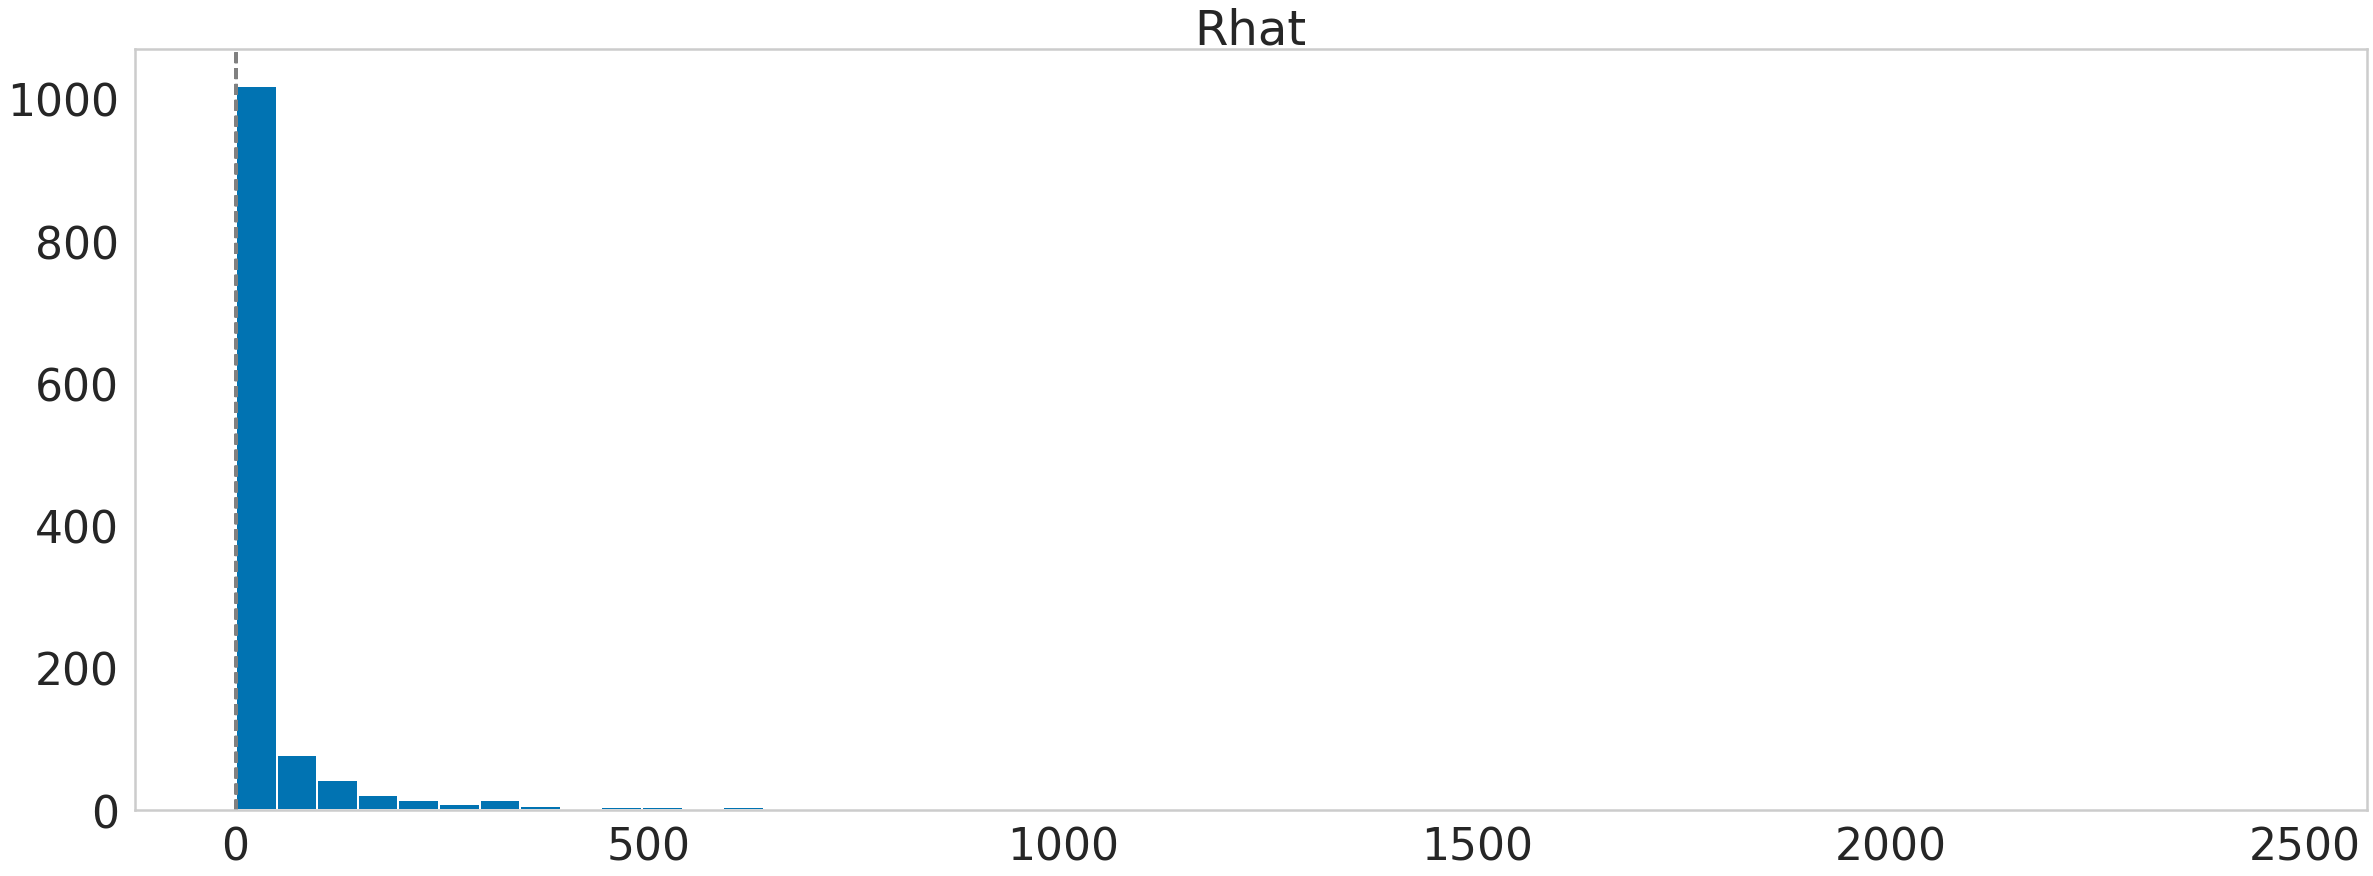

In [12]:
plt.figure()
plt.title('Rhat')
plt.hist(rhat_ls_unnorm.values(),bins = 50)
plt.axvline(1.05,color="gray",linestyle="--",label=0.1)
plt.axvline(0.5,color="gray",linestyle="--",label=0.1)
plt.axvline(1,color="gray",linestyle="--",label=0.1)
plt.grid()


(array([903., 131.,  70.,  39.,  20.,  19.,   5.,  11.,   8.,   4.,   1.,
          7.,   2.,   3.,   2.,   2.,   1.,   3.,   0.,   1.,   0.,   1.,
          0.,   1.,   1.,   0.,   2.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   1.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   1.,   0.,   0.,   1.]),
 array([0.01010102, 0.01085841, 0.01161581, 0.01237321, 0.01313061,
        0.01388801, 0.01464541, 0.01540281, 0.01616021, 0.01691761,
        0.01767501, 0.01843241, 0.01918981, 0.01994721, 0.02070461,
        0.02146201, 0.02221941, 0.02297681, 0.02373421, 0.0244916 ,
        0.025249  , 0.0260064 , 0.0267638 , 0.0275212 , 0.0282786 ,
        0.029036  , 0.0297934 , 0.0305508 , 0.0313082 , 0.0320656 ,
        0.032823  , 0.0335804 , 0.0343378 , 0.0350952 , 0.0358526 ,
        0.03661   , 0.0373674 , 0.03812479, 0.03888219, 0.03963959,
        0.04039699, 0.04115439, 0.04191179, 0.04266919, 0.04342659,
        0.04418399, 0.04494139, 0.04569879, 0.

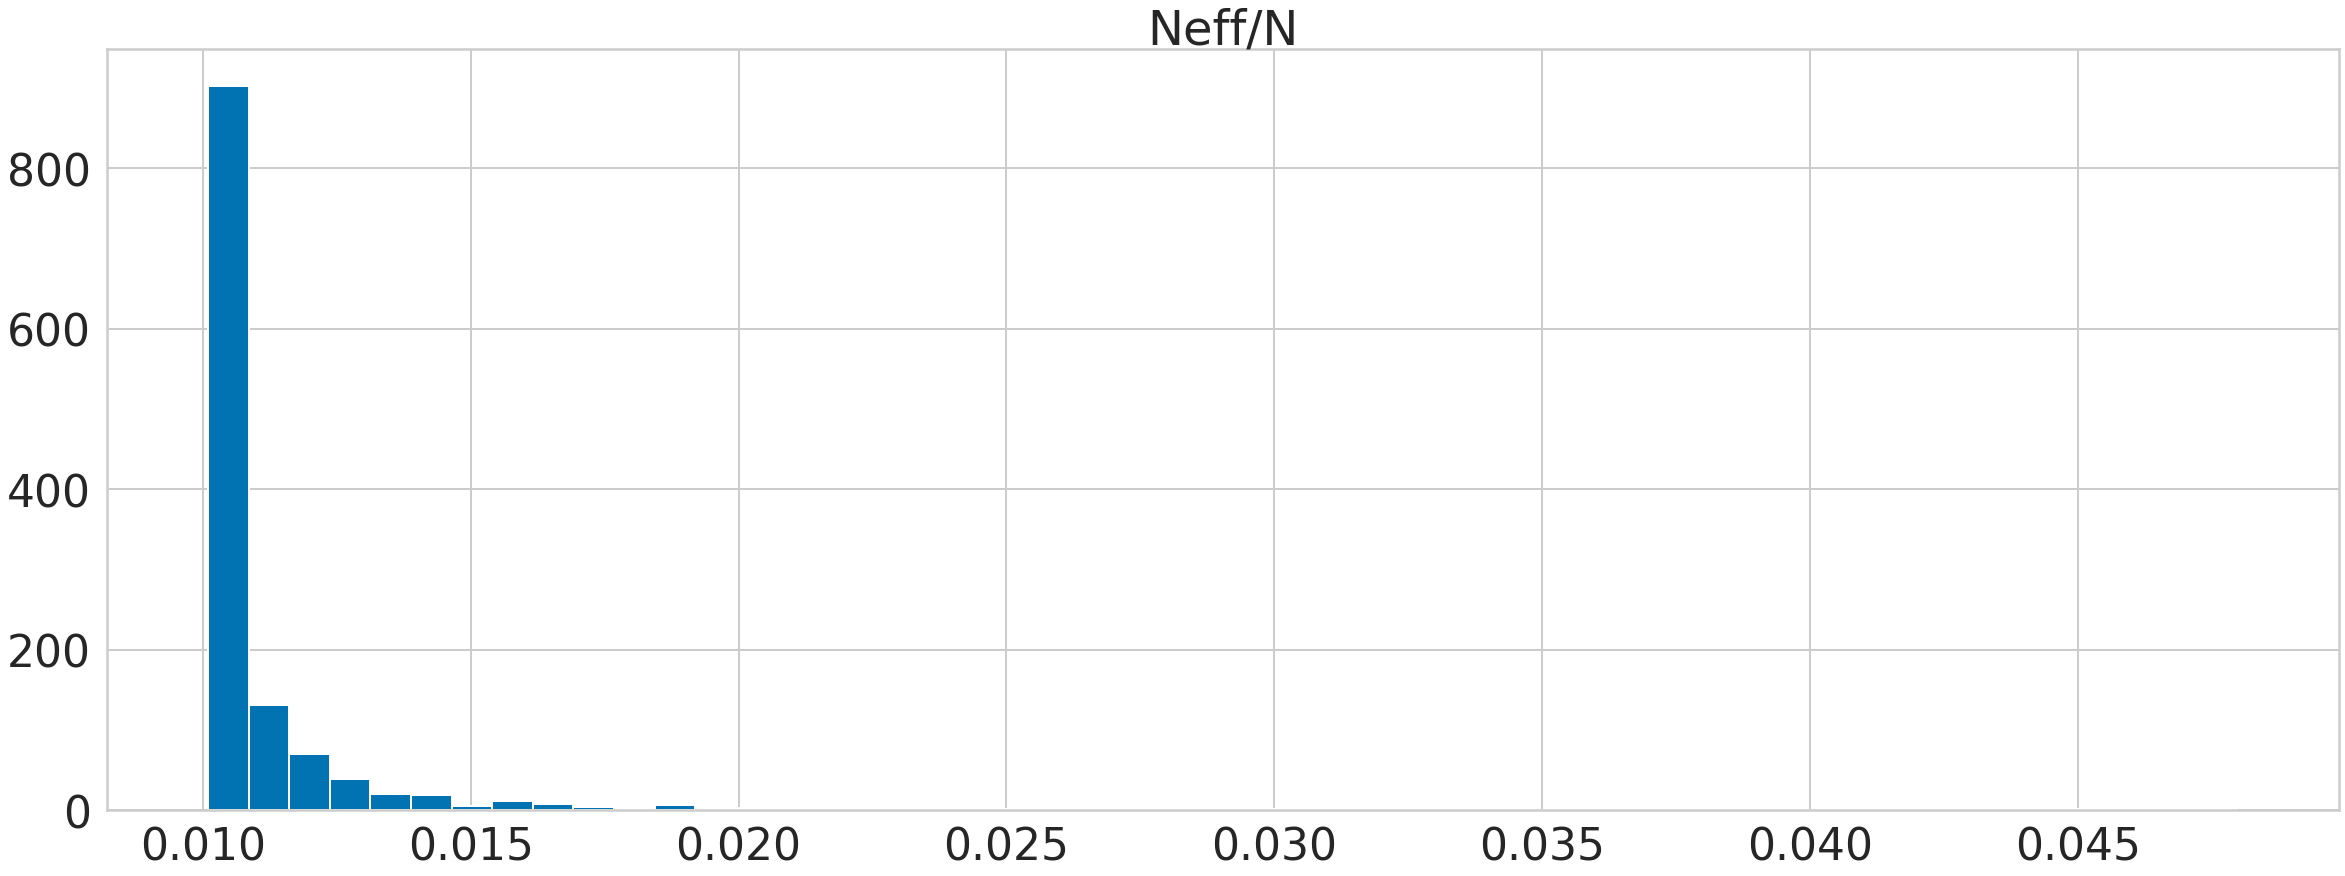

In [13]:
plt.figure()
plt.title('Neff/N')
plt.hist(n_eff_ls_unnorm.values(),bins = 50)
# plt.xlim([0,1])
# plt.axvline(0.1,color="gray",linestyle="--",label=0.1)
# plt.axvline(0.5,color="gray",linestyle="--",label=0.1)
# plt.axvline(1,color="gray",linestyle="--",label=0.1)
# plt.gca().invert_yaxis()

## sorting

In [14]:
sim = fitted.sim
n_chains = sim['chains']
ns_save = sim['n_save']
ns_warmup2 = sim['warmup2']
ns_kept = [s - w for s, w in zip(sim['n_save'], sim['warmup2'])]

n_samples = int(min(ns_kept))

In [15]:
extract = ["F","G"]
results = fitted.extract(pars=extract, permuted=False, inc_warmup=True)

In [16]:
results["F"].shape

(100, 4, 3, 74)

In [17]:


analysis.merge_chains(results, n=n_samples)  # extract last n draws from each chain

slicy = slice(-n_chains, None)

results_unnorm_sorted,indices = analysis.sort_by_Z_contribution(results, take=slicy, metric="cityblock")



Sorting sample sizes: (4, 3, 74) (4, 337, 3)


100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 200/200 [00:00<00:00, 2635.99it/s]

There are 4 possible orderings
Each ordering has appeared: [1 1 1 1]
Sorting starts...


In [18]:
F_unnorm_sorted= results_unnorm_sorted["F"].reshape(n_samples,n_chains,results_unnorm_sorted["F"].shape[1],results_unnorm_sorted["F"].shape[2])

G_unnorm_sorted = results_unnorm_sorted["G"].reshape(n_samples,n_chains,results_unnorm_sorted["G"].shape[1],results_unnorm_sorted["G"].shape[2])


In [19]:


rhat_ls_unnorm_sorted = {}
pars = sim['fnames_oi']
# par_n_dict = {}
# for n, par in enumerate(pars):
#     par_n_dict[par] = n
    
for name in tqdm(pars):
    if name[0]=="F":

        rhat_ls_unnorm_sorted[name] = split_potential_scale_reduction_sorted(n_samples,n_chains,F_unnorm_sorted,int(name.split(",")[0].split("[")[1]) - 1,int(name.split(",")[1].split("]")[0]) - 1)
    if name[0]=="G":

        rhat_ls_unnorm_sorted[name] = split_potential_scale_reduction_sorted(n_samples,n_chains,G_unnorm_sorted,int(name.split(",")[0].split("[")[1]) - 1,int(name.split(",")[1].split("]")[0]) - 1)
rhat_ls_unnorm_sorted

100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1240/1240 [00:00<00:00, 2890.46it/s]


{'G[1,1]': 9.450321176957303,
 'G[2,1]': 4.686491572616576,
 'G[3,1]': 2.635459002536471,
 'G[4,1]': 8.427265798227056,
 'G[5,1]': 5.357848211738147,
 'G[6,1]': 6.231074817248553,
 'G[7,1]': 2.500530950059002,
 'G[8,1]': 2.188639571063268,
 'G[9,1]': 3.19719286229367,
 'G[10,1]': 5.63717409736917,
 'G[11,1]': 2.547958990733269,
 'G[12,1]': 13.63496836952474,
 'G[13,1]': 1.466249019527888,
 'G[14,1]': 30.1782508853786,
 'G[15,1]': 2.136639367909094,
 'G[16,1]': 3.8068525429480737,
 'G[17,1]': 1.7642447913383592,
 'G[18,1]': 11.218984746692657,
 'G[19,1]': 3.211963242612458,
 'G[20,1]': 6.549313007478307,
 'G[21,1]': 4.1897944020816205,
 'G[22,1]': 1.1394347787013783,
 'G[23,1]': 3.4647732665802478,
 'G[24,1]': 87.22547018181277,
 'G[25,1]': 1.1278853459226819,
 'G[26,1]': 3.8817576996123115,
 'G[27,1]': 16.022338572203317,
 'G[28,1]': 11.24114492564736,
 'G[29,1]': 4.008124037990729,
 'G[30,1]': 4.568429854346092,
 'G[31,1]': 5.450154146887719,
 'G[32,1]': 3.16284527866784,
 'G[33,1]': 

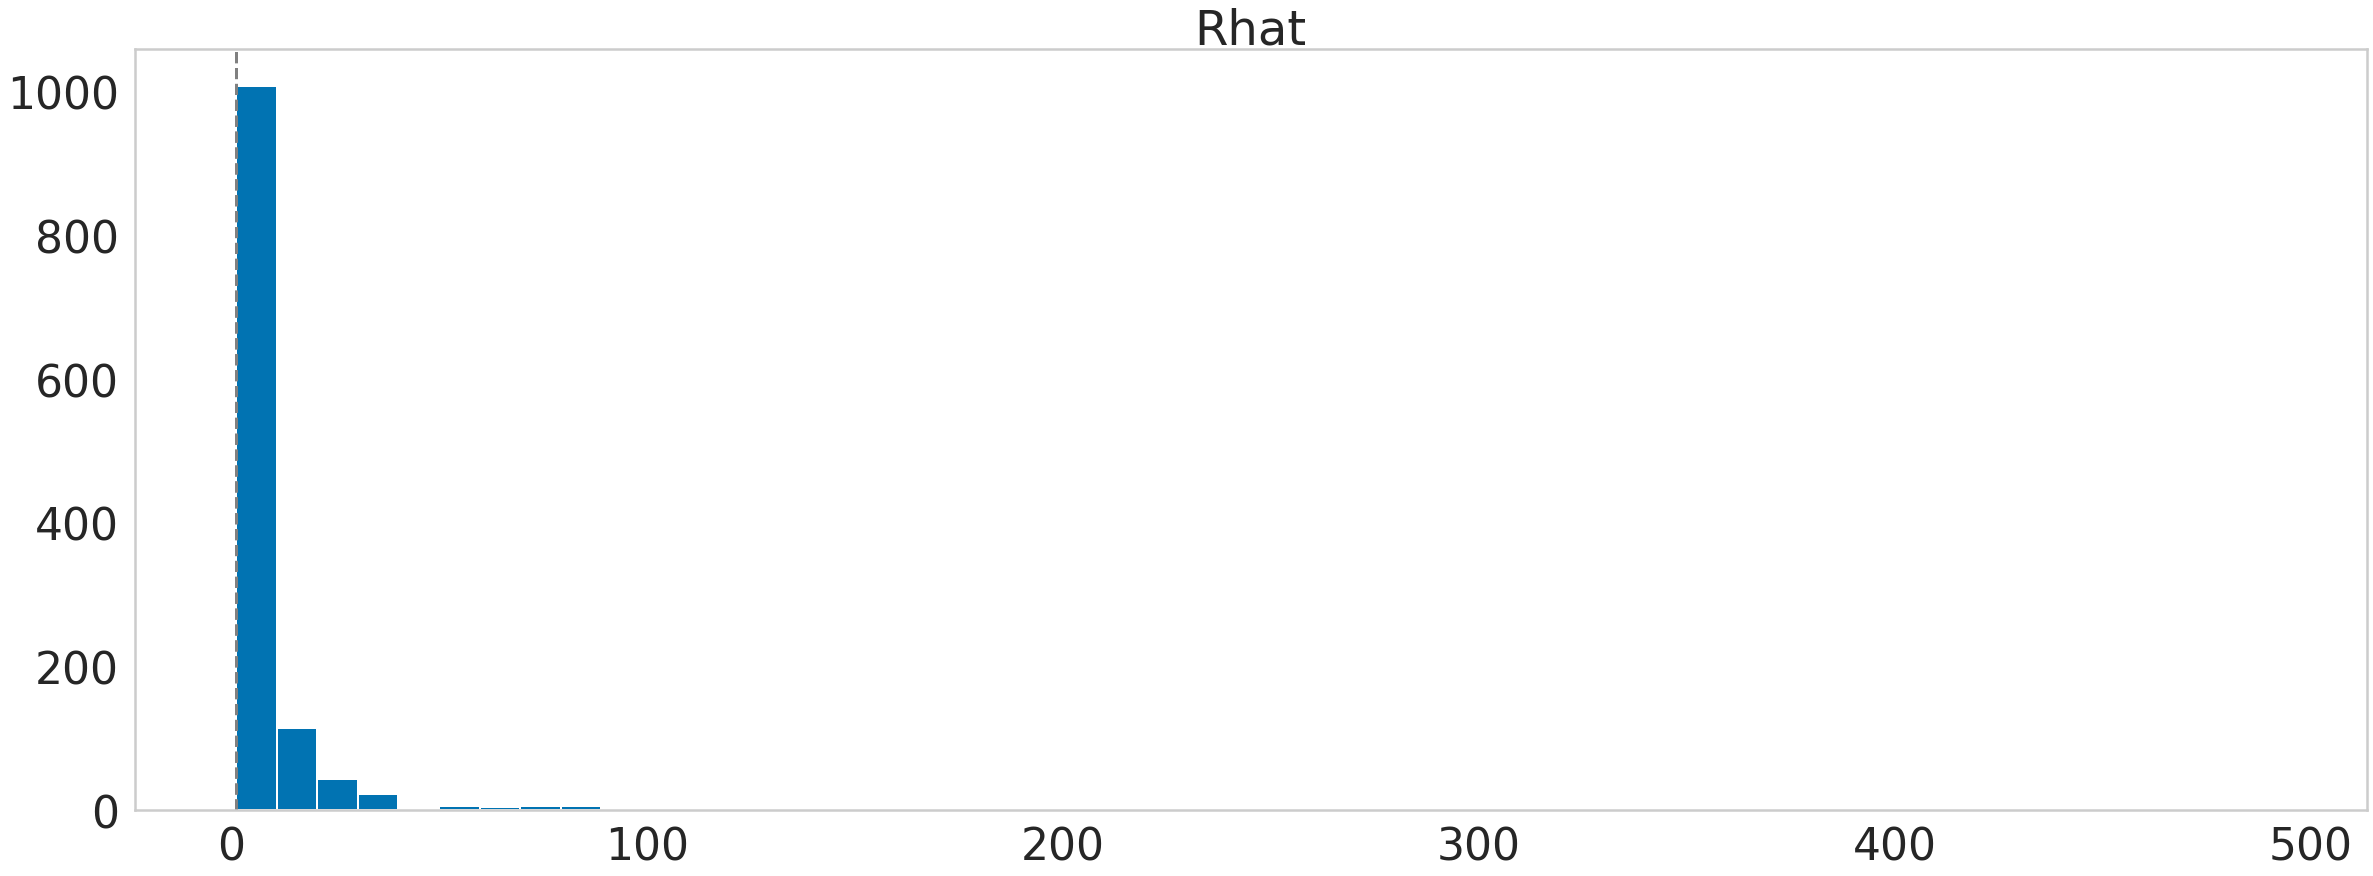

In [20]:
plt.figure()
plt.title('Rhat')
plt.hist(rhat_ls_unnorm_sorted.values(),bins = 50)
plt.axvline(1.05,color="gray",linestyle="--",label=0.1)
# plt.axvline(0.5,color="gray",linestyle="--",label=0.1)
plt.axvline(1,color="gray",linestyle="--",label=0.1)
plt.grid()


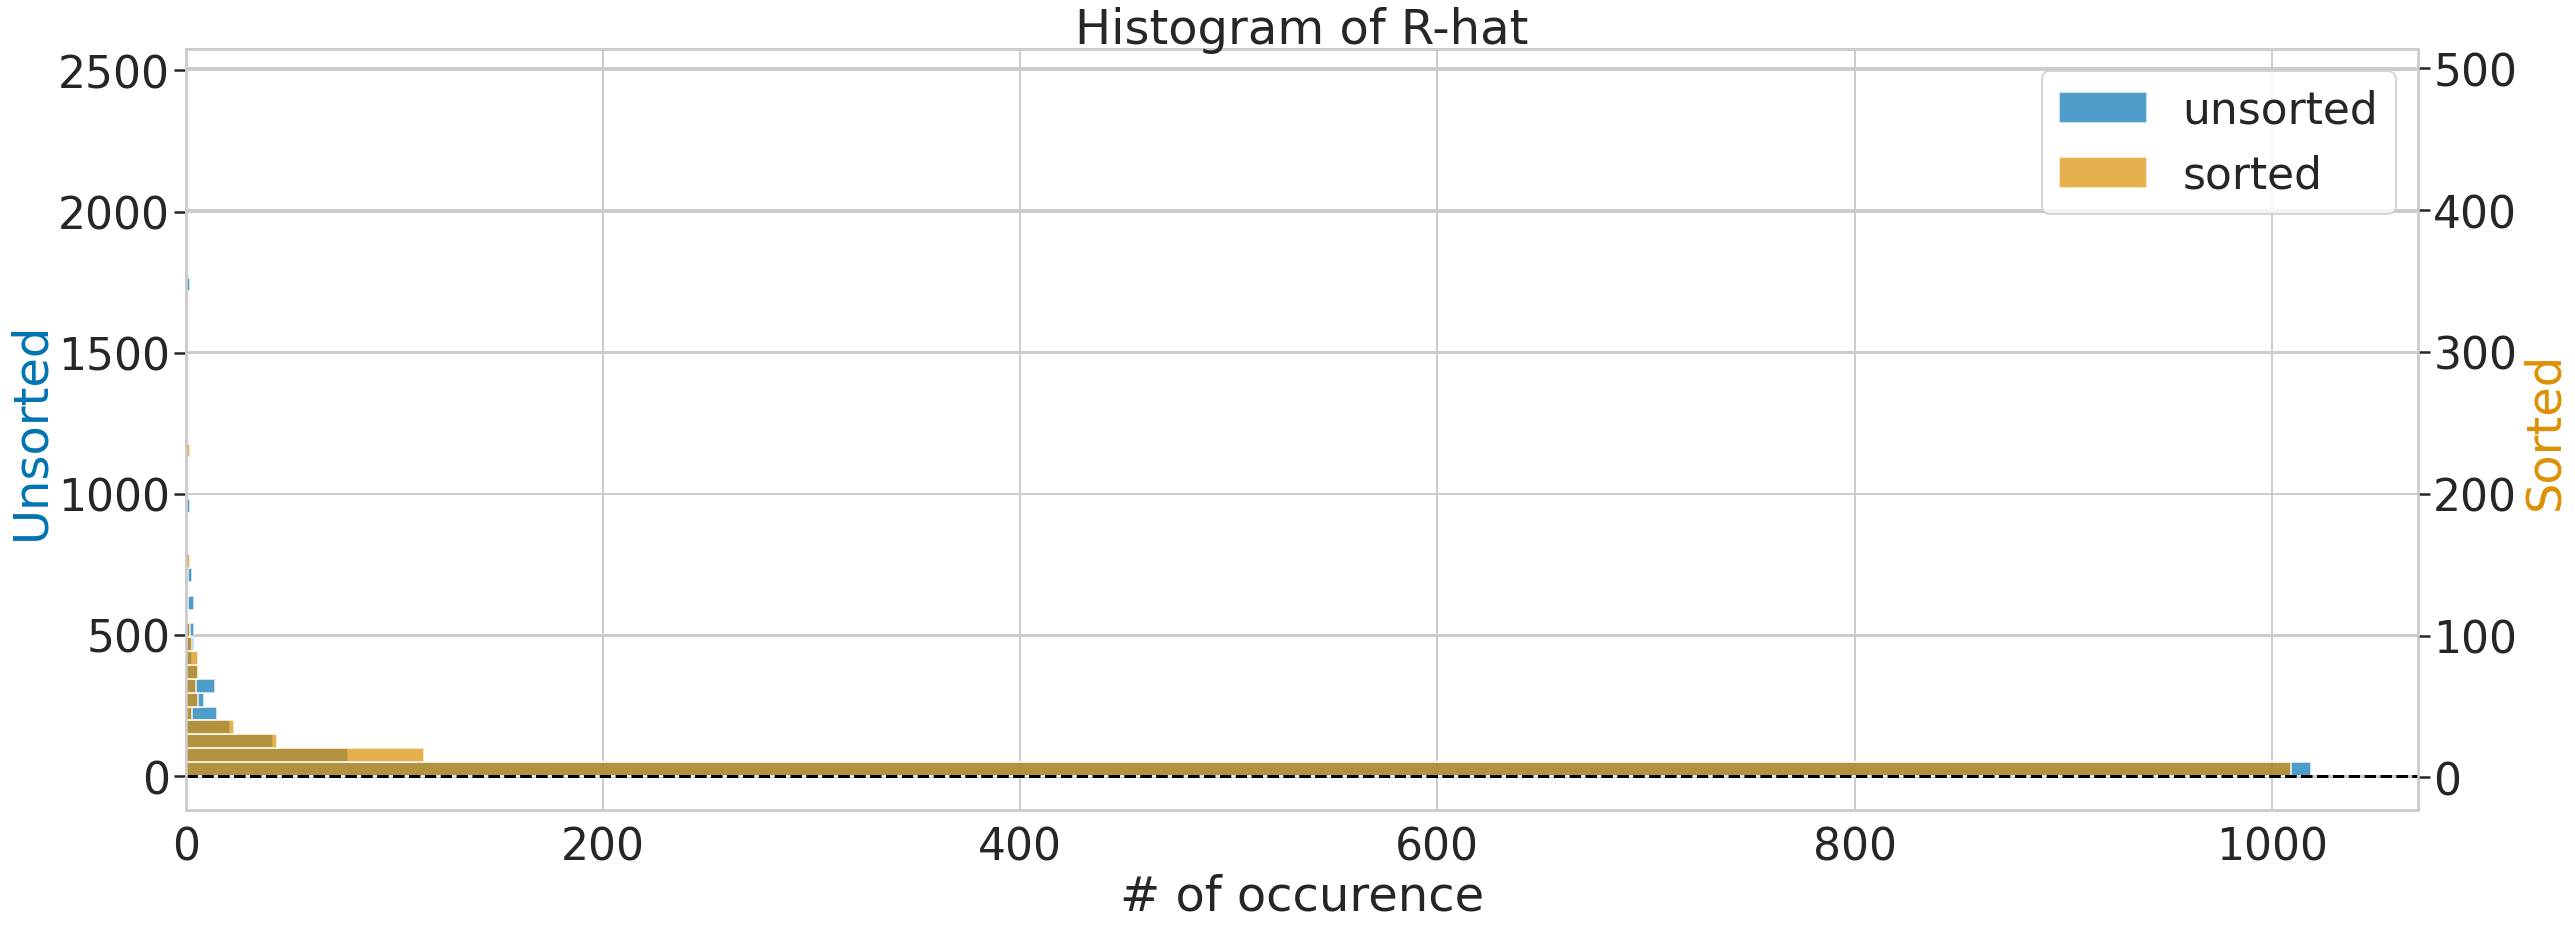

In [21]:
# create figure and axis objects with subplots()
fig,ax = plt.subplots()
palette = sns.color_palette(n_colors=2)
# make a plot
ax.hist(rhat_ls_unnorm.values(),bins = 50,color=palette[0],alpha=0.7,label="unsorted",orientation='horizontal')
# set x-axis label
ax.set_xlabel("# of occurence")
# set y-axis label
ax.set_ylabel("Unsorted",color=palette[0])
# twin object for two different y-axis on the sample plot
ax2=ax.twinx()
# make a plot with different y-axis using second axis object
ax2.hist(rhat_ls_unnorm_sorted.values(),bins = 50,color=palette[1],alpha=0.7,label="sorted",orientation='horizontal')
ax2.set_ylabel("Sorted",color=palette[1])


lines, labels = ax.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax2.legend(lines + lines2, labels + labels2, loc=0)

plt.axhline(1.05,color="black",linestyle="--")
plt.axhline(1,color="black",linestyle="--")
# plt.legend()
plt.title("Histogram of R-hat")
plt.show()


# Diagnositics on normalized dataset

In [22]:
loader = "benchmark"
preprocessing = "basic"
init_function = diagnostics.init_nothing


In [23]:
data, meta, extra = loaders[loader](Path(datafile))
data["p"] = n_factor
data, meta, extra = preprocessing_functions[preprocessing](data, meta, extra)
fitted_norm = loaded_model.sampling(data=data, iter=iterations, init=init_function, chains=n_chains, 
                               n_jobs=n_chains, seed=seed,control={"adapt_delta":delta, "max_treedepth":treedepth})


Gradient evaluation took 0 seconds
1000 transitions using 10 leapfrog steps per transition would take 0 seconds.
Adjust your expectations accordingly!


         three stages of adaptation as currently configured.
         Reducing each adaptation stage to 15%/75%/10% of
         the given number of warmup iterations:
           init_buffer = 7
           adapt_window = 38
           term_buffer = 5


Gradient evaluation took 0 seconds
1000 transitions using 10 leapfrog steps per transition would take 0 seconds.
Adjust your expectations accordingly!


         three stages of adaptation as currently configured.
         Reducing each adaptation stage to 15%/75%/10% of
         the given number of warmup iterations:
           init_buffer = 7
           adapt_window = 38
           term_buffer = 5


Gradient evaluation took 0.01 seconds
1000 transitions using 10 leapfrog steps per transition would take 100 seconds.
Adjust your expectations accordingly!


         three stages of adapta

Informational Message: The current Metropolis proposal is about to be rejected because of the following issue:Informational Message: The current Metropolis proposal is about to be rejected because of the following issue:

Exception: cauchy_lpdf: Location parameter[2] is inf, but must be finite!  (in 'unknown file name' at line 40)
Exception: cauchy_lpdf: Location parameter[1] is inf, but must be finite!  (in 'unknown file name' at line 40)


If this warning occurs sporadically, such as for highly constrained variable types like covariance matrices, then the sampler is fine,If this warning occurs sporadically, such as for highly constrained variable types like covariance matrices, then the sampler is fine,

but if this warning occurs often then your model may be either severely ill-conditioned or misspecified.but if this warning occurs often then your model may be either severely ill-conditioned or misspecified.



Informational Message: The current Metropolis proposal is about to be re

Iteration: 30 / 100 [ 30%]  (Warmup)
Iteration: 40 / 100 [ 40%]  (Warmup)
Iteration: 20 / 100 [ 20%]  (Warmup)
Iteration: 50 / 100 [ 50%]  (Warmup)
Iteration: 51 / 100 [ 51%]  (Sampling)
Iteration: 40 / 100 [ 40%]  (Warmup)
Iteration: 30 / 100 [ 30%]  (Warmup)
Iteration: 60 / 100 [ 60%]  (Sampling)
Iteration: 40 / 100 [ 40%]  (Warmup)
Iteration: 50 / 100 [ 50%]  (Warmup)
Iteration: 51 / 100 [ 51%]  (Sampling)
Iteration: 70 / 100 [ 70%]  (Sampling)
Iteration: 50 / 100 [ 50%]  (Warmup)
Iteration: 51 / 100 [ 51%]  (Sampling)
Iteration: 60 / 100 [ 60%]  (Sampling)
Iteration: 80 / 100 [ 80%]  (Sampling)
Iteration: 30 / 100 [ 30%]  (Warmup)
Iteration: 60 / 100 [ 60%]  (Sampling)
Iteration: 40 / 100 [ 40%]  (Warmup)
Iteration: 90 / 100 [ 90%]  (Sampling)
Iteration: 70 / 100 [ 70%]  (Sampling)
Iteration: 100 / 100 [100%]  (Sampling)

 Elapsed Time: 0.38 seconds (Warm-up)
               0.42 seconds (Sampling)
               0.8 seconds (Total)

Iteration: 80 / 100 [ 80%]  (Sampling)
Iteration:

To run all diagnostics call pystan.check_hmc_diagnostics(fit)



 Elapsed Time: 0.83 seconds (Warm-up)
               0.44 seconds (Sampling)
               1.27 seconds (Total)



In [24]:
checks = {"n_eff", "Rhat", "divergence", "treedepth", "energy"}
pystan.diagnostics.check_hmc_diagnostics(fitted_norm, checks=checks,verbose=False)


{'n_eff': True,
 'Rhat': False,
 'divergence': False,
 'treedepth': True,
 'energy': False}

In [25]:
n_eff_ls_norm  = diagnostics.check_n_eff(fitted_norm, pars=None, verbose=3)
rhat_ls_norm  = diagnostics.check_rhat(fitted_norm, pars=None, verbose=3)

after checking the function I wrote is the same as pystan's

In [26]:
# pystan.diagnostics.check_rhat(fitted_norm, pars=None, verbose=3)

after checking the function I wrote for sorted samples is the same as unsorted

In [27]:
# extract = ["F","G"]
# sim = fitted_norm.sim
# pars = sim['fnames_oi']


# results = fitted_norm.extract(pars=extract, permuted=False, inc_warmup=True)
# analysis.merge_chains(results, n=int(iterations/2))  # extract last n draws from each chain

# F= results["F"].reshape(int(iterations/2),n_chains,results["F"].shape[1],results["F"].shape[2])
# F.shape
# G = results["G"].reshape(int(iterations/2),n_chains,results["G"].shape[1],results["G"].shape[2])
# G.shape

# par_n_dict = {}
# for n, par in enumerate(sim['fnames_oi']):
#     par_n_dict[par] = n

# ratio_ls = {}
# for name in tqdm(pars):
#     if name[0]=="F":
#         n = par_n_dict[name]
#         ratio_ls[name] = split_potential_scale_reduction_sorted(int(iterations/2),n_chains,F,int(name.split(",")[0].split("[")[1]) - 1,int(name.split(",")[1].split("]")[0]) - 1)
#     if name[0]=="G":
#         n = par_n_dict[name]
#         ratio_ls[name] = split_potential_scale_reduction_sorted(int(iterations/2),n_chains,G,int(name.split(",")[0].split("[")[1]) - 1,int(name.split(",")[1].split("]")[0]) - 1)
# ratio_ls

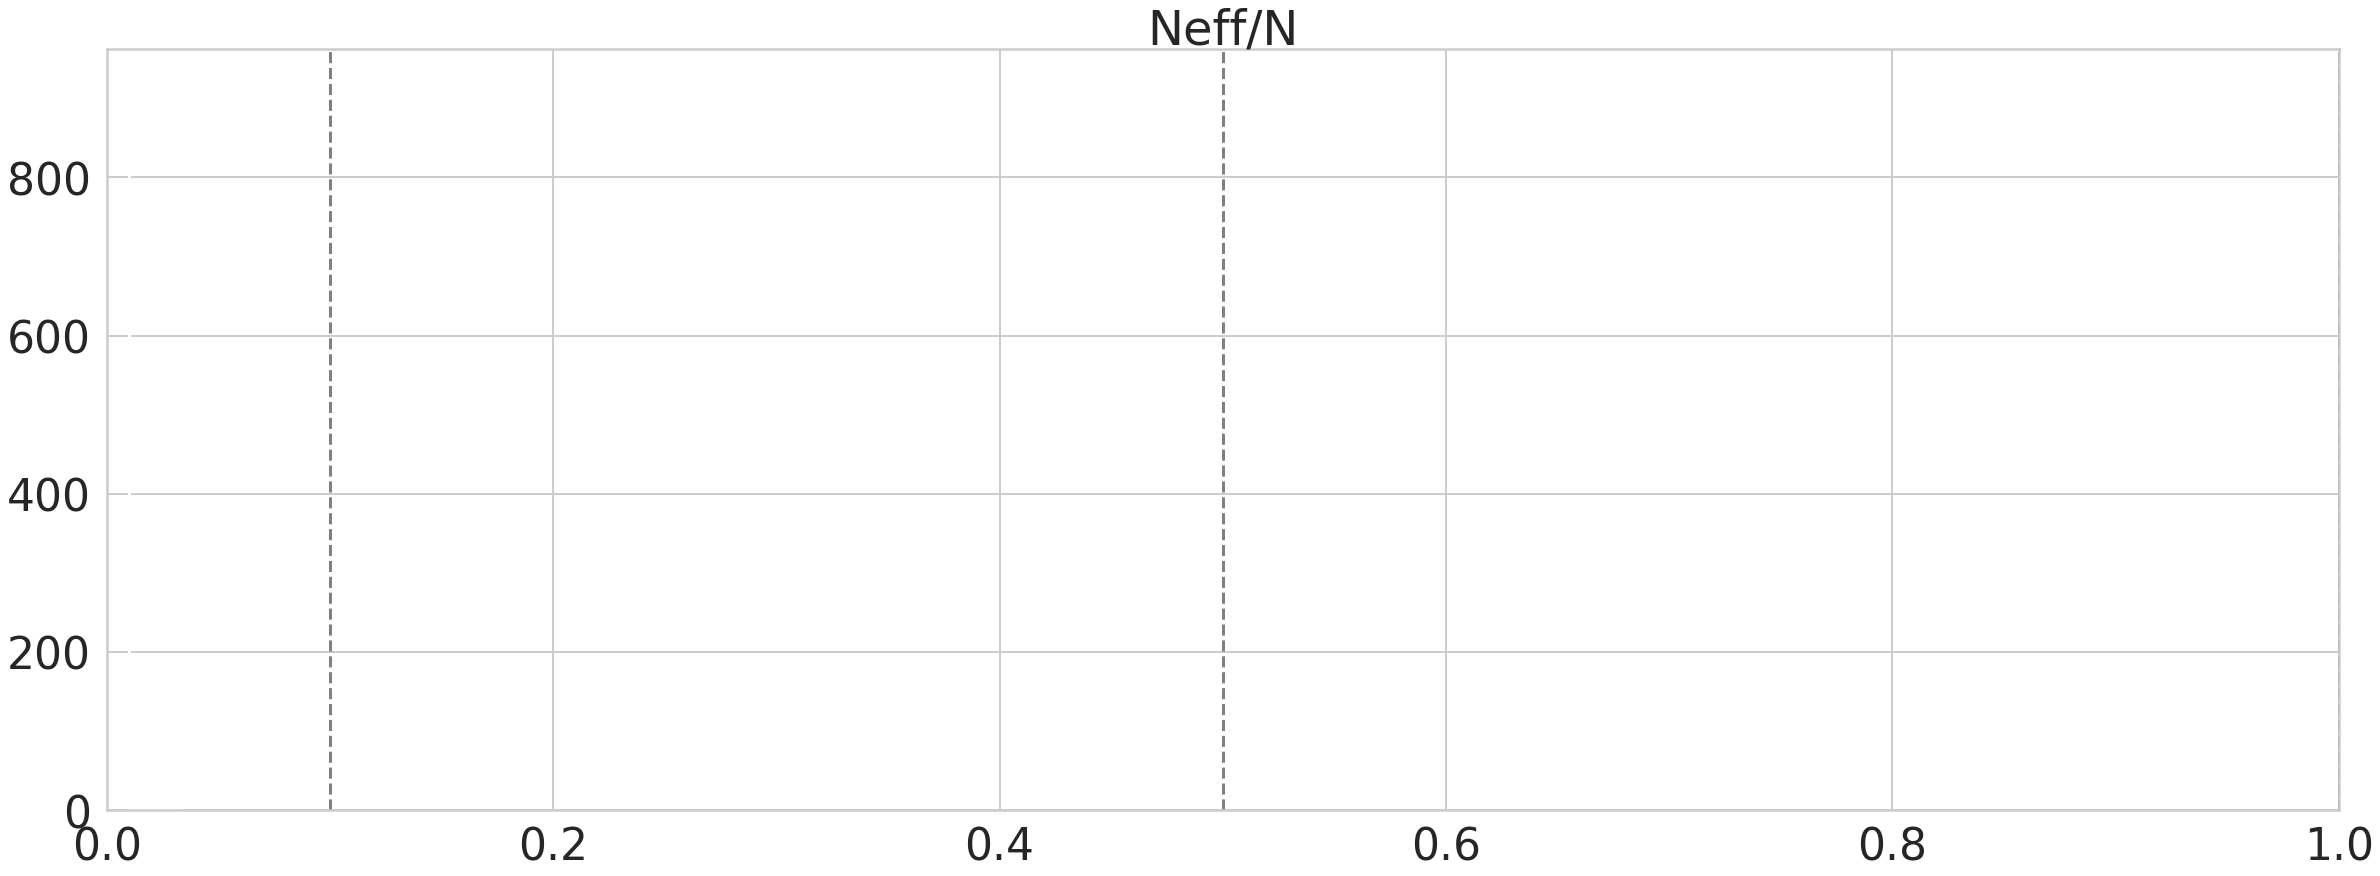

In [28]:
plt.figure()
plt.title('Neff/N')
plt.hist(n_eff_ls_norm.values(),bins = 50)
plt.xlim([0,1])
plt.axvline(0.1,color="gray",linestyle="--",label=0.1)
plt.axvline(0.5,color="gray",linestyle="--",label=0.1)
plt.axvline(1,color="gray",linestyle="--",label=0.1)
# plt.gca().invert_yaxis()

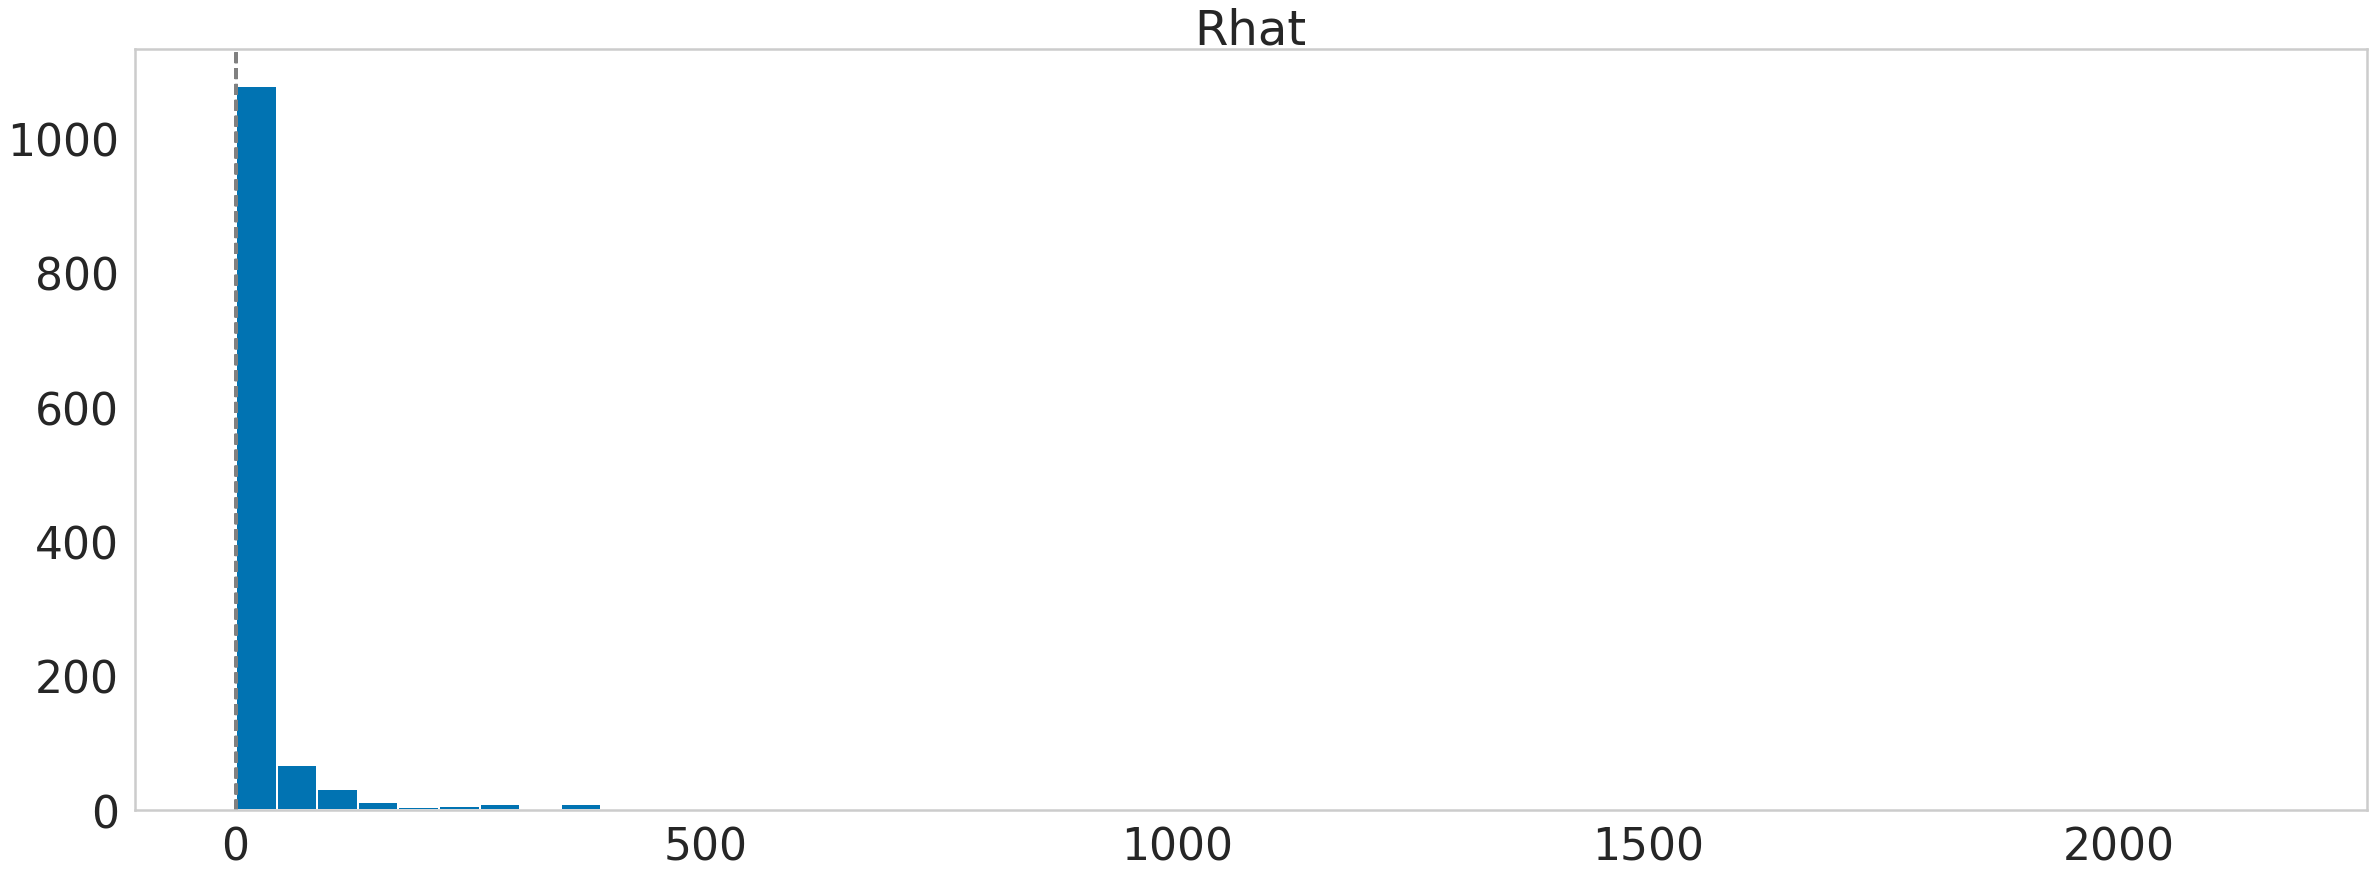

In [29]:

plt.figure()
plt.title('Rhat')
plt.hist(rhat_ls_norm.values(),bins = 50)
plt.axvline(1.05,color="gray",linestyle="--",label=0.1)
plt.axvline(0.5,color="gray",linestyle="--",label=0.1)
plt.axvline(1,color="gray",linestyle="--",label=0.1)
plt.grid()



## sorting

In [30]:
sim = fitted_norm.sim
pars = sim['fnames_oi']

n_chains = sim['chains']
ns_save = sim['n_save']
ns_warmup2 = sim['warmup2']
ns_kept = [s - w for s, w in zip(sim['n_save'], sim['warmup2'])]

n_samples = int(min(ns_kept))

In [31]:
extract = ["F","G","alpha_a","alpha_b"]
results = fitted_norm.extract(pars=extract, permuted=False, inc_warmup=True)

In [32]:


analysis.merge_chains(results, n=n_samples)  # extract last n draws from each chain

slicy = slice(-n_chains, None)

results_sorted,indices = analysis.sort_by_Z_contribution(results, take=slicy, metric="cityblock")



Sorting sample sizes: (4, 3, 74) (4, 337, 3)


100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 200/200 [00:00<00:00, 2457.07it/s]

There are 4 possible orderings
Each ordering has appeared: [1 1 1 1]
Sorting starts...


In [33]:
results = fitted_norm.extract(pars=extract, permuted=False, inc_warmup=True)
analysis.merge_chains(results, n=n_samples)  # extract last n draws from each chain
results

OrderedDict([('F',
              array([[[0.00318411, 0.00405101, 0.00203591, ..., 0.00360163,
                       0.0089557 , 0.00206534],
                      [0.00327053, 0.00388906, 0.00230321, ..., 0.00319567,
                       0.00145454, 0.00303037],
                      [0.00294534, 0.0036954 , 0.00190795, ..., 0.00729787,
                       0.0088389 , 0.00397811]],
              
                     [[0.00479521, 0.01755147, 0.01632901, ..., 0.00035609,
                       0.00269947, 0.00094643],
                      [0.01384316, 0.01349404, 0.02018378, ..., 0.00021402,
                       0.00234037, 0.00076118],
                      [0.01847424, 0.00306814, 0.02159073, ..., 0.00666071,
                       0.00079361, 0.00260622]],
              
                     [[0.00303511, 0.00239434, 0.0032568 , ..., 0.00848622,
                       0.00485454, 0.00318859],
                      [0.005663  , 0.00195905, 0.00589037, ..., 0.00707346,
     

In [34]:
indices.shape

(200, 3)

In [35]:
F_sorted= results_sorted["F"].reshape(n_samples,n_chains,results_sorted["F"].shape[1],results_sorted["F"].shape[2])
F_sorted.shape
G_sorted = results_sorted["G"].reshape(n_samples,n_chains,results_sorted["G"].shape[1],results_sorted["G"].shape[2])
G_sorted.shape

(50, 4, 337, 3)

In [36]:
par_n_dict = {}
for n, par in enumerate(sim['fnames_oi']):
    par_n_dict[par] = n

rhat_ls_norm_sorted = {}

for name in tqdm(pars):
    if name[0]=="F":
        n = par_n_dict[name]
        rhat_ls_norm_sorted[name] = split_potential_scale_reduction_sorted(n_samples,n_chains,F_sorted,int(name.split(",")[0].split("[")[1]) - 1,int(name.split(",")[1].split("]")[0]) - 1)
    if name[0]=="G":
        n = par_n_dict[name]
        rhat_ls_norm_sorted[name] = split_potential_scale_reduction_sorted(n_samples,n_chains,G_sorted,int(name.split(",")[0].split("[")[1]) - 1,int(name.split(",")[1].split("]")[0]) - 1)
        
rhat_ls_norm_sorted

100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1240/1240 [00:00<00:00, 3196.22it/s]


{'G[1,1]': 13.58759400170742,
 'G[2,1]': 3.449946307013222,
 'G[3,1]': 37.89956916502232,
 'G[4,1]': 4.925943258341632,
 'G[5,1]': 10.244665984047167,
 'G[6,1]': 273.84593348464836,
 'G[7,1]': 5.576437991428205,
 'G[8,1]': 8.443752892183177,
 'G[9,1]': 10.469618487889889,
 'G[10,1]': 31.212386210744782,
 'G[11,1]': 50.814151096061224,
 'G[12,1]': 33.21860095887008,
 'G[13,1]': 4.976537320343217,
 'G[14,1]': 5.508666910686968,
 'G[15,1]': 7.800219764412989,
 'G[16,1]': 121.98055957254687,
 'G[17,1]': 29.406737043227942,
 'G[18,1]': 10.274544766835596,
 'G[19,1]': 3.10471450225805,
 'G[20,1]': 6.104396893528899,
 'G[21,1]': 21.108609310856746,
 'G[22,1]': 21.713684266426533,
 'G[23,1]': 115.08713592514836,
 'G[24,1]': 15.825749219476197,
 'G[25,1]': 35.61040828050324,
 'G[26,1]': 15.45314294926413,
 'G[27,1]': 25.767392610259293,
 'G[28,1]': 48.89577063994829,
 'G[29,1]': 77.15001672028939,
 'G[30,1]': 43.020508011780116,
 'G[31,1]': 39.1702490171403,
 'G[32,1]': 9.721599066983268,
 'G[3

In [37]:
for i in rhat_ls_norm_sorted.keys():
    if rhat_ls_norm[i] != rhat_ls_norm_sorted[i]:
        print(i)

G[1,1]
G[2,1]
G[3,1]
G[4,1]
G[5,1]
G[6,1]
G[7,1]
G[8,1]
G[9,1]
G[10,1]
G[11,1]
G[12,1]
G[13,1]
G[14,1]
G[15,1]
G[16,1]
G[17,1]
G[18,1]
G[19,1]
G[20,1]
G[21,1]
G[22,1]
G[23,1]
G[24,1]
G[25,1]
G[26,1]
G[27,1]
G[28,1]
G[29,1]
G[30,1]
G[31,1]
G[32,1]
G[33,1]
G[34,1]
G[35,1]
G[36,1]
G[37,1]
G[38,1]
G[39,1]
G[40,1]
G[41,1]
G[42,1]
G[43,1]
G[44,1]
G[45,1]
G[46,1]
G[47,1]
G[48,1]
G[49,1]
G[50,1]
G[51,1]
G[52,1]
G[53,1]
G[54,1]
G[55,1]
G[56,1]
G[57,1]
G[58,1]
G[59,1]
G[60,1]
G[61,1]
G[62,1]
G[63,1]
G[64,1]
G[65,1]
G[66,1]
G[67,1]
G[68,1]
G[69,1]
G[70,1]
G[71,1]
G[72,1]
G[73,1]
G[74,1]
G[75,1]
G[76,1]
G[77,1]
G[78,1]
G[79,1]
G[80,1]
G[81,1]
G[82,1]
G[83,1]
G[84,1]
G[85,1]
G[86,1]
G[87,1]
G[88,1]
G[89,1]
G[90,1]
G[91,1]
G[92,1]
G[93,1]
G[94,1]
G[95,1]
G[96,1]
G[97,1]
G[98,1]
G[99,1]
G[100,1]
G[101,1]
G[102,1]
G[103,1]
G[104,1]
G[105,1]
G[106,1]
G[107,1]
G[108,1]
G[109,1]
G[110,1]
G[111,1]
G[112,1]
G[113,1]
G[114,1]
G[115,1]
G[116,1]
G[117,1]
G[118,1]
G[119,1]
G[120,1]
G[121,1]
G[122,1]
G[123,1]
G

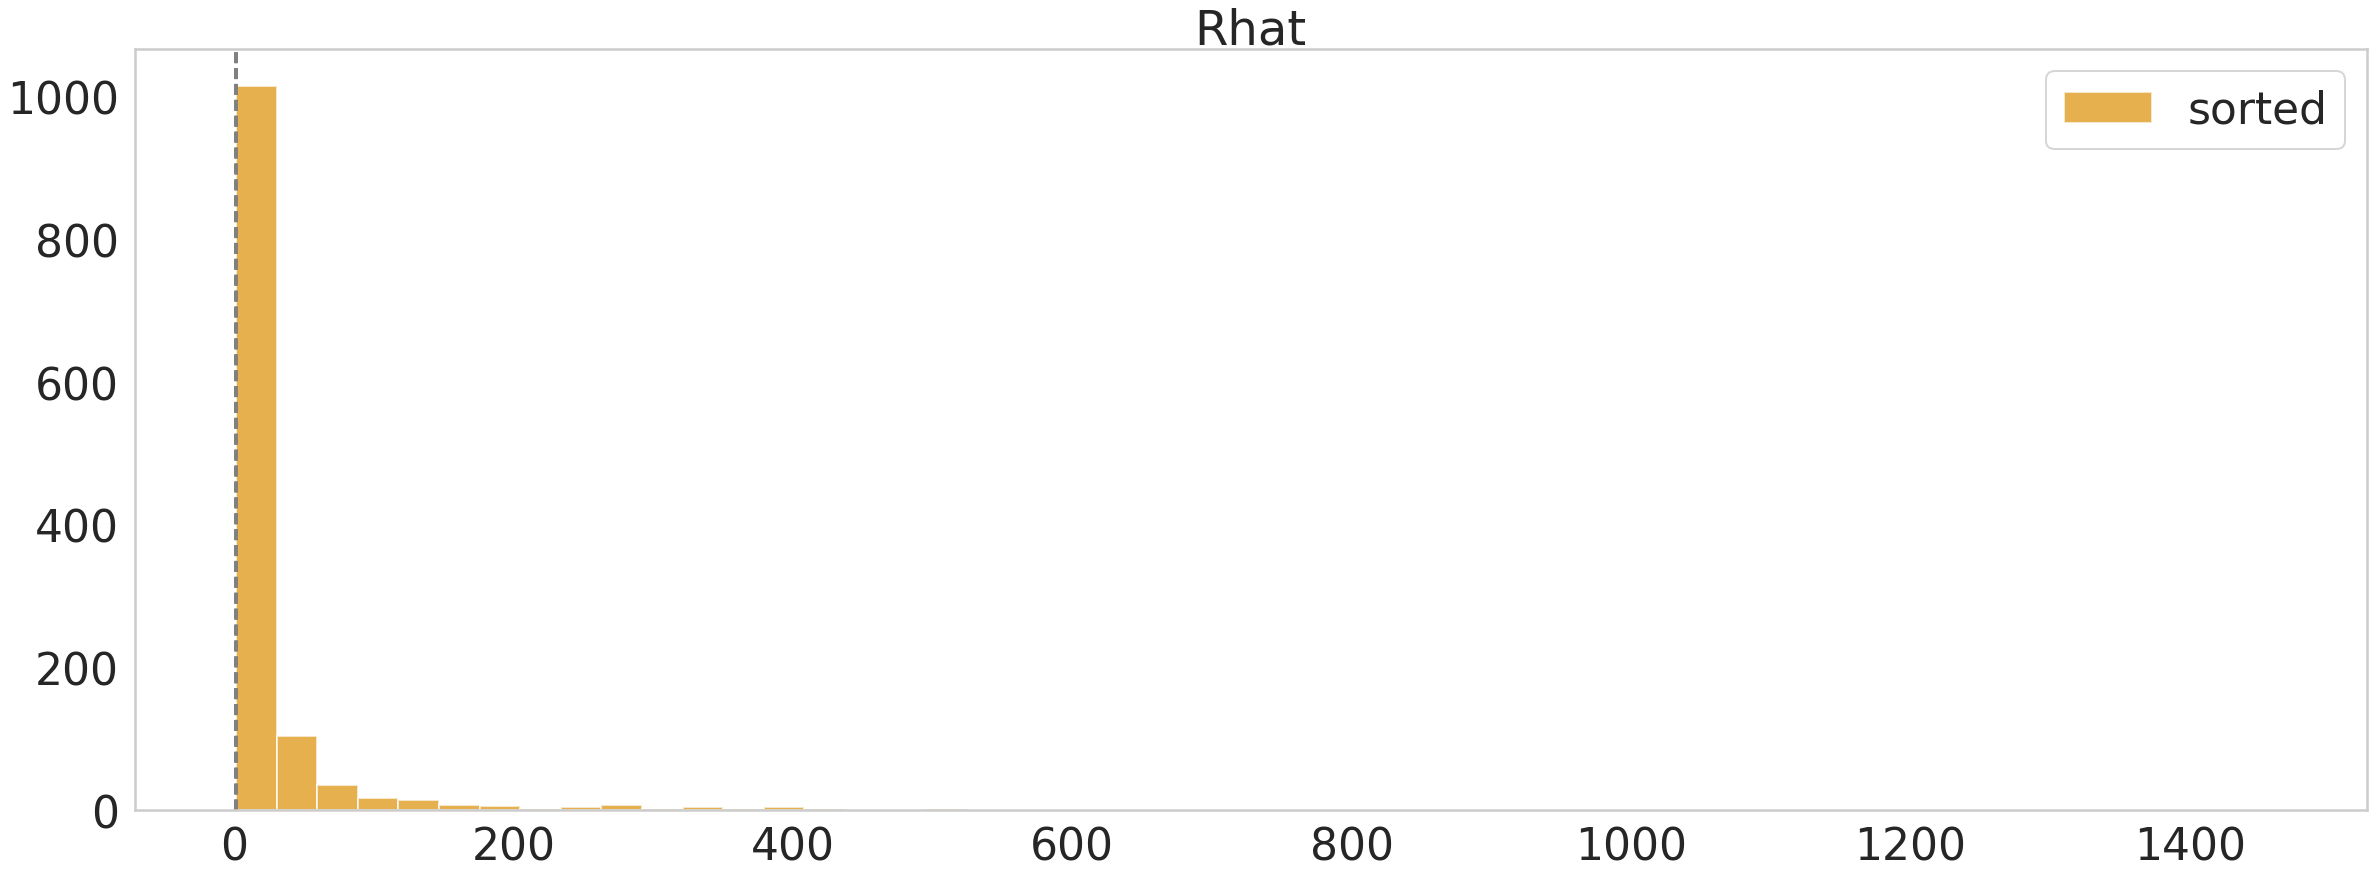

In [38]:
plt.figure()
plt.title('Rhat')
# plt.hist(rhat_ls_norm.values(),bins = 50,color=palette[0],alpha=0.7,label="unsorted")
plt.hist(rhat_ls_norm_sorted.values(),bins = 50,color=palette[1],alpha=0.7,label="sorted")
plt.axvline(1.05,color="gray",linestyle="--")
# plt.axvline(0.5,color="gray",linestyle="--",label=0.1)
plt.axvline(1,color="gray",linestyle="--")
plt.legend()
plt.grid()


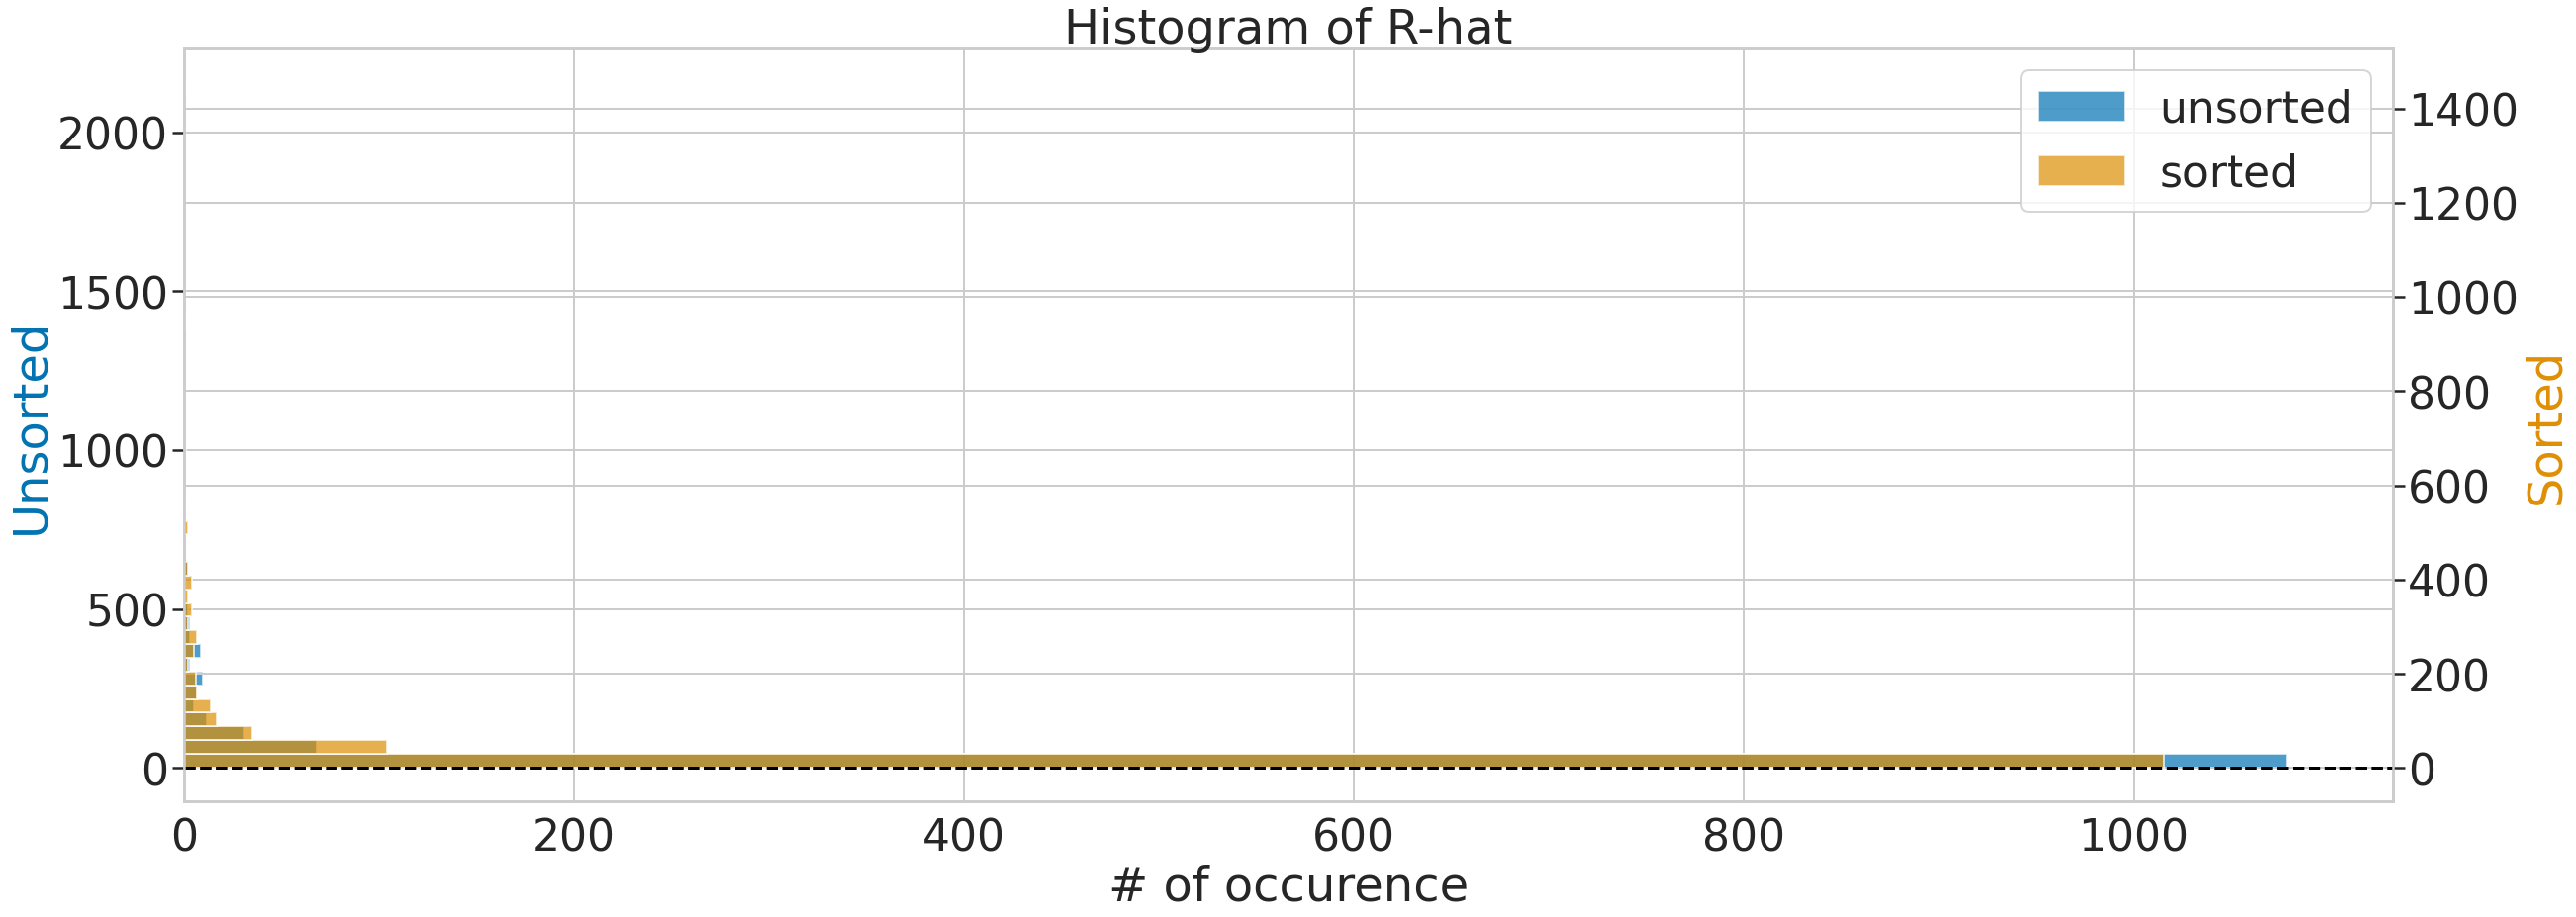

In [39]:
# create figure and axis objects with subplots()
fig,ax = plt.subplots()
# make a plot
ax.hist(rhat_ls_norm.values(),bins = 50,color=palette[0],alpha=0.7,label="unsorted",orientation='horizontal')
# set x-axis label
ax.set_xlabel("# of occurence")
# set y-axis label
ax.set_ylabel("Unsorted",color=palette[0])
# twin object for two different y-axis on the sample plot
ax2=ax.twinx()
# make a plot with different y-axis using second axis object
ax2.hist(rhat_ls_norm_sorted.values(),bins = 50,color=palette[1],alpha=0.7,label="sorted",orientation='horizontal')
ax2.set_ylabel("Sorted",color=palette[1])


lines, labels = ax.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax2.legend(lines + lines2, labels + labels2, loc=0)

plt.axhline(1.05,color="black",linestyle="--")
plt.axhline(1,color="black",linestyle="--")
# plt.legend()
plt.title("Histogram of R-hat")
plt.show()



# Diagnositics on Initilization & Unnormalized

In [40]:
initoptions={'premodel': '/data/user/wu_j1/bamf/models/bamf.stan', 'premodel_options': {'iter': 2000}}

model ='/data/user/wu_j1/bamf/models/bamf.stan'

def model_init():

    preoptions = {}

    if "premodel_options" in initoptions:
        preoptions.update(initoptions["premodel_options"])

    inits = premodel.optimizing(data, **preoptions, as_vector=True,seed=seed)

    return inits

In [41]:
loader = "benchmark"
preprocessing = "nothing"

init_function = model_init
seed = 5
delta = 0.9
treedepth = 12

premodel = None
if "premodel" in initoptions:
    if type(initoptions["premodel"]) is list:
        premodel = []
        for k in initoptions["premodel"]:
            prepicklename = Path(k).with_suffix(".pkl")
            premodel.append(pickle.load(prepicklename.open('rb')))      
    else:
        prepicklename = Path(initoptions["premodel"]).with_suffix(".pkl")
        premodel = pickle.load(prepicklename.open('rb'))


In [42]:
data, meta, extra = loaders[loader](Path(datafile))
data["p"] = n_factor
data, meta, extra = preprocessing_functions[preprocessing](data, meta, extra)
fitted_norm = loaded_model.sampling(data=data, iter=iterations, init=init_function, chains=n_chains, 
                               n_jobs=n_chains, seed=seed,control={"adapt_delta":delta, "max_treedepth":treedepth})

Initial log joint probability = -3.76531e+08
    Iter      log prob        ||dx||      ||grad||       alpha      alpha0  # evals  Notes 
      19  -9.84764e+07       3.48842   9.80355e+06           1           1       35   
    Iter      log prob        ||dx||      ||grad||       alpha      alpha0  # evals  Notes 
      39  -3.76582e+07      0.737889   6.10567e+06       0.415       0.415       62   
    Iter      log prob        ||dx||      ||grad||       alpha      alpha0  # evals  Notes 
      59  -2.12021e+07        1.4147   3.40054e+06           1           1       85   
    Iter      log prob        ||dx||      ||grad||       alpha      alpha0  # evals  Notes 
      79  -1.46253e+07         0.271   1.73561e+06       0.411       0.411      109   
    Iter      log prob        ||dx||      ||grad||       alpha      alpha0  # evals  Notes 
      99  -9.93119e+06      0.551092   1.18278e+06      0.3316           1      131   
    Iter      log prob        ||dx||      ||grad||       alp

Informational Message: The current Metropolis proposal is about to be rejected because of the following issue:
Exception: cauchy_lpdf: Location parameter[3] is inf, but must be finite!  (in 'unknown file name' at line 40)

If this warning occurs sporadically, such as for highly constrained variable types like covariance matrices, then the sampler is fine,
but if this warning occurs often then your model may be either severely ill-conditioned or misspecified.

Informational Message: The current Metropolis proposal is about to be rejected because of the following issue:Informational Message: The current Metropolis proposal is about to be rejected because of the following issue:

Exception: cauchy_lpdf: Location parameter[3] is inf, but must be finite!  (in 'unknown file name' at line 40)
Exception: cauchy_lpdf: Location parameter[3] is inf, but must be finite!  (in 'unknown file name' at line 40)


If this warning occurs sporadically, such as for highly constrained variable types like co

Iteration: 10 / 100 [ 10%]  (Warmup)
Iteration: 10 / 100 [ 10%]  (Warmup)
Iteration: 10 / 100 [ 10%]  (Warmup)
Iteration: 20 / 100 [ 20%]  (Warmup)
Iteration: 20 / 100 [ 20%]  (Warmup)
Iteration: 20 / 100 [ 20%]  (Warmup)
Iteration: 20 / 100 [ 20%]  (Warmup)
Iteration: 30 / 100 [ 30%]  (Warmup)
Iteration: 30 / 100 [ 30%]  (Warmup)
Iteration: 30 / 100 [ 30%]  (Warmup)
Iteration: 30 / 100 [ 30%]  (Warmup)
Iteration: 40 / 100 [ 40%]  (Warmup)
Iteration: 40 / 100 [ 40%]  (Warmup)
Iteration: 40 / 100 [ 40%]  (Warmup)
Iteration: 40 / 100 [ 40%]  (Warmup)
Iteration: 50 / 100 [ 50%]  (Warmup)
Iteration: 51 / 100 [ 51%]  (Sampling)
Iteration: 50 / 100 [ 50%]  (Warmup)
Iteration: 50 / 100 [ 50%]  (Warmup)
Iteration: 51 / 100 [ 51%]  (Sampling)
Iteration: 51 / 100 [ 51%]  (Sampling)
Iteration: 50 / 100 [ 50%]  (Warmup)
Iteration: 51 / 100 [ 51%]  (Sampling)
Iteration: 60 / 100 [ 60%]  (Sampling)
Iteration: 60 / 100 [ 60%]  (Sampling)
Iteration: 60 / 100 [ 60%]  (Sampling)
Iteration: 60 / 100 [ 60

To run all diagnostics call pystan.check_hmc_diagnostics(fit)



 Elapsed Time: 21.85 seconds (Warm-up)
               100.38 seconds (Sampling)
               122.23 seconds (Total)



In [43]:
checks = {"n_eff", "Rhat", "divergence", "treedepth", "energy"}
pystan.diagnostics.check_hmc_diagnostics(fitted_norm, checks=checks,verbose=False)


{'n_eff': True,
 'Rhat': False,
 'divergence': True,
 'treedepth': False,
 'energy': False}

In [44]:
n_eff_ls_norm  = diagnostics.check_n_eff(fitted_norm, pars=None, verbose=3)
rhat_ls_norm  = diagnostics.check_rhat(fitted_norm, pars=None, verbose=3)

after checking the function I wrote is the same as pystan's

In [45]:
# pystan.diagnostics.check_rhat(fitted_norm, pars=None, verbose=3)

after checking the function I wrote for sorted samples is the same as unsorted

In [46]:
# extract = ["F","G"]
# sim = fitted_norm.sim
# pars = sim['fnames_oi']


# results = fitted_norm.extract(pars=extract, permuted=False, inc_warmup=True)
# analysis.merge_chains(results, n=int(iterations/2))  # extract last n draws from each chain

# F= results["F"].reshape(int(iterations/2),n_chains,results["F"].shape[1],results["F"].shape[2])
# F.shape
# G = results["G"].reshape(int(iterations/2),n_chains,results["G"].shape[1],results["G"].shape[2])
# G.shape

# par_n_dict = {}
# for n, par in enumerate(sim['fnames_oi']):
#     par_n_dict[par] = n

# ratio_ls = {}
# for name in tqdm(pars):
#     if name[0]=="F":
#         n = par_n_dict[name]
#         ratio_ls[name] = split_potential_scale_reduction_sorted(int(iterations/2),n_chains,F,int(name.split(",")[0].split("[")[1]) - 1,int(name.split(",")[1].split("]")[0]) - 1)
#     if name[0]=="G":
#         n = par_n_dict[name]
#         ratio_ls[name] = split_potential_scale_reduction_sorted(int(iterations/2),n_chains,G,int(name.split(",")[0].split("[")[1]) - 1,int(name.split(",")[1].split("]")[0]) - 1)
# ratio_ls

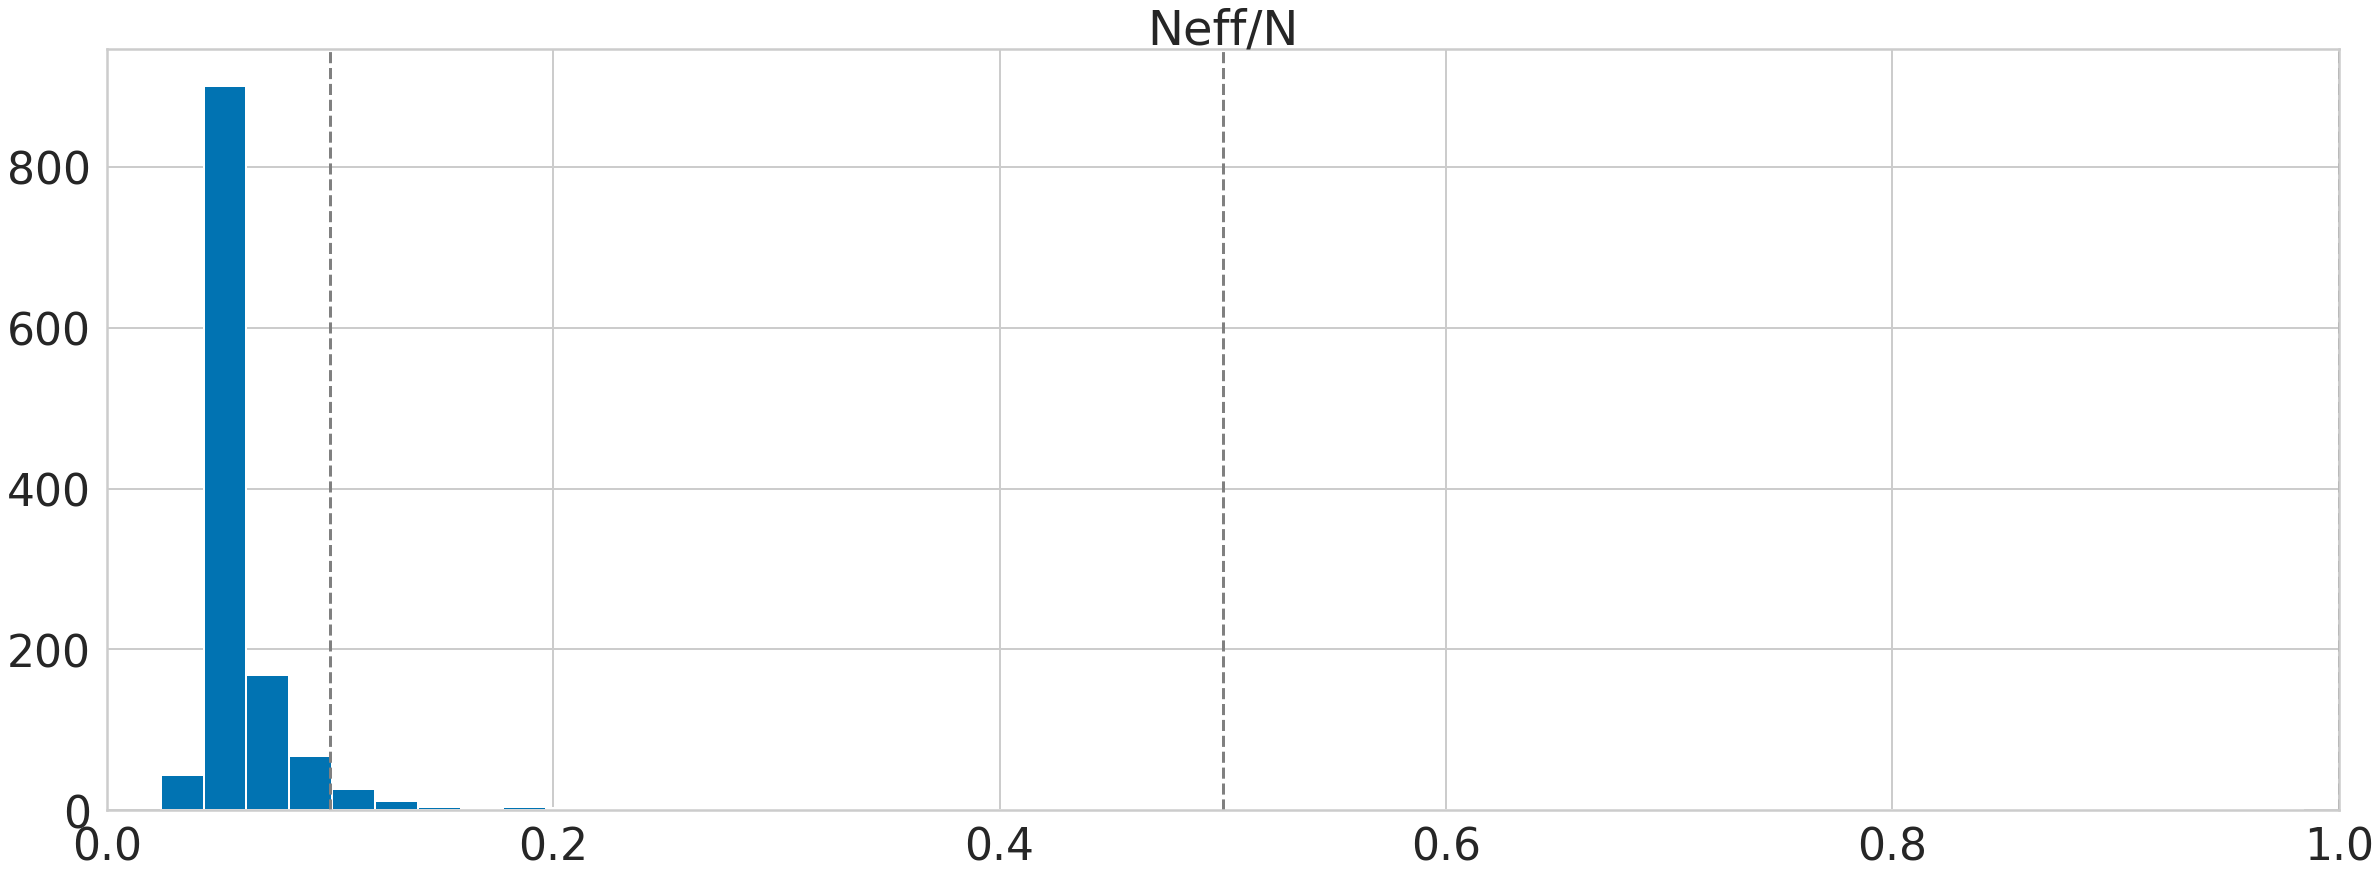

In [47]:
plt.figure()
plt.title('Neff/N')
plt.hist(n_eff_ls_norm.values(),bins = 50)
plt.xlim([0,1])
plt.axvline(0.1,color="gray",linestyle="--",label=0.1)
plt.axvline(0.5,color="gray",linestyle="--",label=0.1)
plt.axvline(1,color="gray",linestyle="--",label=0.1)
# plt.gca().invert_yaxis()

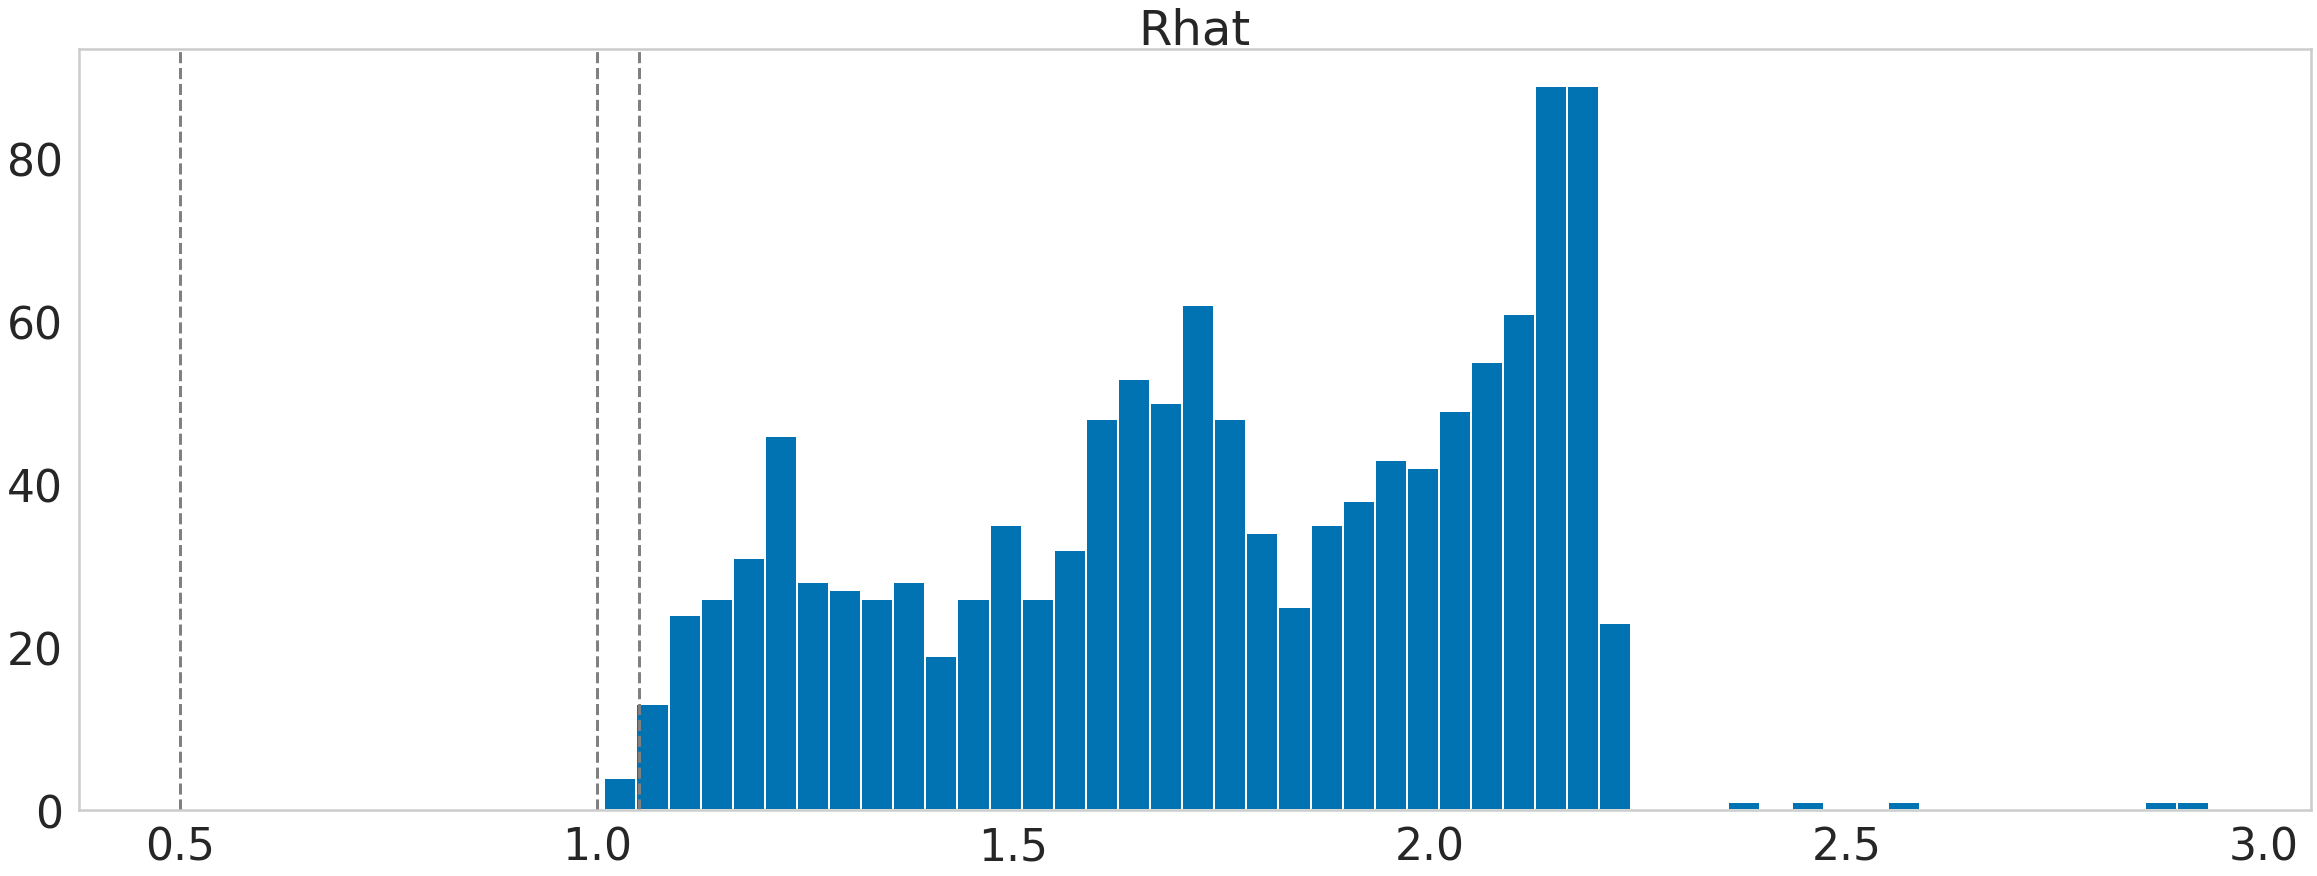

In [48]:

plt.figure()
plt.title('Rhat')
plt.hist(rhat_ls_norm.values(),bins = 50)
plt.axvline(1.05,color="gray",linestyle="--",label=0.1)
plt.axvline(0.5,color="gray",linestyle="--",label=0.1)
plt.axvline(1,color="gray",linestyle="--",label=0.1)
plt.grid()



## sorting

In [49]:
sim = fitted_norm.sim
pars = sim['fnames_oi']

n_chains = sim['chains']
ns_save = sim['n_save']
ns_warmup2 = sim['warmup2']
ns_kept = [s - w for s, w in zip(sim['n_save'], sim['warmup2'])]

n_samples = int(min(ns_kept))

In [50]:
extract = ["F","G","alpha_a","alpha_b"]
results = fitted_norm.extract(pars=extract, permuted=False, inc_warmup=True)

In [51]:


analysis.merge_chains(results, n=n_samples)  # extract last n draws from each chain

slicy = slice(-n_chains, None)

results_sorted,indices = analysis.sort_by_Z_contribution(results, take=slicy, metric="cityblock")



Sorting sample sizes: (4, 3, 74) (4, 337, 3)


100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 200/200 [00:00<00:00, 2626.58it/s]

There are 1 possible orderings
Each ordering has appeared: [4]
Sorting starts...


In [52]:
results = fitted_norm.extract(pars=extract, permuted=False, inc_warmup=True)
analysis.merge_chains(results, n=n_samples)  # extract last n draws from each chain
results

OrderedDict([('F',
              array([[[1.18348803e-02, 5.51043393e-03, 3.72919399e-02, ...,
                       1.53036145e-03, 3.22375887e-03, 1.20758375e-03],
                      [6.87952953e-03, 3.22296779e-03, 1.55319096e-02, ...,
                       6.47766844e-03, 2.86256426e-03, 6.55097316e-04],
                      [2.97305976e-03, 1.00607500e-03, 1.69635390e-02, ...,
                       2.54572806e-04, 2.58266221e-03, 5.95887780e-05]],
              
                     [[1.18699895e-02, 5.51568077e-03, 3.74088431e-02, ...,
                       1.52837227e-03, 3.22591920e-03, 1.20668433e-03],
                      [6.79804067e-03, 3.20440767e-03, 1.51411945e-02, ...,
                       6.59712801e-03, 2.86115346e-03, 6.50274731e-04],
                      [2.77671041e-03, 9.82901574e-04, 1.64630952e-02, ...,
                       1.62594542e-04, 2.54608791e-03, 5.86163930e-05]],
              
                     [[1.18645523e-02, 5.52734660e-03, 3.7428

In [53]:
indices.shape

(200, 3)

In [54]:
F_sorted= results_sorted["F"].reshape(n_samples,n_chains,results_sorted["F"].shape[1],results_sorted["F"].shape[2])
F_sorted.shape
G_sorted = results_sorted["G"].reshape(n_samples,n_chains,results_sorted["G"].shape[1],results_sorted["G"].shape[2])
G_sorted.shape

(50, 4, 337, 3)

In [55]:
par_n_dict = {}
for n, par in enumerate(sim['fnames_oi']):
    par_n_dict[par] = n

rhat_ls_norm_sorted = {}

for name in tqdm(pars):
    if name[0]=="F":
        n = par_n_dict[name]
        rhat_ls_norm_sorted[name] = split_potential_scale_reduction_sorted(n_samples,n_chains,F_sorted,int(name.split(",")[0].split("[")[1]) - 1,int(name.split(",")[1].split("]")[0]) - 1)
    if name[0]=="G":
        n = par_n_dict[name]
        rhat_ls_norm_sorted[name] = split_potential_scale_reduction_sorted(n_samples,n_chains,G_sorted,int(name.split(",")[0].split("[")[1]) - 1,int(name.split(",")[1].split("]")[0]) - 1)
        
rhat_ls_norm_sorted

100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1240/1240 [00:00<00:00, 3218.91it/s]


{'G[1,1]': 1.03521102993822,
 'G[2,1]': 1.2239991940970134,
 'G[3,1]': 1.5691257161518715,
 'G[4,1]': 1.6946343547122953,
 'G[5,1]': 1.592577701417699,
 'G[6,1]': 1.1018263712254726,
 'G[7,1]': 1.456062689434157,
 'G[8,1]': 1.8863414533538625,
 'G[9,1]': 1.9910020081388002,
 'G[10,1]': 1.9278997610992117,
 'G[11,1]': 2.0175016729943476,
 'G[12,1]': 2.1380968557821616,
 'G[13,1]': 1.8722450701612057,
 'G[14,1]': 2.145225634168792,
 'G[15,1]': 2.1003365673033305,
 'G[16,1]': 2.1367491109154835,
 'G[17,1]': 2.0070633096007833,
 'G[18,1]': 2.1740141497876695,
 'G[19,1]': 1.815995034459251,
 'G[20,1]': 1.8496811191500957,
 'G[21,1]': 1.8965788048654533,
 'G[22,1]': 1.8660229257936258,
 'G[23,1]': 1.656001141270584,
 'G[24,1]': 1.9294802167400016,
 'G[25,1]': 1.9545729989348768,
 'G[26,1]': 2.022922118212489,
 'G[27,1]': 2.160340594576415,
 'G[28,1]': 1.988901367552058,
 'G[29,1]': 1.497420206492188,
 'G[30,1]': 1.9693211274882585,
 'G[31,1]': 2.122972428414522,
 'G[32,1]': 2.098900580164205

In [56]:
for i in rhat_ls_norm_sorted.keys():
    if rhat_ls_norm[i] != rhat_ls_norm_sorted[i]:
        print(i)

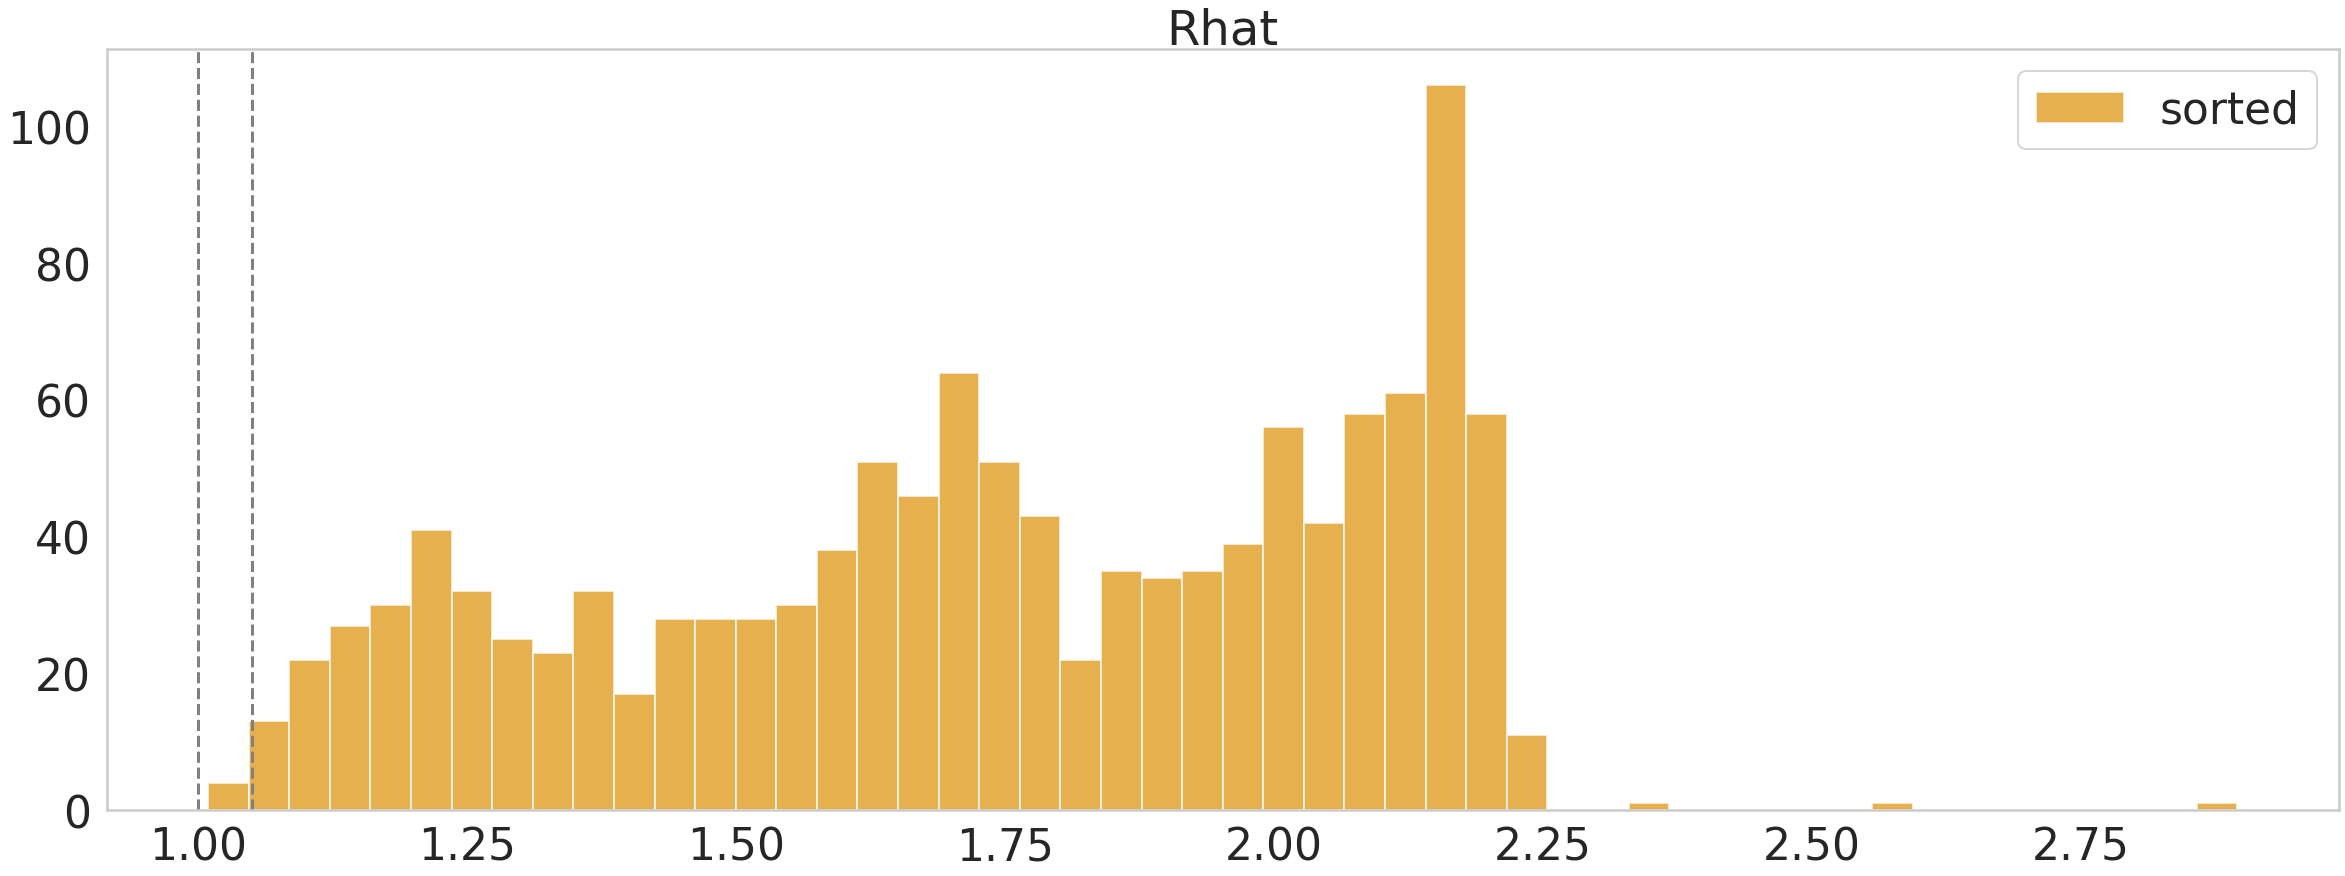

In [57]:
plt.figure()
plt.title('Rhat')
# plt.hist(rhat_ls_norm.values(),bins = 50,color=palette[0],alpha=0.7,label="unsorted")
plt.hist(rhat_ls_norm_sorted.values(),bins = 50,color=palette[1],alpha=0.7,label="sorted")
plt.axvline(1.05,color="gray",linestyle="--")
# plt.axvline(0.5,color="gray",linestyle="--",label=0.1)
plt.axvline(1,color="gray",linestyle="--")
plt.legend()
plt.grid()


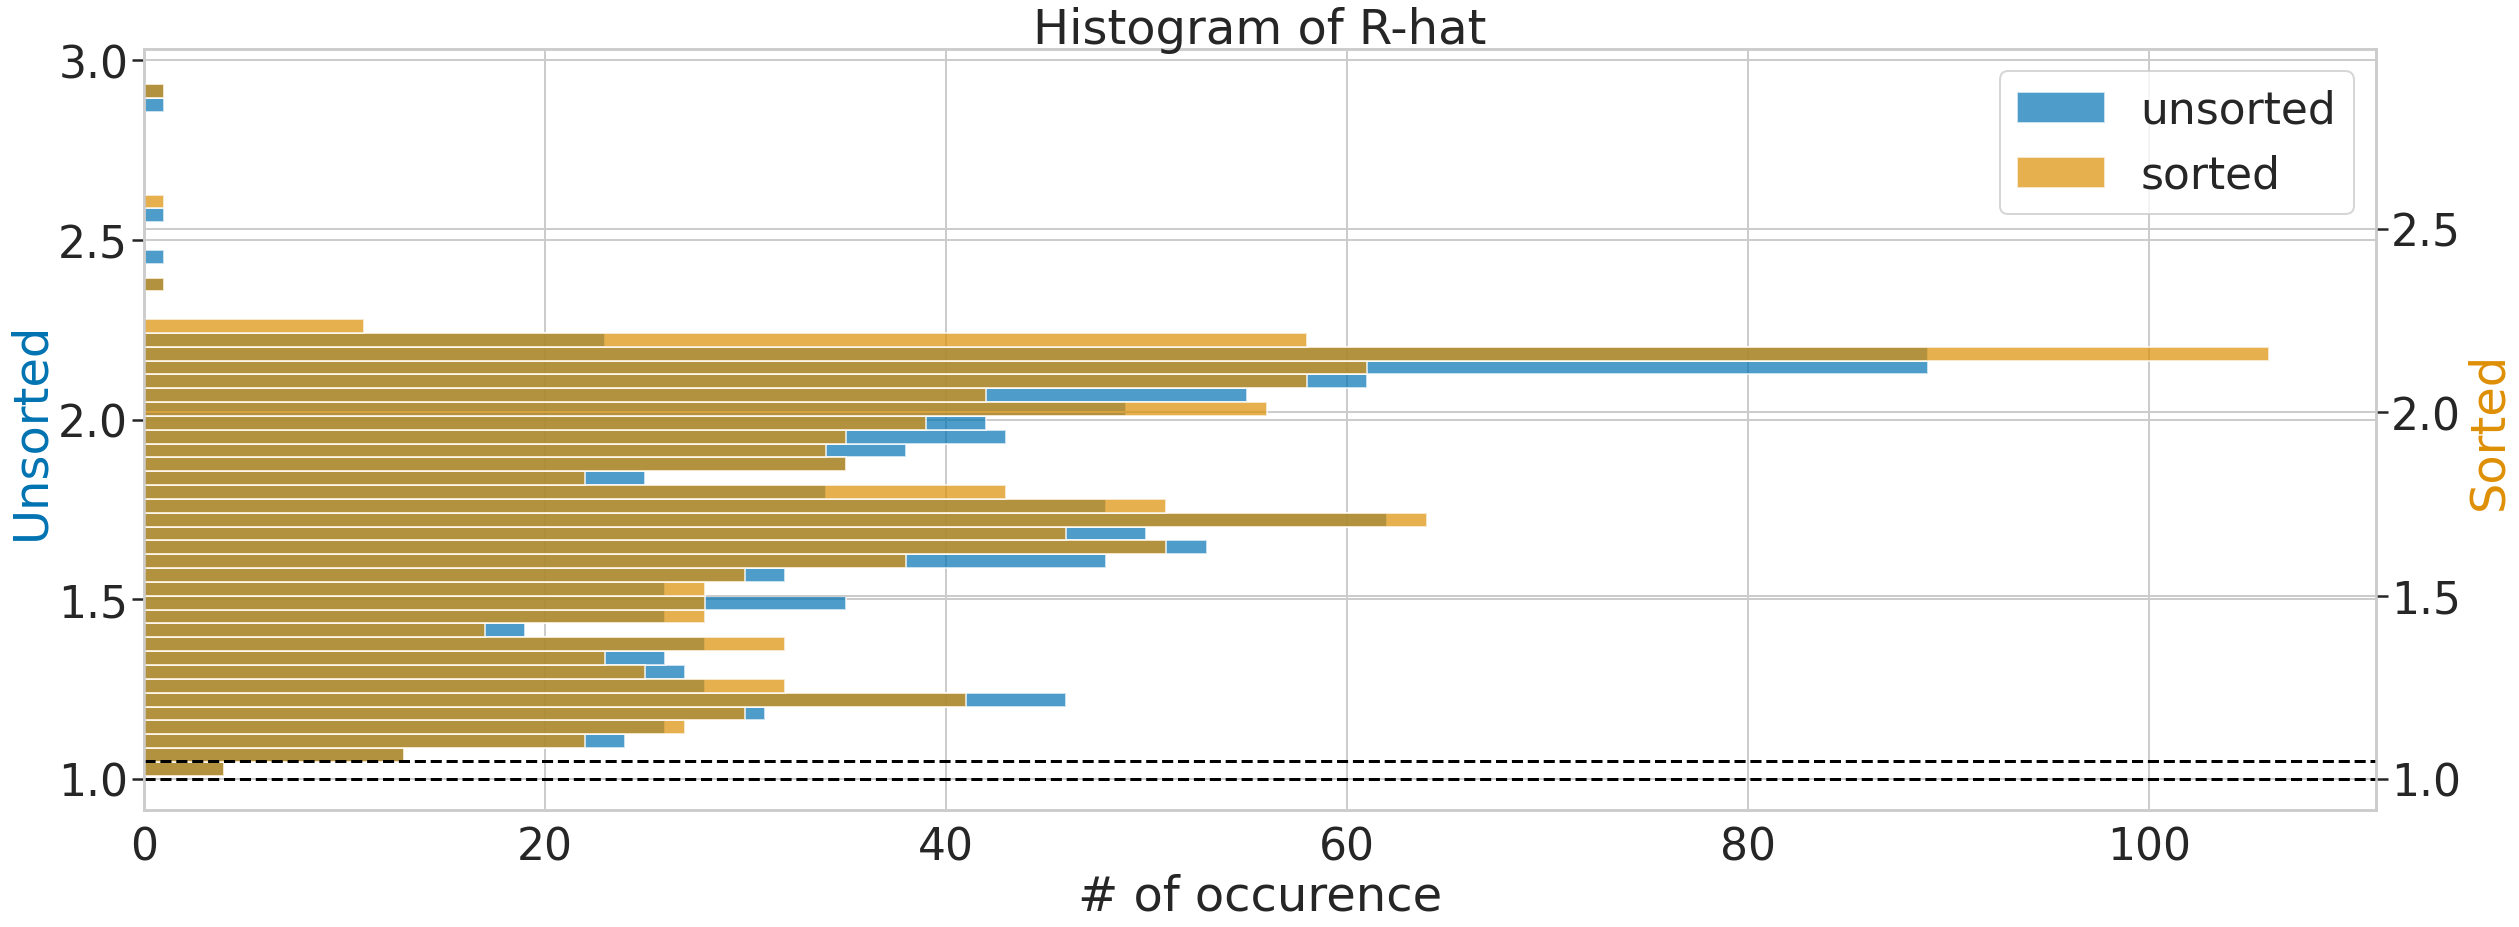

In [58]:
# create figure and axis objects with subplots()
fig,ax = plt.subplots()
palette = sns.color_palette(n_colors=2)
# make a plot
ax.hist(rhat_ls_norm.values(),bins = 50,color=palette[0],alpha=0.7,label="unsorted",orientation='horizontal')
# set x-axis label
ax.set_xlabel("# of occurence")
# set y-axis label
ax.set_ylabel("Unsorted",color=palette[0])
# twin object for two different y-axis on the sample plot
ax2=ax.twinx()
# make a plot with different y-axis using second axis object
ax2.hist(rhat_ls_norm_sorted.values(),bins = 50,color=palette[1],alpha=0.7,label="sorted",orientation='horizontal')
ax2.set_ylabel("Sorted",color=palette[1])


lines, labels = ax.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax2.legend(lines + lines2, labels + labels2, loc=0)

plt.axhline(1.05,color="black",linestyle="--")
plt.axhline(1,color="black",linestyle="--")
# plt.legend()
plt.title("Histogram of R-hat")
plt.show()



# Diagnositics on normalized & initilization

<span style="color:red" > Initilization always failed, so be careful about the seed selection

In [59]:
initoptions={'premodel': '/data/user/wu_j1/bamf/models/bamf.stan', 'premodel_options': {'iter': 2000}}

model ='/data/user/wu_j1/bamf/models/bamf.stan'


In [60]:
def model_init():

    preoptions = {}

    if "premodel_options" in initoptions:
        preoptions.update(initoptions["premodel_options"])

    inits = premodel.optimizing(data, **preoptions, as_vector=True,seed=seed)

    return inits

In [61]:
loader = "benchmark"
preprocessing = "basic"

init_function = model_init
seed = 5
delta = 0.9
treedepth = 12

premodel = None
if "premodel" in initoptions:
    if type(initoptions["premodel"]) is list:
        premodel = []
        for k in initoptions["premodel"]:
            prepicklename = Path(k).with_suffix(".pkl")
            premodel.append(pickle.load(prepicklename.open('rb')))      
    else:
        prepicklename = Path(initoptions["premodel"]).with_suffix(".pkl")
        premodel = pickle.load(prepicklename.open('rb'))

data, meta, extra = loaders[loader](Path(datafile))


In [62]:

data, meta, extra = preprocessing_functions[preprocessing](data, meta, extra)
data["p"] = n_factor
fitted_init = loaded_model.sampling(data=data, iter=iterations, init=init_function, chains=4, 
                               n_jobs=4, seed=seed,control={"adapt_delta":delta, 
                                                            "max_treedepth":treedepth})

Initial log joint probability = -3.74663e+08
    Iter      log prob        ||dx||      ||grad||       alpha      alpha0  # evals  Notes 
      19  -1.73673e+08       2.27871   8.53885e+06           1           1       31   
    Iter      log prob        ||dx||      ||grad||       alpha      alpha0  # evals  Notes 
      39  -9.25067e+07       2.15394   1.06329e+07           1           1       52   
    Iter      log prob        ||dx||      ||grad||       alpha      alpha0  # evals  Notes 
      59  -5.57046e+07       1.37327   3.86125e+06           1           1       74   
    Iter      log prob        ||dx||      ||grad||       alpha      alpha0  # evals  Notes 
      79   -4.1162e+07      0.393961   1.82943e+06      0.3372      0.9944       97   
    Iter      log prob        ||dx||      ||grad||       alpha      alpha0  # evals  Notes 
      99  -3.02508e+07      0.231346   1.35724e+06      0.9296      0.9296      119   
    Iter      log prob        ||dx||      ||grad||       alp

Informational Message: The current Metropolis proposal is about to be rejected because of the following issue:
Exception: cauchy_lpdf: Location parameter[43] is inf, but must be finite!  (in 'unknown file name' at line 40)

If this warning occurs sporadically, such as for highly constrained variable types like covariance matrices, then the sampler is fine,
but if this warning occurs often then your model may be either severely ill-conditioned or misspecified.
Informational Message: The current Metropolis proposal is about to be rejected because of the following issue:

Exception: cauchy_lpdf: Location parameter[43] is inf, but must be finite!  (in 'unknown file name' at line 40)

If this warning occurs sporadically, such as for highly constrained variable types like covariance matrices, then the sampler is fine,
but if this warning occurs often then your model may be either severely ill-conditioned or misspecified.

Informational Message: The current Metropolis proposal is about to be 

Iteration: 10 / 100 [ 10%]  (Warmup)
Iteration: 10 / 100 [ 10%]  (Warmup)
Iteration: 20 / 100 [ 20%]  (Warmup)
Iteration: 30 / 100 [ 30%]  (Warmup)
Iteration: 20 / 100 [ 20%]  (Warmup)
Iteration: 20 / 100 [ 20%]  (Warmup)
Iteration: 20 / 100 [ 20%]  (Warmup)
Iteration: 30 / 100 [ 30%]  (Warmup)
Iteration: 30 / 100 [ 30%]  (Warmup)
Iteration: 40 / 100 [ 40%]  (Warmup)
Iteration: 30 / 100 [ 30%]  (Warmup)
Iteration: 40 / 100 [ 40%]  (Warmup)
Iteration: 40 / 100 [ 40%]  (Warmup)
Iteration: 50 / 100 [ 50%]  (Warmup)
Iteration: 51 / 100 [ 51%]  (Sampling)
Iteration: 40 / 100 [ 40%]  (Warmup)
Iteration: 60 / 100 [ 60%]  (Sampling)
Iteration: 50 / 100 [ 50%]  (Warmup)
Iteration: 50 / 100 [ 50%]  (Warmup)
Iteration: 51 / 100 [ 51%]  (Sampling)
Iteration: 51 / 100 [ 51%]  (Sampling)
Iteration: 60 / 100 [ 60%]  (Sampling)
Iteration: 60 / 100 [ 60%]  (Sampling)
Iteration: 70 / 100 [ 70%]  (Sampling)
Iteration: 70 / 100 [ 70%]  (Sampling)
Iteration: 50 / 100 [ 50%]  (Warmup)
Iteration: 51 / 100 [ 

To run all diagnostics call pystan.check_hmc_diagnostics(fit)



 Elapsed Time: 5.6 seconds (Warm-up)
               6.83 seconds (Sampling)
               12.43 seconds (Total)



In [63]:
fitted_init


For the full summary use 'print(fit)'

Inference for Stan model: anon_model_2a8c9e5f5f57cae2dad9a6cffc04f2c8.
4 chains, each with iter=100; warmup=50; thin=1; 
post-warmup draws per chain=50, total post-warmup draws=200.

          mean se_mean     sd   2.5%    25%    50%    75%  97.5%  n_eff   Rhat
G[1,1]    17.7     0.3   0.48  16.92  17.38  17.57  18.06  18.56      3   3.69
G[2,1]    40.8    0.06   0.18  40.54   40.7  40.77  40.84  41.31      8   2.12
G[3,1]   46.94    0.05   0.17  46.53  46.88  46.95  47.02  47.29     11   1.73
G[4,1]   55.68    0.07   0.22  55.15  55.63  55.74   55.8  56.03      9   2.06
G[5,1]   34.63    0.21   0.57  32.92   34.5  34.79  34.98  35.26      8   2.77
G[6,1]   66.94    0.14   0.34  66.46  66.74  66.89  67.05  67.91      6   2.36
G[7,1]   59.88    0.59   1.78  57.41  58.35  60.07  60.98   63.2      9    2.1
G[8,1]   34.48    0.44   0.76  33.35  33.92  34.33  34.82  35.93      3   3.28
G[9,1]   11.07    0.59   0.99   9.64  10.37  10.73  11.68  13.14  

In [64]:
# preoptions = {}

# if "premodel_options" in initoptions:
#     preoptions.update(initoptions["premodel_options"])
# premodel.optimizing(data, **preoptions, as_vector=True,seed=seed)

In [65]:
n_eff_ls_norm_init  = diagnostics.check_n_eff(fitted_init, pars=None, verbose=3)
rhat_ls_norm_init  = diagnostics.check_rhat(fitted_init, pars=None, verbose=3)

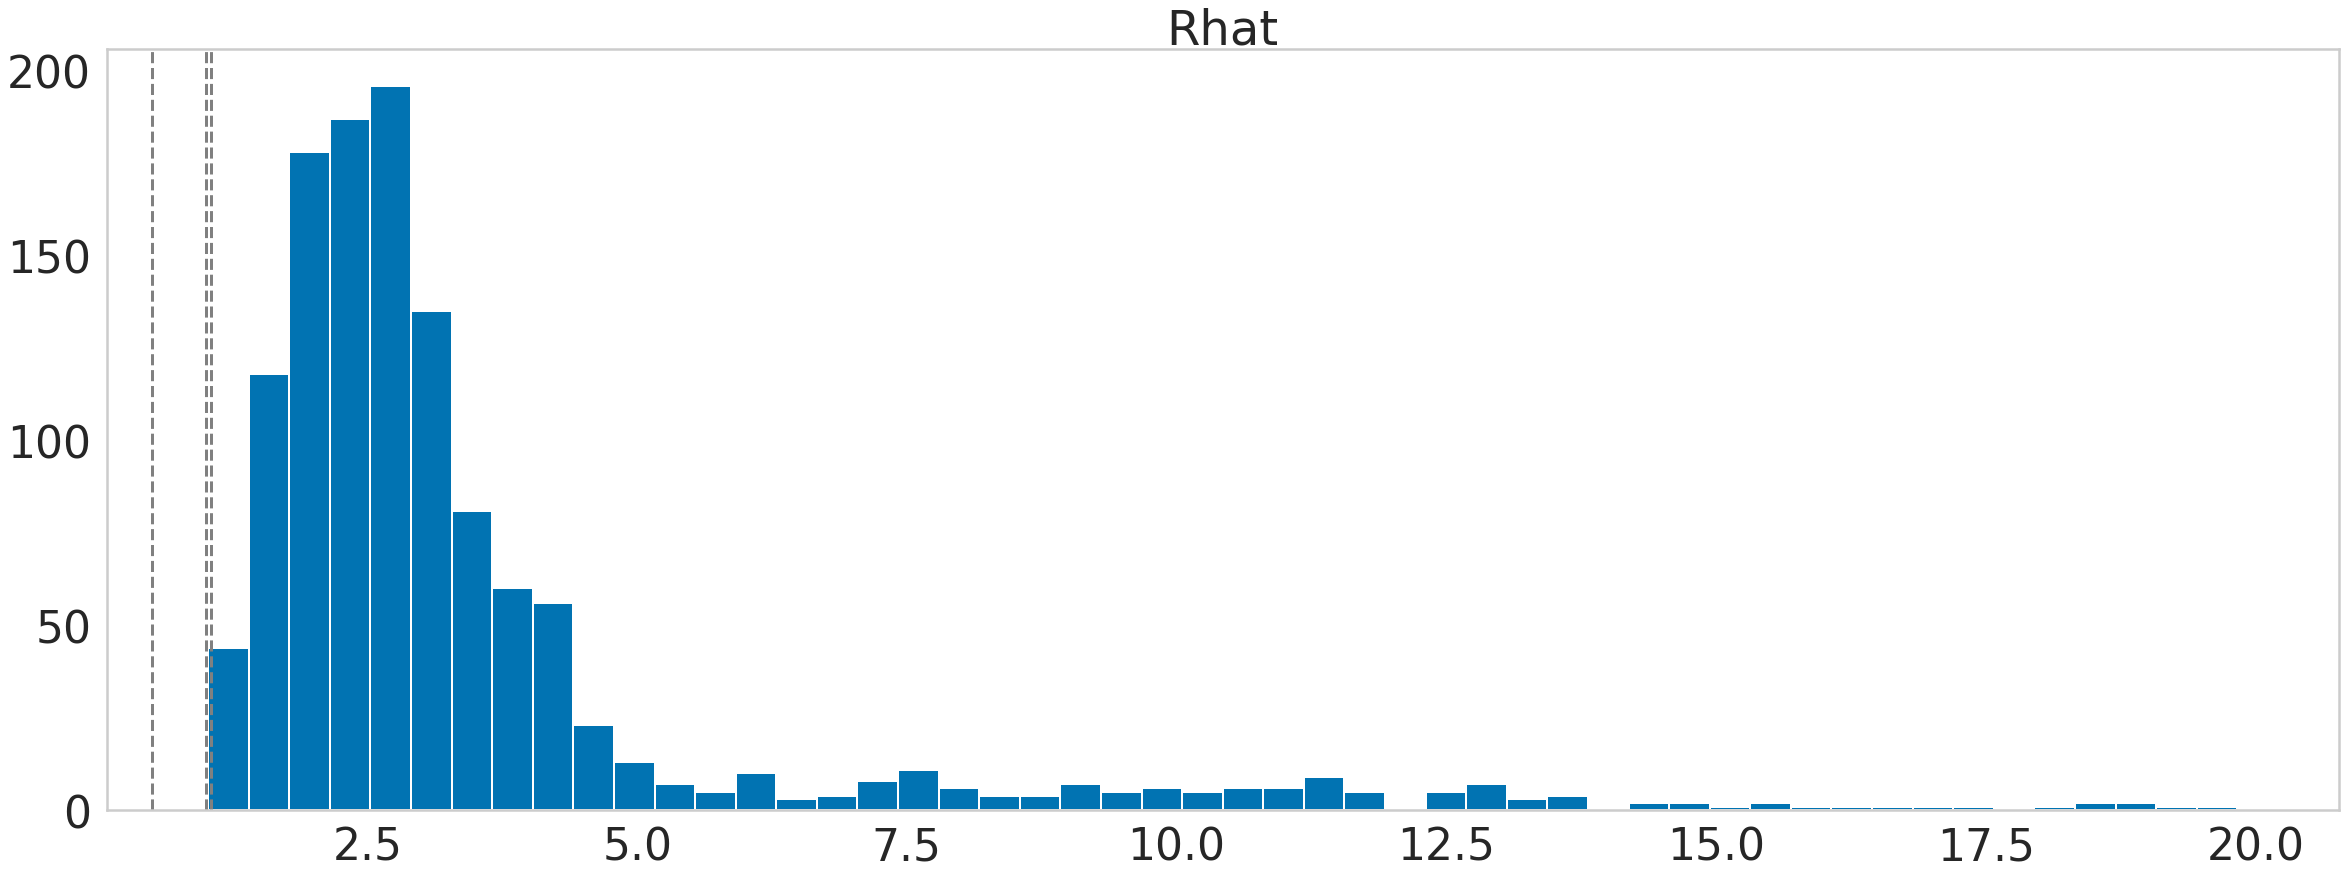

In [66]:

plt.figure()
plt.title('Rhat')
plt.hist(rhat_ls_norm_init.values(),bins = 50)
plt.axvline(1.05,color="gray",linestyle="--",label=0.1)
plt.axvline(0.5,color="gray",linestyle="--",label=0.1)
plt.axvline(1,color="gray",linestyle="--",label=0.1)
plt.grid()



Rhat here is not as big as without initilization

## sorting

In [67]:
sim = fitted_init.sim
n_chains = sim['chains']
ns_save = sim['n_save']
ns_warmup2 = sim['warmup2']
ns_kept = [s - w for s, w in zip(sim['n_save'], sim['warmup2'])]

n_samples = int(min(ns_kept))

In [68]:
extract = ["F","G"]
results = fitted_init.extract(pars=extract, permuted=False, inc_warmup=True)

In [69]:
analysis.merge_chains(results, n=n_samples)  # extract last n draws from each chain

slicy = slice(-n_chains, None)

results_norm_init_sorted,indices = analysis.sort_by_Z_contribution(results, take=slicy, metric="cityblock")


Sorting sample sizes: (4, 3, 74) (4, 337, 3)


100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 200/200 [00:00<00:00, 2384.09it/s]

There are 1 possible orderings
Each ordering has appeared: [4]
Sorting starts...


In [70]:
indices

array([[0, 1, 2],
       [0, 1, 2],
       [0, 1, 2],
       [0, 1, 2],
       [0, 1, 2],
       [0, 1, 2],
       [0, 1, 2],
       [0, 1, 2],
       [0, 1, 2],
       [0, 1, 2],
       [0, 1, 2],
       [0, 1, 2],
       [0, 1, 2],
       [0, 1, 2],
       [0, 1, 2],
       [0, 1, 2],
       [0, 1, 2],
       [0, 1, 2],
       [0, 1, 2],
       [0, 1, 2],
       [0, 1, 2],
       [0, 1, 2],
       [0, 1, 2],
       [0, 1, 2],
       [0, 1, 2],
       [0, 1, 2],
       [0, 1, 2],
       [0, 1, 2],
       [0, 1, 2],
       [0, 1, 2],
       [0, 1, 2],
       [0, 1, 2],
       [0, 1, 2],
       [0, 1, 2],
       [0, 1, 2],
       [0, 1, 2],
       [0, 1, 2],
       [0, 1, 2],
       [0, 1, 2],
       [0, 1, 2],
       [0, 1, 2],
       [0, 1, 2],
       [0, 1, 2],
       [0, 1, 2],
       [0, 1, 2],
       [0, 1, 2],
       [0, 1, 2],
       [0, 1, 2],
       [0, 1, 2],
       [0, 1, 2],
       [0, 1, 2],
       [0, 1, 2],
       [0, 1, 2],
       [0, 1, 2],
       [0, 1, 2],
       [0,

In [71]:
F_norm_init_sorted= results_norm_init_sorted["F"].reshape(n_samples,n_chains,results_sorted["F"].shape[1],results_sorted["F"].shape[2])
F_norm_init_sorted.shape
G_norm_init_sorted = results_norm_init_sorted["G"].reshape(n_samples,n_chains,results_sorted["G"].shape[1],results_sorted["G"].shape[2])
G_norm_init_sorted.shape

(50, 4, 337, 3)

In [72]:


rhat_ls_norm_init_sorted = {}

for name in tqdm(pars):
    if name[0]=="F":
        idx1,idx2 = int(name.split(",")[0].split("[")[1]) - 1,int(name.split(",")[1].split("]")[0]) - 1
        rhat_ls_norm_init_sorted[name] = split_potential_scale_reduction_sorted(n_samples,n_chains,F_norm_init_sorted,idx1,idx2)
    if name[0]=="G":
        idx1,idx2 = int(name.split(",")[0].split("[")[1]) - 1,int(name.split(",")[1].split("]")[0]) - 1
        rhat_ls_norm_init_sorted[name] = split_potential_scale_reduction_sorted(n_samples,n_chains,G_norm_init_sorted,idx1,idx2)
rhat_ls_norm_init_sorted

100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1240/1240 [00:00<00:00, 2880.26it/s]


{'G[1,1]': 3.685883139747222,
 'G[2,1]': 2.117356346521819,
 'G[3,1]': 1.7263661412334663,
 'G[4,1]': 2.056399666155407,
 'G[5,1]': 2.774518173535485,
 'G[6,1]': 2.3599640708880996,
 'G[7,1]': 2.1007495476429536,
 'G[8,1]': 3.2840233611324945,
 'G[9,1]': 4.0817022536987,
 'G[10,1]': 7.3266374171167605,
 'G[11,1]': 18.99740747719093,
 'G[12,1]': 7.28481514717974,
 'G[13,1]': 2.0097547029932987,
 'G[14,1]': 3.5856432204774804,
 'G[15,1]': 3.8413804556446722,
 'G[16,1]': 8.515783827486514,
 'G[17,1]': 2.0586373023464195,
 'G[18,1]': 1.9846473499003523,
 'G[19,1]': 2.44971549835747,
 'G[20,1]': 1.6711775293893127,
 'G[21,1]': 1.8143778209223704,
 'G[22,1]': 1.189972587734096,
 'G[23,1]': 12.822135218088794,
 'G[24,1]': 3.2187784989271333,
 'G[25,1]': 4.937256903540739,
 'G[26,1]': 6.263990440448964,
 'G[27,1]': 1.2615140618864331,
 'G[28,1]': 4.250723109453214,
 'G[29,1]': 2.2511461534651276,
 'G[30,1]': 1.9536155130052562,
 'G[31,1]': 3.495352439607751,
 'G[32,1]': 11.093119471731598,
 'G

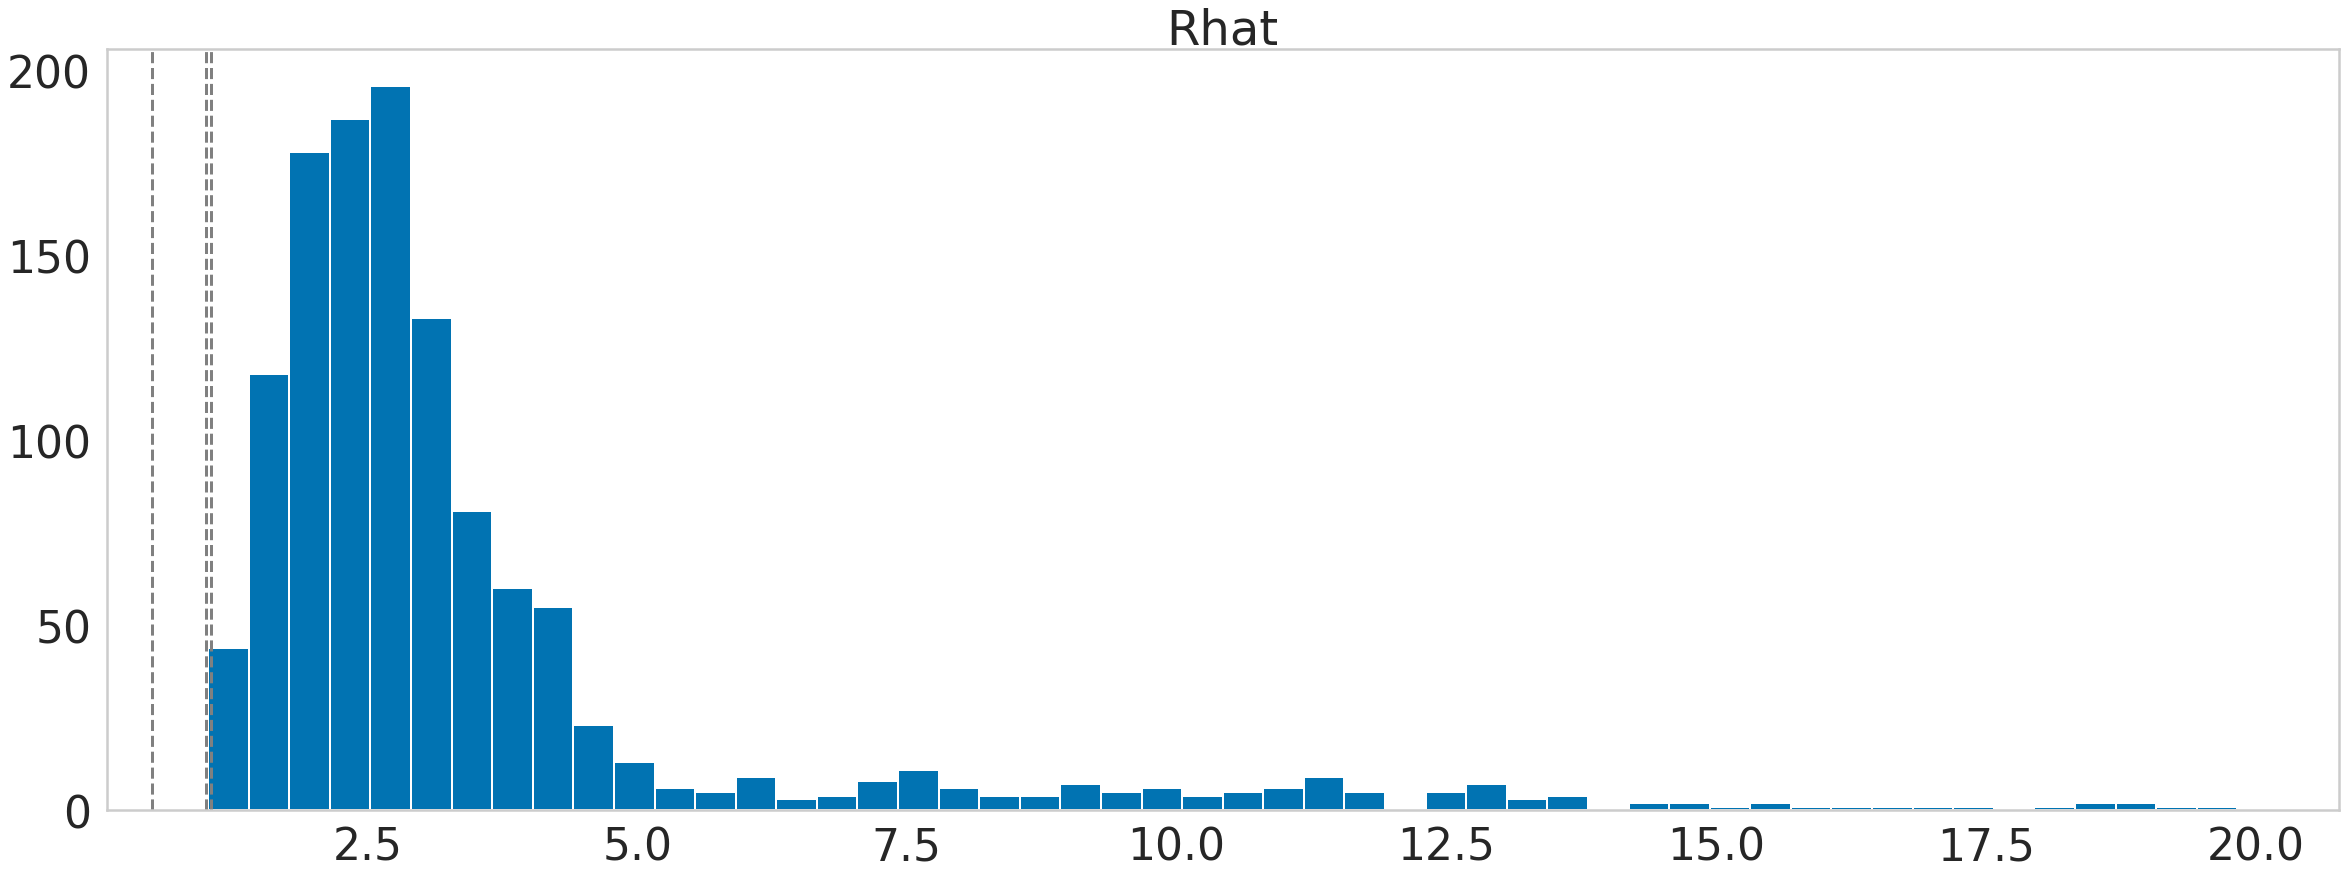

In [73]:
plt.figure()
plt.title('Rhat')
plt.hist(rhat_ls_norm_init_sorted.values(),bins = 50)
plt.axvline(1.05,color="gray",linestyle="--",label=0.1)
plt.axvline(0.5,color="gray",linestyle="--",label=0.1)
plt.axvline(1,color="gray",linestyle="--",label=0.1)
plt.grid()


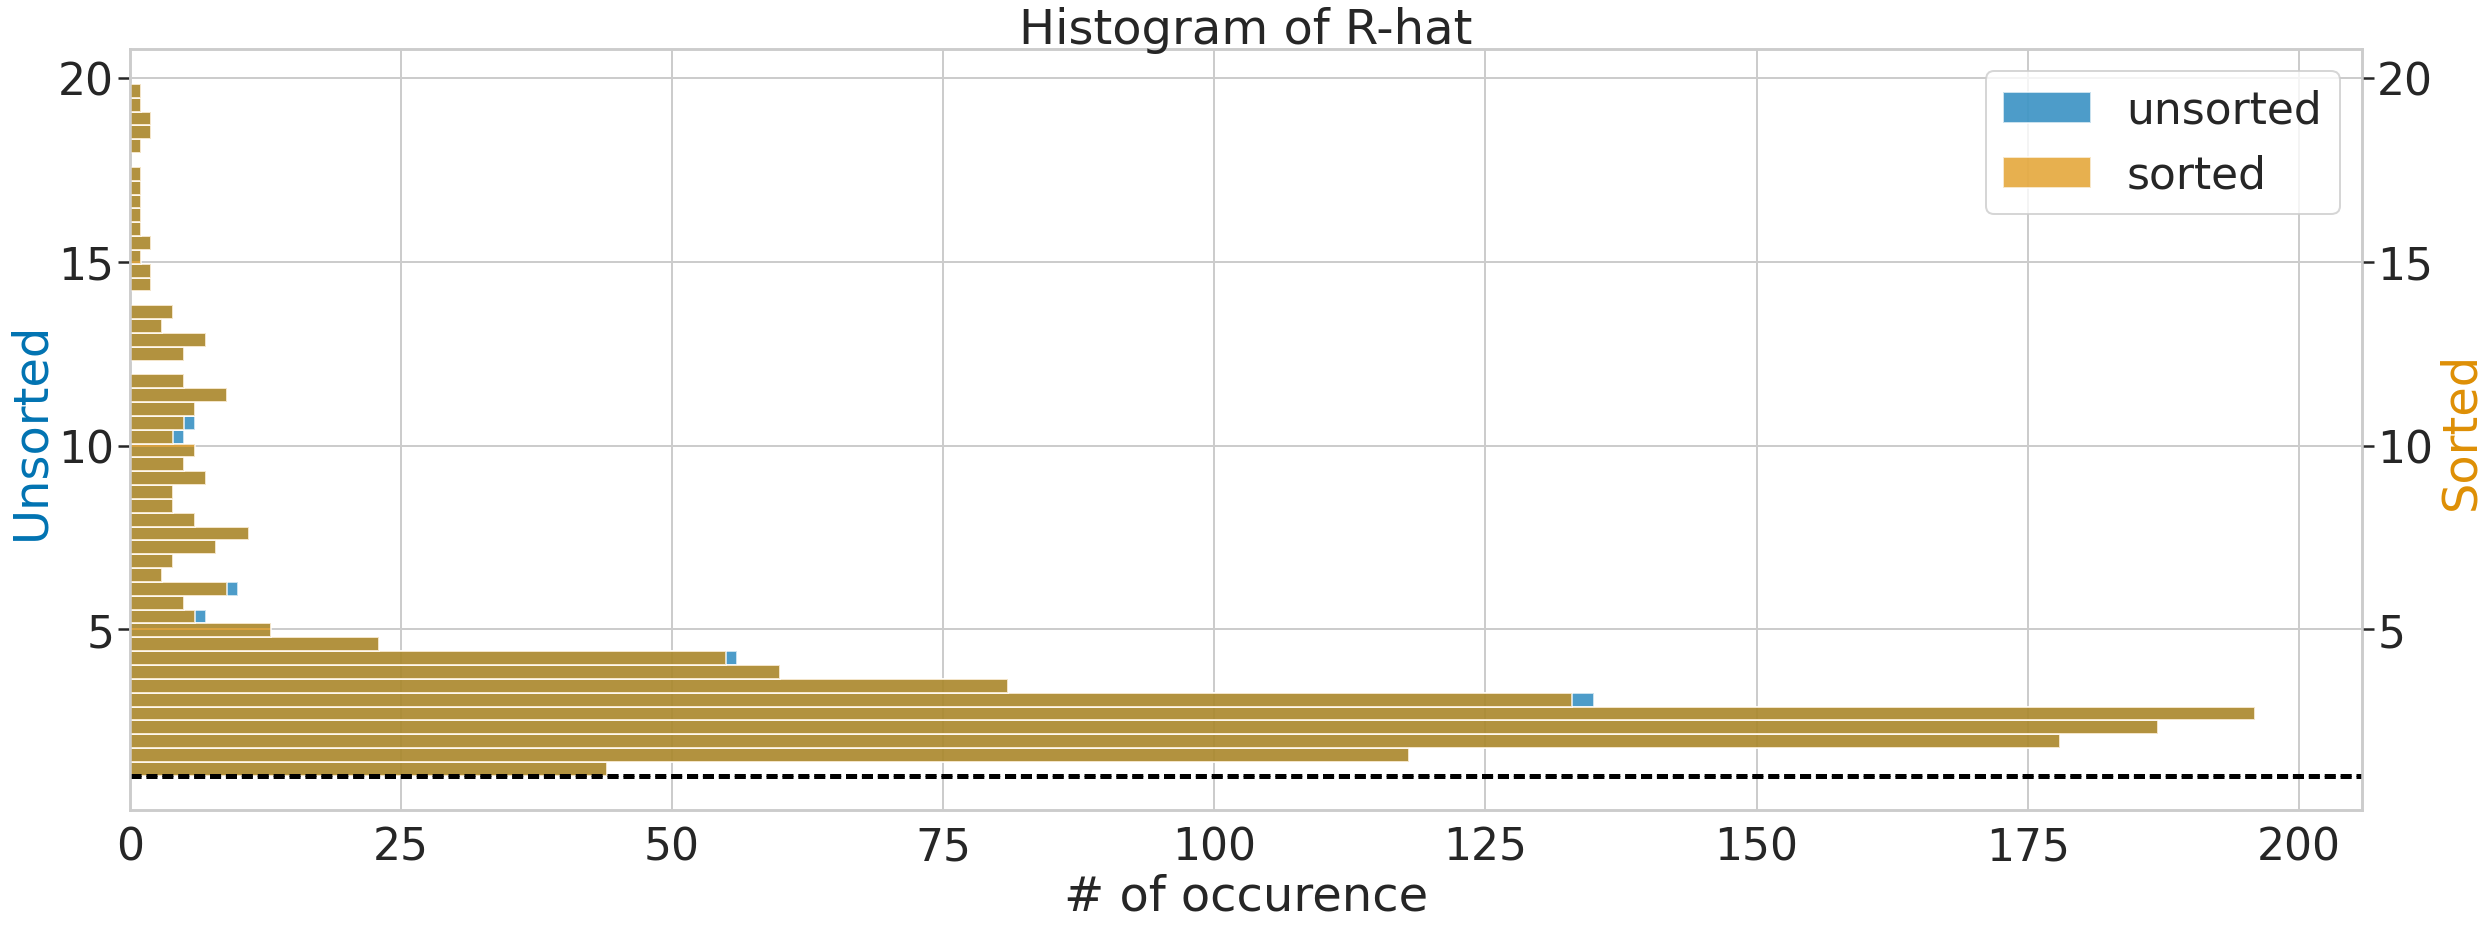

In [74]:
# create figure and axis objects with subplots()
fig,ax = plt.subplots()
# make a plot
ax.hist(rhat_ls_norm_init.values(),bins = 50,color=palette[0],alpha=0.7,label="unsorted",orientation='horizontal')
# set x-axis label
ax.set_xlabel("# of occurence")
# set y-axis label
ax.set_ylabel("Unsorted",color=palette[0])
# twin object for two different y-axis on the sample plot
ax2=ax.twinx()
# make a plot with different y-axis using second axis object
ax2.hist(rhat_ls_norm_init_sorted.values(),bins = 50,color=palette[1],alpha=0.7,label="sorted",orientation='horizontal')
ax2.set_ylabel("Sorted",color=palette[1])


lines, labels = ax.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax2.legend(lines + lines2, labels + labels2, loc=0)

plt.axhline(1.05,color="black",linestyle="--")
plt.axhline(1,color="black",linestyle="--")
# plt.legend()
plt.title("Histogram of R-hat")
plt.show()


In [75]:
#TODO traceplot

# Manually parallel results

In [76]:
def model_init():
    print("seed:",seed)
    preoptions = {}

    if "premodel_options" in initoptions:
        preoptions.update(initoptions["premodel_options"])

    inits = premodel.optimizing(data, **preoptions, as_vector=True,seed=seed)

    return inits

In [77]:

fitted_ls = []
seed_ls = [16,18,17,19]
for i in seed_ls:
    fitted = loaded_model.sampling(data=data, iter=iterations, init=init_function, chains=1, 
                                   n_jobs=1, seed=i,control={"adapt_delta":delta, 
                                                                "max_treedepth":treedepth})
    fitted_ls.append(fitted)

Informational Message: The current Metropolis proposal is about to be rejected because of the following issue:
Exception: cauchy_lpdf: Location parameter[43] is inf, but must be finite!  (in 'unknown file name' at line 40)

If this warning occurs sporadically, such as for highly constrained variable types like covariance matrices, then the sampler is fine,
but if this warning occurs often then your model may be either severely ill-conditioned or misspecified.

To run all diagnostics call pystan.check_hmc_diagnostics(fit)
Informational Message: The current Metropolis proposal is about to be rejected because of the following issue:
Exception: cauchy_lpdf: Location parameter[43] is inf, but must be finite!  (in 'unknown file name' at line 40)

If this warning occurs sporadically, such as for highly constrained variable types like covariance matrices, then the sampler is fine,
but if this warning occurs often then your model may be either severely ill-conditioned or misspecified.

Informat

Initial log joint probability = -3.74663e+08
    Iter      log prob        ||dx||      ||grad||       alpha      alpha0  # evals  Notes 
      19  -1.73673e+08       2.27871   8.53885e+06           1           1       31   
    Iter      log prob        ||dx||      ||grad||       alpha      alpha0  # evals  Notes 
      39  -9.25067e+07       2.15394   1.06329e+07           1           1       52   
    Iter      log prob        ||dx||      ||grad||       alpha      alpha0  # evals  Notes 
      59  -5.57046e+07       1.37327   3.86125e+06           1           1       74   
    Iter      log prob        ||dx||      ||grad||       alpha      alpha0  # evals  Notes 
      79   -4.1162e+07      0.393961   1.82943e+06      0.3372      0.9944       97   
    Iter      log prob        ||dx||      ||grad||       alpha      alpha0  # evals  Notes 
      99  -3.02508e+07      0.231346   1.35724e+06      0.9296      0.9296      119   
    Iter      log prob        ||dx||      ||grad||       alp

To run all diagnostics call pystan.check_hmc_diagnostics(fit)
Informational Message: The current Metropolis proposal is about to be rejected because of the following issue:
Exception: cauchy_lpdf: Location parameter[43] is inf, but must be finite!  (in 'unknown file name' at line 40)

If this warning occurs sporadically, such as for highly constrained variable types like covariance matrices, then the sampler is fine,
but if this warning occurs often then your model may be either severely ill-conditioned or misspecified.

Informational Message: The current Metropolis proposal is about to be rejected because of the following issue:
Exception: cauchy_lpdf: Location parameter[43] is inf, but must be finite!  (in 'unknown file name' at line 40)

If this warning occurs sporadically, such as for highly constrained variable types like covariance matrices, then the sampler is fine,
but if this warning occurs often then your model may be either severely ill-conditioned or misspecified.

Informat

      alpha0  # evals  Notes 
     459  -8.89722e+06      0.149054        469073      0.5028      0.5028      507   
    Iter      log prob        ||dx||      ||grad||       alpha      alpha0  # evals  Notes 
     479  -8.56557e+06       0.16395        492414      0.4338      0.4338      529   
    Iter      log prob        ||dx||      ||grad||       alpha      alpha0  # evals  Notes 
     499  -7.82035e+06      0.325872        418452           1           1      550   
    Iter      log prob        ||dx||      ||grad||       alpha      alpha0  # evals  Notes 
     519  -7.07785e+06      0.148681        484385           1           1      571   
    Iter      log prob        ||dx||      ||grad||       alpha      alpha0  # evals  Notes 
     539   -6.7513e+06      0.400841        525775           1           1      593   
    Iter      log prob        ||dx||      ||grad||       alpha      alpha0  # evals  Notes 
     559  -6.31249e+06      0.314227   1.32177e+06      0.9661      0.9661 

Informational Message: The current Metropolis proposal is about to be rejected because of the following issue:
Exception: cauchy_lpdf: Location parameter[43] is inf, but must be finite!  (in 'unknown file name' at line 40)

If this warning occurs sporadically, such as for highly constrained variable types like covariance matrices, then the sampler is fine,
but if this warning occurs often then your model may be either severely ill-conditioned or misspecified.

Informational Message: The current Metropolis proposal is about to be rejected because of the following issue:
Exception: cauchy_lpdf: Location parameter[43] is inf, but must be finite!  (in 'unknown file name' at line 40)

If this warning occurs sporadically, such as for highly constrained variable types like covariance matrices, then the sampler is fine,
but if this warning occurs often then your model may be either severely ill-conditioned or misspecified.

Informational Message: The current Metropolis proposal is about to be 

          1     1209   
    Iter      log prob        ||dx||      ||grad||       alpha      alpha0  # evals  Notes 
    1139  -2.63384e+06      0.269746        344503      0.4833           1     1231   
    Iter      log prob        ||dx||      ||grad||       alpha      alpha0  # evals  Notes 
    1159  -2.56923e+06       0.10366        140735           1           1     1252   
    Iter      log prob        ||dx||      ||grad||       alpha      alpha0  # evals  Notes 
    1179  -2.52094e+06     0.0242895        115235           1           1     1274   
    Iter      log prob        ||dx||      ||grad||       alpha      alpha0  # evals  Notes 
    1199  -2.49511e+06      0.252764        206049           1           1     1296   
    Iter      log prob        ||dx||      ||grad||       alpha      alpha0  # evals  Notes 
    1219  -2.46686e+06     0.0339802        112810           1           1     1317   
    Iter      log prob        ||dx||      ||grad||       alpha      alpha0  # eva

To run all diagnostics call pystan.check_hmc_diagnostics(fit)
Informational Message: The current Metropolis proposal is about to be rejected because of the following issue:
Exception: cauchy_lpdf: Location parameter[43] is inf, but must be finite!  (in 'unknown file name' at line 40)

If this warning occurs sporadically, such as for highly constrained variable types like covariance matrices, then the sampler is fine,
but if this warning occurs often then your model may be either severely ill-conditioned or misspecified.

Informational Message: The current Metropolis proposal is about to be rejected because of the following issue:
Exception: cauchy_lpdf: Location parameter[43] is inf, but must be finite!  (in 'unknown file name' at line 40)

If this warning occurs sporadically, such as for highly constrained variable types like covariance matrices, then the sampler is fine,
but if this warning occurs often then your model may be either severely ill-conditioned or misspecified.

Informat

  -1.34826e+06    0.00611267        227883      0.5381      0.5381     2139   
Optimization terminated normally: 
  Maximum number of iterations hit, may not be at an optima

Gradient evaluation took 0 seconds
1000 transitions using 10 leapfrog steps per transition would take 0 seconds.
Adjust your expectations accordingly!


         three stages of adaptation as currently configured.
         Reducing each adaptation stage to 15%/75%/10% of
         the given number of warmup iterations:
           init_buffer = 7
           adapt_window = 38
           term_buffer = 5

Iteration:  1 / 100 [  1%]  (Warmup)
Iteration: 10 / 100 [ 10%]  (Warmup)
Iteration: 20 / 100 [ 20%]  (Warmup)
Iteration: 30 / 100 [ 30%]  (Warmup)
Iteration: 40 / 100 [ 40%]  (Warmup)
Iteration: 50 / 100 [ 50%]  (Warmup)
Iteration: 51 / 100 [ 51%]  (Sampling)
Iteration: 60 / 100 [ 60%]  (Sampling)
Iteration: 70 / 100 [ 70%]  (Sampling)
Iteration: 80 / 100 [ 80%]  (Sampling)
Iteration: 90 / 100 [ 90%]  (Sampling)
Iter

In [78]:
# merge multiple chains
shape_F = fitted.extract(pars=extract, permuted=False, inc_warmup=True)["F"].shape
shape_G = fitted.extract(pars=extract, permuted=False, inc_warmup=True)["G"].shape
F = np.empty(shape=shape_F)
G = np.empty(shape=shape_G)
F[:] = np.nan
G[:] = np.nan
for fitted in fitted_ls:
    extract = ["F","G"]
    results = fitted.extract(pars=extract, permuted=False, inc_warmup=True)
    F = np.concatenate([F,results["F"][()]],axis=1)
    G = np.concatenate([G,results["G"][()]],axis=1)
F = np.delete(F, [0], axis=1)
G = np.delete(G, [0], axis=1)

    399  -9.64417e+06     0.0352372        685158       0.533       0.533      444   
    Iter      log prob        ||dx||      ||grad||       alpha      alpha0  # evals  Notes 
     419  -9.39604e+06     0.0448127        451816      0.6105      0.6105      464   
    Iter      log prob        ||dx||      ||grad||       alpha      alpha0  # evals  Notes 
     439  -9.12608e+06      0.337237        874527           1           1      486   
    Iter      log prob        ||dx||      ||grad||       alpha      alpha0  # evals  Notes 
     459  -8.89722e+06      0.149054        469073      0.5028      0.5028      507   
    Iter      log prob        ||dx||      ||grad||       alpha      alpha0  # evals  Notes 
     479  -8.56557e+06       0.16395        492414      0.4338      0.4338      529   
    Iter      log prob        ||dx||      ||grad||       alpha      alpha0  # evals  Notes 
     499  -7.82035e+06      0.325872        418452           1           1      550   
    Iter      log p

In [79]:
n_chains = F.shape[1]
n_samples = int(F.shape[0]/2)
rhat_ls_norm_init_manual = {}

for i in tqdm(range(F.shape[2])):
    for j in range(F.shape[3]):
        name="F["+str(i+1) + ","+str(j+1) +"]"
        rhat_ls_norm_init_manual[name] = split_potential_scale_reduction_sorted(n_samples,n_chains,F[n_samples:],i,j)
    
for i in tqdm(range(G.shape[2])):
    for j in range(G.shape[3]):
        name="G["+str(i+1) + ","+str(j+1) +"]"
        rhat_ls_norm_init_manual[name] = split_potential_scale_reduction_sorted(n_samples,n_chains,G[n_samples:],i,j)

100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 337/337 [00:00<00:00, 1080.30it/s]


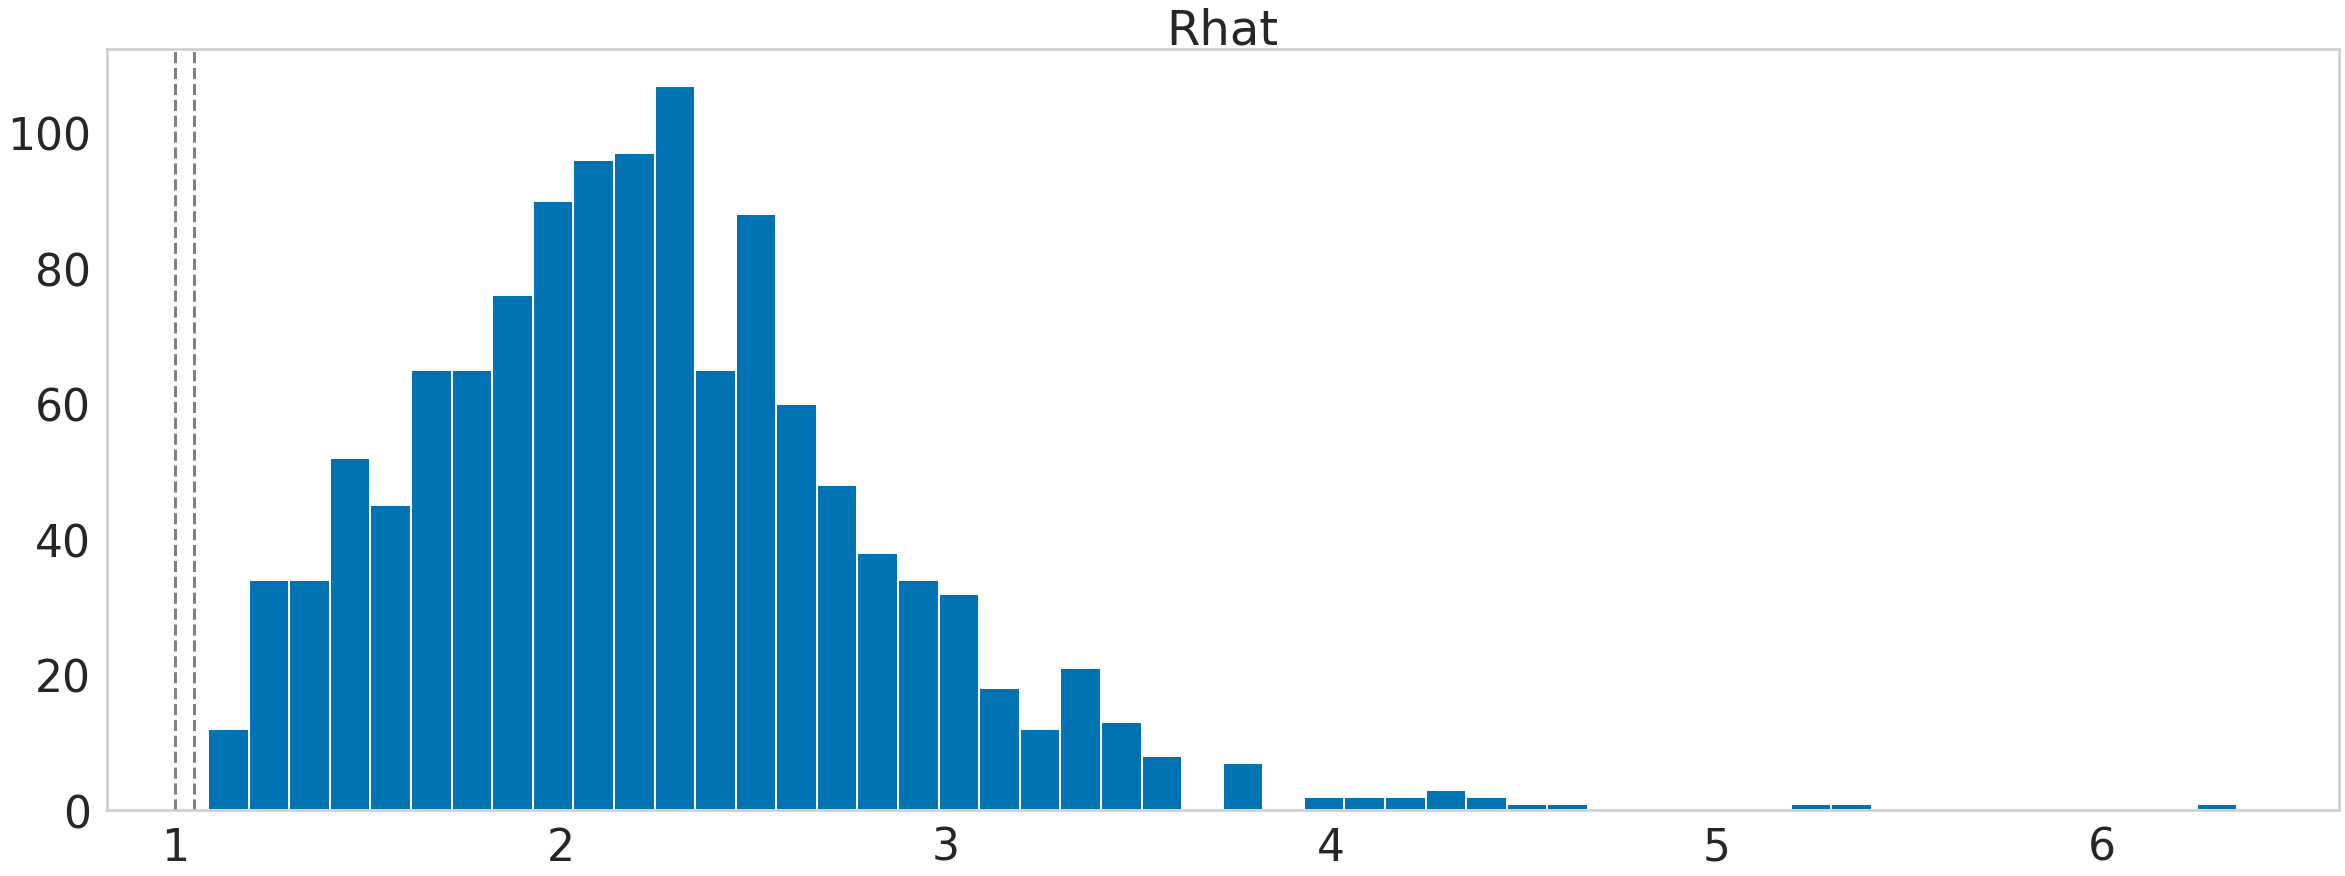

In [80]:
plt.figure()
plt.title('Rhat')
plt.hist(rhat_ls_norm_init_manual.values(),bins = 50)
plt.axvline(1.05,color="gray",linestyle="--",label=0.1)
# plt.axvline(0.5,color="gray",linestyle="--",label=0.1)
plt.axvline(1,color="gray",linestyle="--",label=0.1)
plt.grid()

## Sorting

In [81]:
from collections import OrderedDict
results_merged = {}
results_merged["F"] = F
results_merged["G"] = G

analysis.merge_chains(results_merged, n=n_samples)  # extract last n draws from each chain

slicy = slice(-n_chains, None)

# results_sorted = analysis.sort_by_Z_contribution(results_merged, take=slicy, metric="cityblock")
results_sorted,indices = analysis.sort_by_Z_contribution(results_merged, take=slicy, metric="cityblock")


Sorting sample sizes: (4, 3, 74) (4, 337, 3)


100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 200/200 [00:00<00:00, 2646.58it/s]

There are 1 possible orderings
Each ordering has appeared: [4]
Sorting starts...


In [82]:
# indices

In [83]:
F= results_sorted["F"].reshape(n_samples,n_chains,results_sorted["F"].shape[1],results_sorted["F"].shape[2])
F.shape
G = results_sorted["G"].reshape(n_samples,n_chains,results_sorted["G"].shape[1],results_sorted["G"].shape[2])
G.shape

(50, 4, 337, 3)

In [84]:
rhat_ls_norm_init_manual_sorted = {}

for name in tqdm(pars):
    if name[0]=="F":

        idx1,idx2 = int(name.split(",")[0].split("[")[1]) - 1,int(name.split(",")[1].split("]")[0]) - 1
        rhat_ls_norm_init_manual_sorted[name] = split_potential_scale_reduction_sorted(n_samples,n_chains,F,idx1,idx2)
    if name[0]=="G":

        idx1,idx2 = int(name.split(",")[0].split("[")[1]) - 1,int(name.split(",")[1].split("]")[0]) - 1
        rhat_ls_norm_init_manual_sorted[name] = split_potential_scale_reduction_sorted(n_samples,n_chains,G,idx1,idx2)
# rhat_ls_norm_init_manual_sorted

100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1240/1240 [00:00<00:00, 3170.68it/s]


{'G[1,1]': 2.0969966677437,
 'G[2,1]': 1.4384486665329825,
 'G[3,1]': 2.2562808304953372,
 'G[4,1]': 2.674869061956191,
 'G[5,1]': 3.5015814605368862,
 'G[6,1]': 1.5234126614981485,
 'G[7,1]': 2.2182767910189547,
 'G[8,1]': 2.1129638422147137,
 'G[9,1]': 2.6402611204421027,
 'G[10,1]': 2.432090977933104,
 'G[11,1]': 3.1629407377444934,
 'G[12,1]': 2.5488318478776204,
 'G[13,1]': 1.4692878217198706,
 'G[14,1]': 1.7524011985537675,
 'G[15,1]': 1.9536216975946792,
 'G[16,1]': 1.899278593159591,
 'G[17,1]': 2.3866321951528326,
 'G[18,1]': 1.30581530081991,
 'G[19,1]': 2.30223711212088,
 'G[20,1]': 2.7185183796678034,
 'G[21,1]': 2.538327195342527,
 'G[22,1]': 1.5655706655410089,
 'G[23,1]': 2.167861021518649,
 'G[24,1]': 2.033835233330815,
 'G[25,1]': 3.060180231099706,
 'G[26,1]': 2.1456279578852144,
 'G[27,1]': 1.5767949042290428,
 'G[28,1]': 1.8825336791550085,
 'G[29,1]': 1.8747937141268871,
 'G[30,1]': 2.1402281701729926,
 'G[31,1]': 1.6045019466490424,
 'G[32,1]': 2.960223151363905,


In [85]:
for i in rhat_ls_norm_init_manual_sorted.keys():
    if rhat_ls_norm_init_manual[i] != rhat_ls_norm_init_manual_sorted[i]:
        print(i)

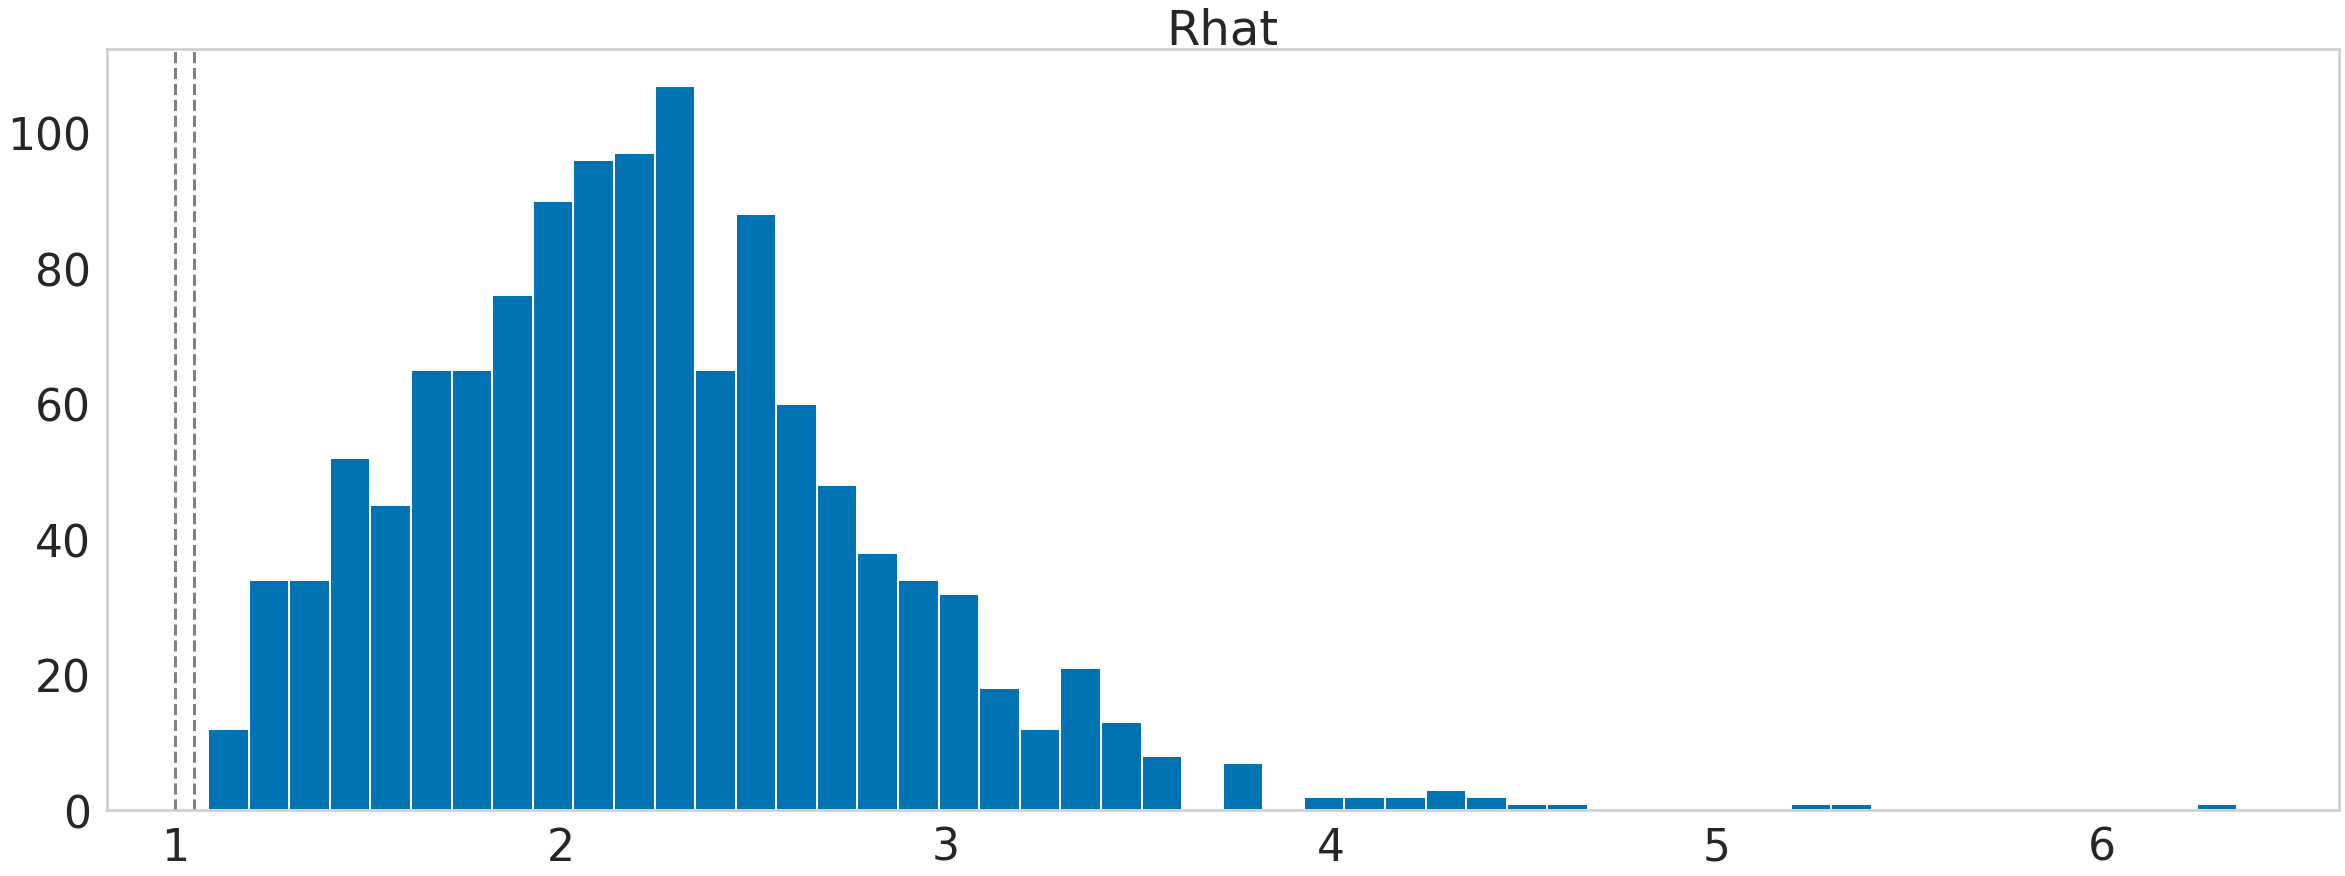

In [86]:
plt.figure()
plt.title('Rhat')
plt.hist(rhat_ls_norm_init_manual_sorted.values(),bins = 50)
plt.axvline(1.05,color="gray",linestyle="--",label=0.1)
# plt.axvline(0.5,color="gray",linestyle="--",label=0.1)
plt.axvline(1,color="gray",linestyle="--",label=0.1)
plt.grid()

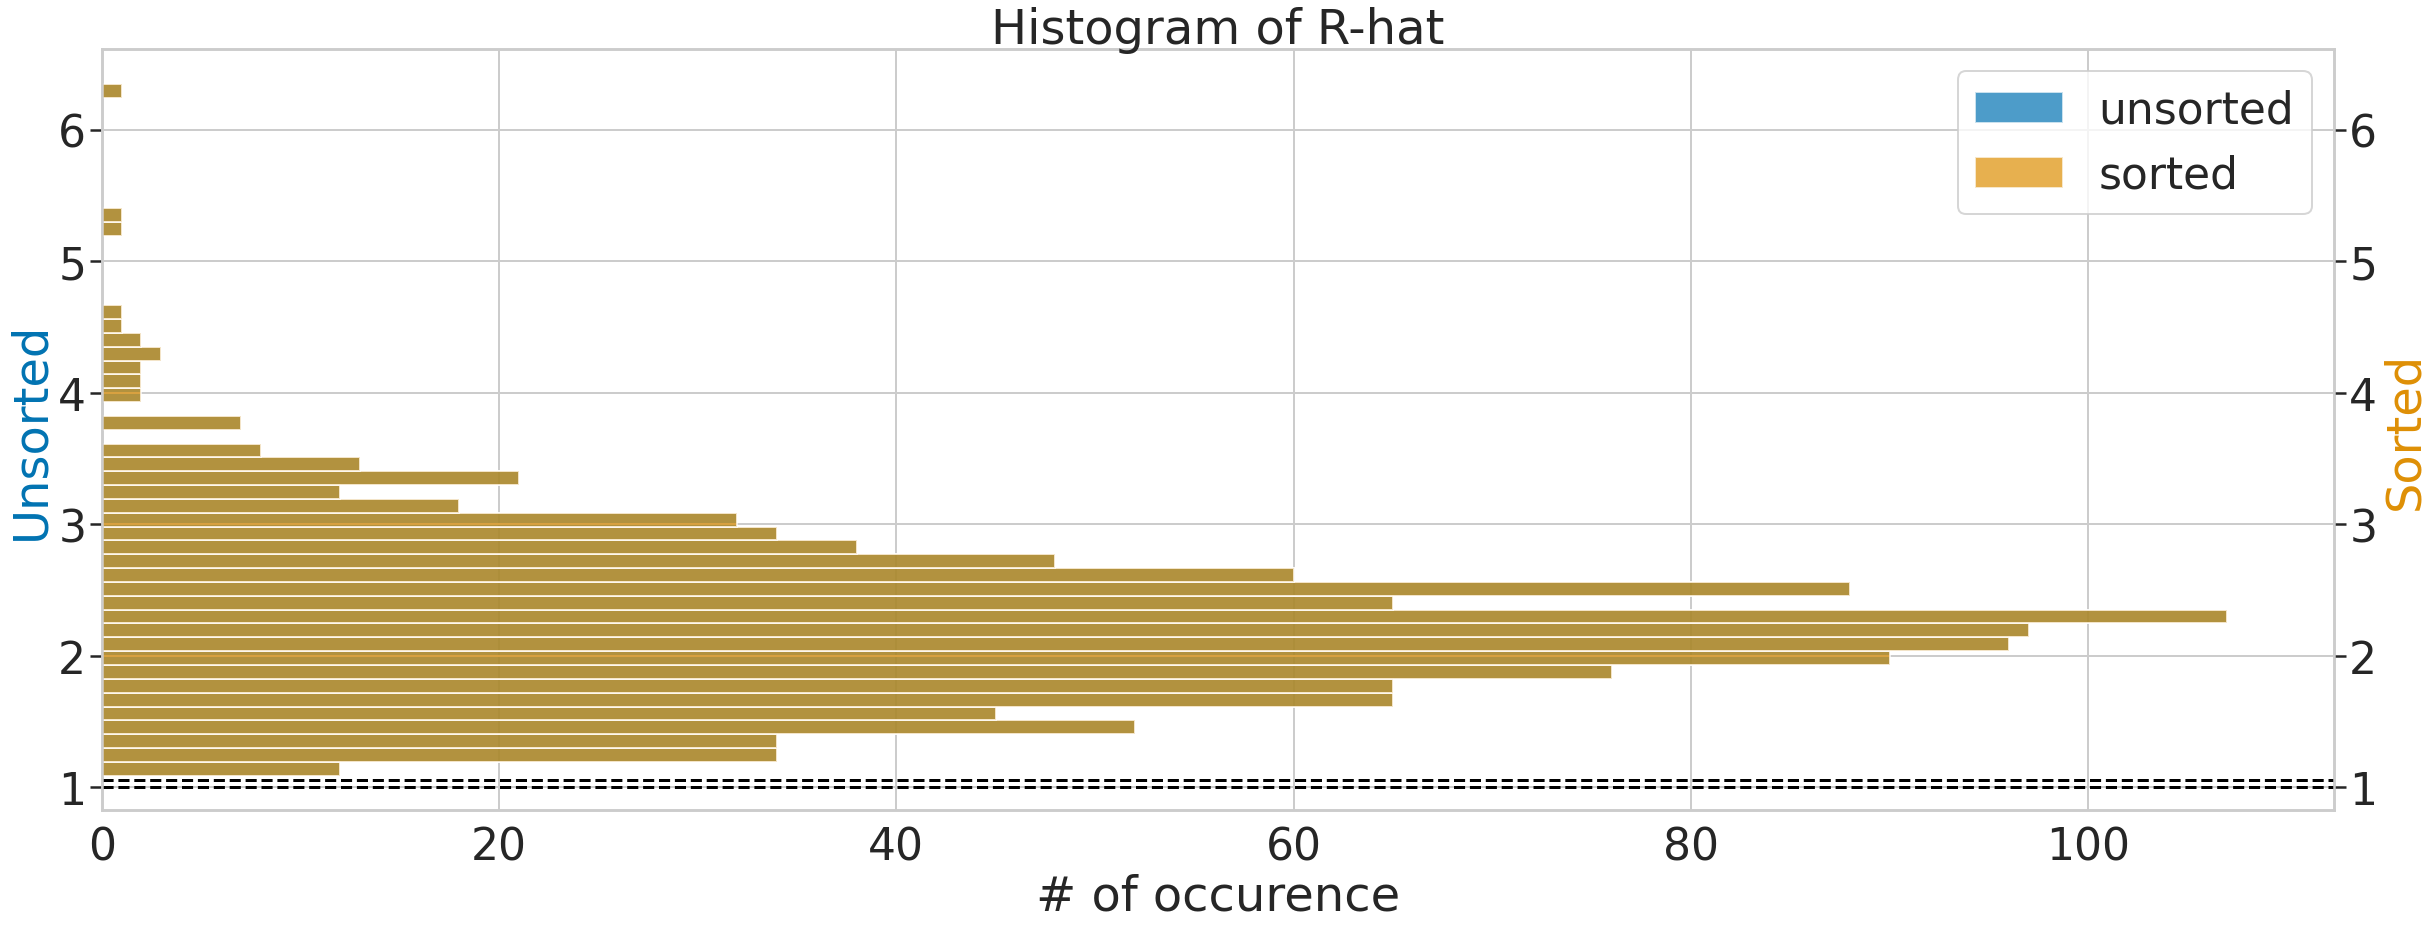

In [87]:
# create figure and axis objects with subplots()
fig,ax = plt.subplots()
# make a plot
ax.hist(rhat_ls_norm_init_manual.values(),bins = 50,color=palette[0],alpha=0.7,label="unsorted",orientation='horizontal')
# set x-axis label
ax.set_xlabel("# of occurence")
# set y-axis label
ax.set_ylabel("Unsorted",color=palette[0])
# twin object for two different y-axis on the sample plot
ax2=ax.twinx()
# make a plot with different y-axis using second axis object
ax2.hist(rhat_ls_norm_init_manual_sorted.values(),bins = 50,color=palette[1],alpha=0.7,label="sorted",orientation='horizontal')
ax2.set_ylabel("Sorted",color=palette[1])


lines, labels = ax.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax2.legend(lines + lines2, labels + labels2, loc=0)

plt.axhline(1.05,color="black",linestyle="--")
plt.axhline(1,color="black",linestyle="--")
# plt.legend()
plt.title("Histogram of R-hat")
plt.show()


# Manually parallel results & Unormalized

In [88]:
def model_init():
    print("seed:",seed)
    preoptions = {}

    if "premodel_options" in initoptions:
        preoptions.update(initoptions["premodel_options"])

    inits = premodel.optimizing(data, **preoptions, as_vector=True,seed=seed)

    return inits

In [89]:
init_function
fitted_ls = []
seed_ls = [16,18,17,19]
preprocessing = "nothing"
data, meta, extra = loaders[loader](Path(datafile))
data["p"] = n_factor
data, meta, extra = preprocessing_functions[preprocessing](data, meta, extra)

for i in seed_ls:
    fitted = loaded_model.sampling(data=data, iter=iterations, init=init_function, chains=1, 
                                   n_jobs=1, seed=i,control={"adapt_delta":delta, 
                                                                "max_treedepth":treedepth})
    fitted_ls.append(fitted)

Informational Message: The current Metropolis proposal is about to be rejected because of the following issue:
Exception: cauchy_lpdf: Location parameter[3] is inf, but must be finite!  (in 'unknown file name' at line 40)

If this warning occurs sporadically, such as for highly constrained variable types like covariance matrices, then the sampler is fine,
but if this warning occurs often then your model may be either severely ill-conditioned or misspecified.

To run all diagnostics call pystan.check_hmc_diagnostics(fit)


Initial log joint probability = -3.76531e+08
    Iter      log prob        ||dx||      ||grad||       alpha      alpha0  # evals  Notes 
      19  -9.84764e+07       3.48842   9.80355e+06           1           1       35   
    Iter      log prob        ||dx||      ||grad||       alpha      alpha0  # evals  Notes 
      39  -3.76582e+07      0.737889   6.10567e+06       0.415       0.415       62   
    Iter      log prob        ||dx||      ||grad||       alpha      alpha0  # evals  Notes 
      59  -2.12021e+07        1.4147   3.40054e+06           1           1       85   
    Iter      log prob        ||dx||      ||grad||       alpha      alpha0  # evals  Notes 
      79  -1.46253e+07         0.271   1.73561e+06       0.411       0.411      109   
    Iter      log prob        ||dx||      ||grad||       alpha      alpha0  # evals  Notes 
      99  -9.93119e+06      0.551092   1.18278e+06      0.3316           1      131   
    Iter      log prob        ||dx||      ||grad||       alp

Informational Message: The current Metropolis proposal is about to be rejected because of the following issue:
Exception: cauchy_lpdf: Location parameter[3] is inf, but must be finite!  (in 'unknown file name' at line 40)

If this warning occurs sporadically, such as for highly constrained variable types like covariance matrices, then the sampler is fine,
but if this warning occurs often then your model may be either severely ill-conditioned or misspecified.

Informational Message: The current Metropolis proposal is about to be rejected because of the following issue:
Exception: cauchy_lpdf: Location parameter[70] is inf, but must be finite!  (in 'unknown file name' at line 40)

If this warning occurs sporadically, such as for highly constrained variable types like covariance matrices, then the sampler is fine,
but if this warning occurs often then your model may be either severely ill-conditioned or misspecified.

Informational Message: The current Metropolis proposal is about to be r

41907e+06      0.289398        673409           1           1      154   
    Iter      log prob        ||dx||      ||grad||       alpha      alpha0  # evals  Notes 
     139  -6.78539e+06      0.183784        737376           1           1      174   
    Iter      log prob        ||dx||      ||grad||       alpha      alpha0  # evals  Notes 
     159  -6.17743e+06      0.164742        484385           1           1      195   
    Iter      log prob        ||dx||      ||grad||       alpha      alpha0  # evals  Notes 
     179  -5.57282e+06      0.810026        825474           1           1      215   
    Iter      log prob        ||dx||      ||grad||       alpha      alpha0  # evals  Notes 
     199  -4.81978e+06      0.881873   1.26852e+06           1           1      237   
    Iter      log prob        ||dx||      ||grad||       alpha      alpha0  # evals  Notes 
     219  -4.19488e+06      0.494152        553382           1           1      259   
    Iter      log prob        |

Informational Message: The current Metropolis proposal is about to be rejected because of the following issue:
Exception: cauchy_lpdf: Location parameter[3] is inf, but must be finite!  (in 'unknown file name' at line 40)

If this warning occurs sporadically, such as for highly constrained variable types like covariance matrices, then the sampler is fine,
but if this warning occurs often then your model may be either severely ill-conditioned or misspecified.

To run all diagnostics call pystan.check_hmc_diagnostics(fit)


...

Informational Message: The current Metropolis proposal is about to be rejected because of the following issue:
Exception: cauchy_lpdf: Location parameter[3] is inf, but must be finite!  (in 'unknown file name' at line 40)

If this warning occurs sporadically, such as for highly constrained variable types like covariance matrices, then the sampler is fine,
but if this warning occurs often then your model may be either severely ill-conditioned or misspecified.

To run all diagnostics call pystan.check_hmc_diagnostics(fit)
Informational Message: The current Metropolis proposal is about to be rejected because of the following issue:
Exception: cauchy_lpdf: Location parameter[3] is inf, but must be finite!  (in 'unknown file name' at line 40)

If this warning occurs sporadically, such as for highly constrained variable types like covariance matrices, then the sampler is fine,
but if this warning occurs often then your model may be either severely ill-conditioned or misspecified.

Informatio

Initial log joint probability = -3.76531e+08
    Iter      log prob        ||dx||      ||grad||       alpha      alpha0  # evals  Notes 
      19  -9.84764e+07       3.48842   9.80355e+06           1           1       35   
    Iter      log prob        ||dx||      ||grad||       alpha      alpha0  # evals  Notes 
      39  -3.76582e+07      0.737889   6.10567e+06       0.415       0.415       62   
    Iter      log prob        ||dx||      ||grad||       alpha      alpha0  # evals  Notes 
      59  -2.12021e+07        1.4147   3.40054e+06           1           1       85   
    Iter      log prob        ||dx||      ||grad||       alpha      alpha0  # evals  Notes 
      79  -1.46253e+07         0.271   1.73561e+06       0.411       0.411      109   
    Iter      log prob        ||dx||      ||grad||       alpha      alpha0  # evals  Notes 
      99  -9.93119e+06      0.551092   1.18278e+06      0.3316           1      131   
    Iter      log prob        ||dx||      ||grad||       alp

 this warning occurs often then your model may be either severely ill-conditioned or misspecified.

Informational Message: The current Metropolis proposal is about to be rejected because of the following issue:
Exception: cauchy_lpdf: Location parameter[125] is inf, but must be finite!  (in 'unknown file name' at line 40)

If this warning occurs sporadically, such as for highly constrained variable types like covariance matrices, then the sampler is fine,
but if this warning occurs often then your model may be either severely ill-conditioned or misspecified.



1.26852e+06           1           1      237   
    Iter      log prob        ||dx||      ||grad||       alpha      alpha0  # evals  Notes 
     219  -4.19488e+06      0.494152        553382           1           1      259   
    Iter      log prob        ||dx||      ||grad||       alpha      alpha0  # evals  Notes 
     239  -3.64088e+06      0.187911        632623      0.7187      0.7187      280   
    Iter      log prob        ||dx||      ||grad||       alpha      alpha0  # evals  Notes 
     259  -2.96811e+06      0.880231   1.58216e+06           1           1      301   
    Iter      log prob        ||dx||      ||grad||       alpha      alpha0  # evals  Notes 
     279  -2.57812e+06     0.0564091        317696           1           1      322   
    Iter      log prob        ||dx||      ||grad||       alpha      alpha0  # evals  Notes 
     299  -2.32278e+06      0.257839        295150           1           1      343   
    Iter      log prob        ||dx||      ||grad||       

  Iter      log prob        ||dx||      ||grad||       alpha      alpha0  # evals  Notes 
    1219       -354838      0.118431         79392           1           1     1333   
    Iter      log prob        ||dx||      ||grad||       alpha      alpha0  # evals  Notes 
    1239       -345008      0.114731       56270.2           1           1     1355   
    Iter      log prob        ||dx||      ||grad||       alpha      alpha0  # evals  Notes 
    1259       -337779     0.0153429       67436.1           1           1     1376   
    Iter      log prob        ||dx||      ||grad||       alpha      alpha0  # evals  Notes 
    1279       -332153     0.0166362       72499.8      0.2809      0.2809     1398   
    Iter      log prob        ||dx||      ||grad||       alpha      alpha0  # evals  Notes 
    1299       -327761     0.0160908       77756.6      0.8072      0.8072     1419   
    Iter      log prob        ||dx||      ||grad||       alpha      alpha0  # evals  Notes 
    1319       

In [90]:
# merge multiple chains
shape_F = fitted.extract(pars=extract, permuted=False, inc_warmup=True)["F"].shape
shape_G = fitted.extract(pars=extract, permuted=False, inc_warmup=True)["G"].shape
F = np.empty(shape=shape_F)
G = np.empty(shape=shape_G)
F[:] = np.nan
G[:] = np.nan
for fitted in fitted_ls:
    extract = ["F","G"]
    results = fitted.extract(pars=extract, permuted=False, inc_warmup=True)
    F = np.concatenate([F,results["F"][()]],axis=1)
    G = np.concatenate([G,results["G"][()]],axis=1)
F = np.delete(F, [0], axis=1)
G = np.delete(G, [0], axis=1)

In [91]:
n_chains = F.shape[1]
n_samples = int(F.shape[0]/2)
rhat_ls_norm_init_manual = {}

for i in tqdm(range(F.shape[2])):
    for j in range(F.shape[3]):
        name="F["+str(i+1) + ","+str(j+1) +"]"
        rhat_ls_norm_init_manual[name] = split_potential_scale_reduction_sorted(n_samples,n_chains,F[n_samples:],i,j)
    
for i in tqdm(range(G.shape[2])):
    for j in range(G.shape[3]):
        name="G["+str(i+1) + ","+str(j+1) +"]"
        rhat_ls_norm_init_manual[name] = split_potential_scale_reduction_sorted(n_samples,n_chains,G[n_samples:],i,j)

100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 337/337 [00:00<00:00, 1113.43it/s]


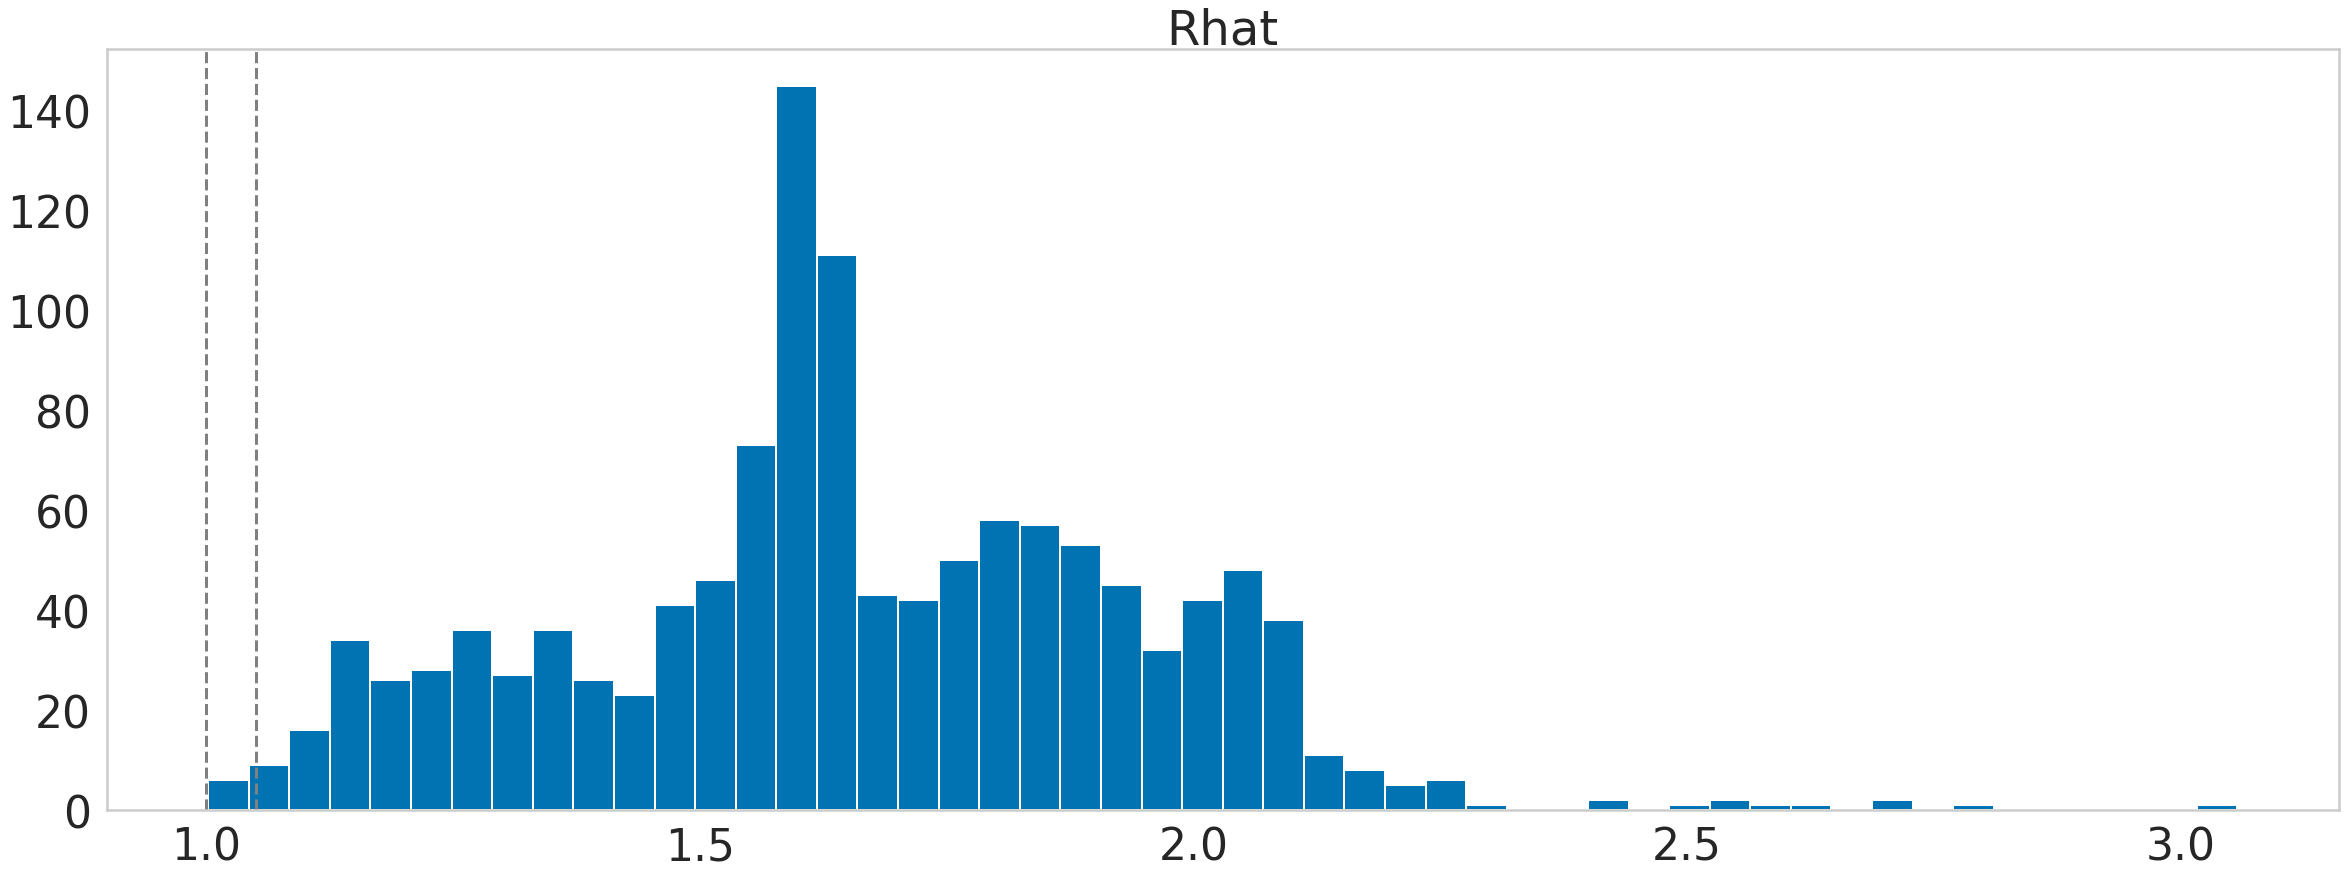

In [92]:
plt.figure()
plt.title('Rhat')
plt.hist(rhat_ls_norm_init_manual.values(),bins = 50)
plt.axvline(1.05,color="gray",linestyle="--",label=0.1)
# plt.axvline(0.5,color="gray",linestyle="--",label=0.1)
plt.axvline(1,color="gray",linestyle="--",label=0.1)
plt.grid()

## Sorting

In [93]:
from collections import OrderedDict
results_merged = {}
results_merged["F"] = F
results_merged["G"] = G

analysis.merge_chains(results_merged, n=n_samples)  # extract last n draws from each chain

slicy = slice(-n_chains, None)

# results_sorted = analysis.sort_by_Z_contribution(results_merged, take=slicy, metric="cityblock")
results_sorted,indices = analysis.sort_by_Z_contribution(results_merged, take=slicy, metric="cityblock")


Sorting sample sizes: (4, 3, 74) (4, 337, 3)


100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 200/200 [00:00<00:00, 2685.32it/s]

There are 1 possible orderings
Each ordering has appeared: [4]
Sorting starts...


In [94]:
# indices

In [95]:
F= results_sorted["F"].reshape(n_samples,n_chains,results_sorted["F"].shape[1],results_sorted["F"].shape[2])
F.shape
G = results_sorted["G"].reshape(n_samples,n_chains,results_sorted["G"].shape[1],results_sorted["G"].shape[2])
G.shape

(50, 4, 337, 3)

In [96]:
rhat_ls_norm_init_manual_sorted = {}

for name in tqdm(pars):
    if name[0]=="F":

        idx1,idx2 = int(name.split(",")[0].split("[")[1]) - 1,int(name.split(",")[1].split("]")[0]) - 1
        rhat_ls_norm_init_manual_sorted[name] = split_potential_scale_reduction_sorted(n_samples,n_chains,F,idx1,idx2)
    if name[0]=="G":

        idx1,idx2 = int(name.split(",")[0].split("[")[1]) - 1,int(name.split(",")[1].split("]")[0]) - 1
        rhat_ls_norm_init_manual_sorted[name] = split_potential_scale_reduction_sorted(n_samples,n_chains,G,idx1,idx2)
rhat_ls_norm_init_manual_sorted

100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1240/1240 [00:00<00:00, 3237.52it/s]


{'G[1,1]': 1.0102058356167323,
 'G[2,1]': 1.22969001262605,
 'G[3,1]': 1.548231744751283,
 'G[4,1]': 1.5902986765449312,
 'G[5,1]': 1.4772908630005186,
 'G[6,1]': 1.1351089269638137,
 'G[7,1]': 1.2932037650211885,
 'G[8,1]': 1.6839977724765594,
 'G[9,1]': 1.7843236228425865,
 'G[10,1]': 1.8430881543332875,
 'G[11,1]': 1.8951771355913323,
 'G[12,1]': 2.0756525350220905,
 'G[13,1]': 1.6594411461538083,
 'G[14,1]': 1.9258265441182716,
 'G[15,1]': 2.030748312513177,
 'G[16,1]': 1.788988473736475,
 'G[17,1]': 1.8628801319846393,
 'G[18,1]': 1.9085255024873484,
 'G[19,1]': 1.7436503185571879,
 'G[20,1]': 1.886562477048524,
 'G[21,1]': 1.8656459986303717,
 'G[22,1]': 1.880233906977748,
 'G[23,1]': 2.536059673413953,
 'G[24,1]': 1.780612111301304,
 'G[25,1]': 1.8176435315544388,
 'G[26,1]': 1.8356509210028655,
 'G[27,1]': 1.9016624024011144,
 'G[28,1]': 1.8522708909704166,
 'G[29,1]': 1.2721342101463764,
 'G[30,1]': 1.8675270875502752,
 'G[31,1]': 2.0210690783336633,
 'G[32,1]': 1.976114650918

In [97]:
for i in rhat_ls_norm_init_manual_sorted.keys():
    if rhat_ls_norm_init_manual[i] != rhat_ls_norm_init_manual_sorted[i]:
        print(i)

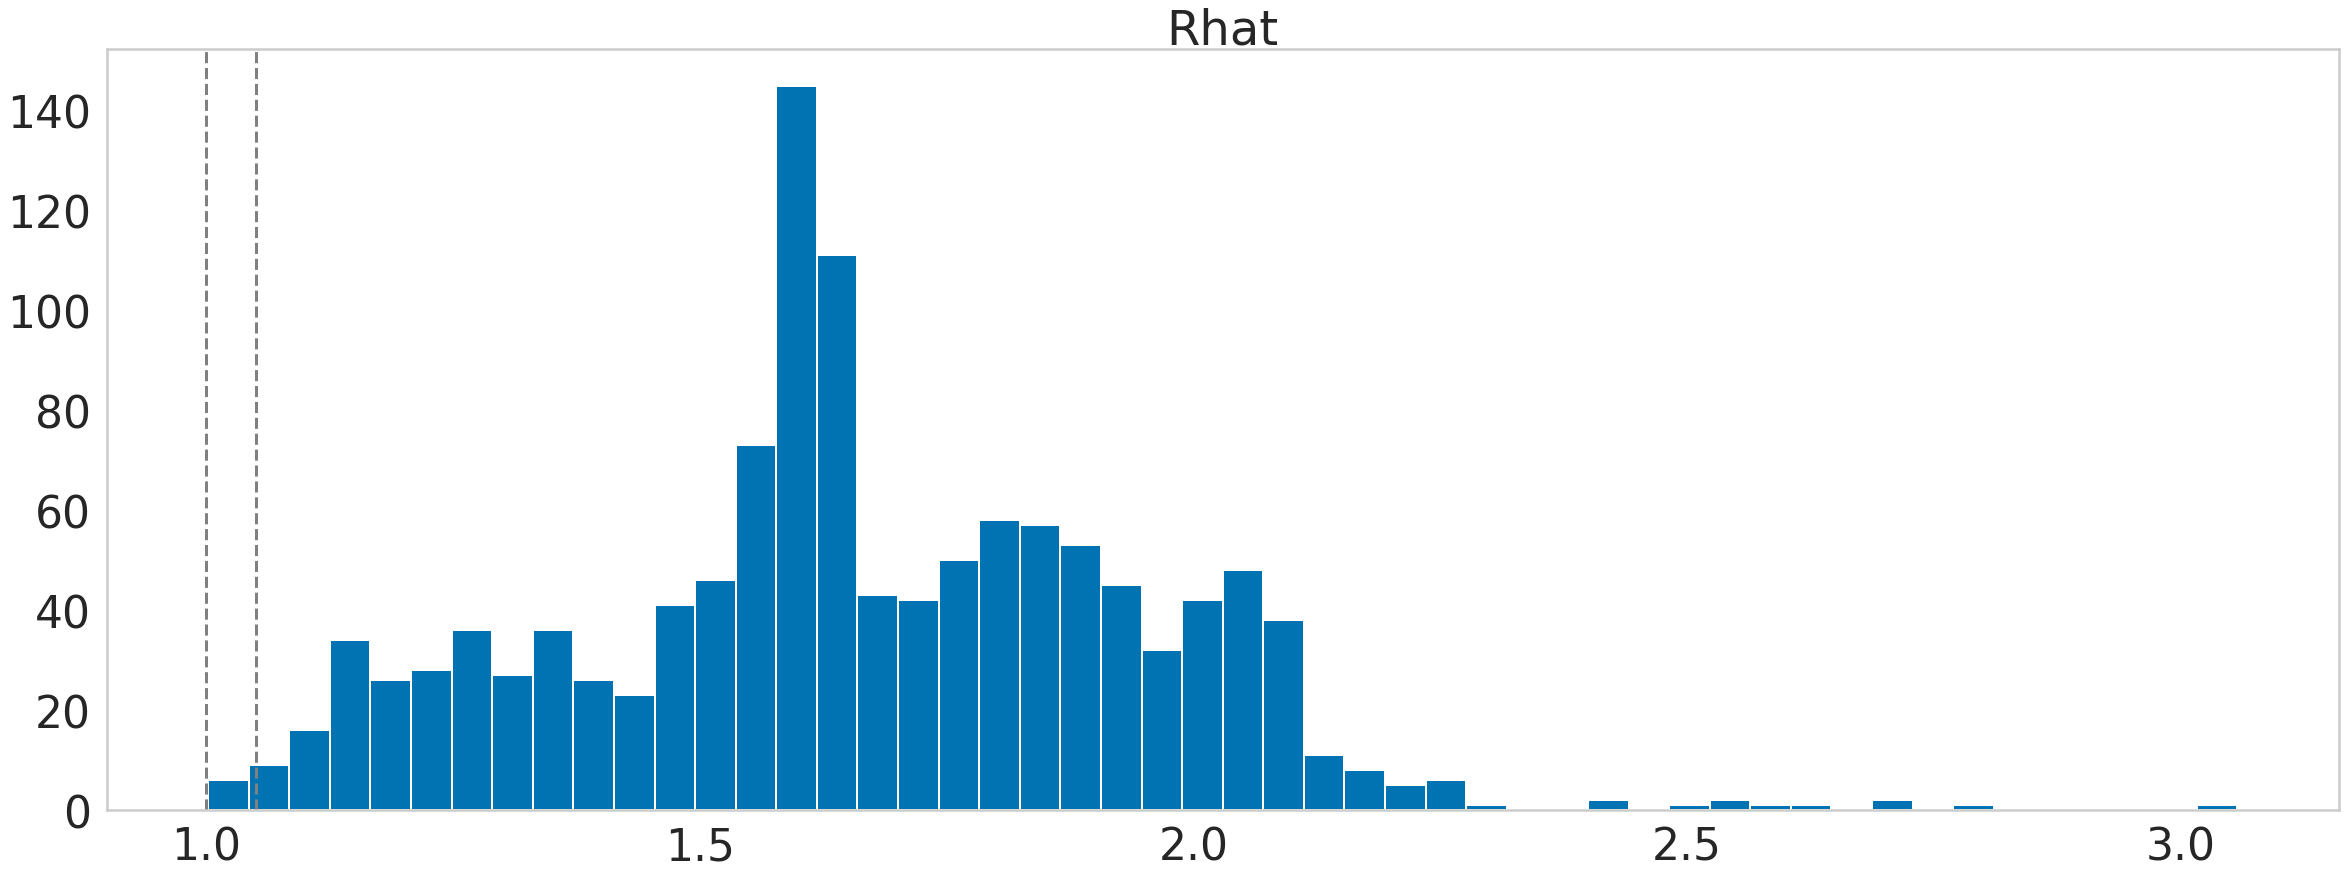

In [98]:
plt.figure()
plt.title('Rhat')
plt.hist(rhat_ls_norm_init_manual_sorted.values(),bins = 50)
plt.axvline(1.05,color="gray",linestyle="--",label=0.1)
# plt.axvline(0.5,color="gray",linestyle="--",label=0.1)
plt.axvline(1,color="gray",linestyle="--",label=0.1)
plt.grid()

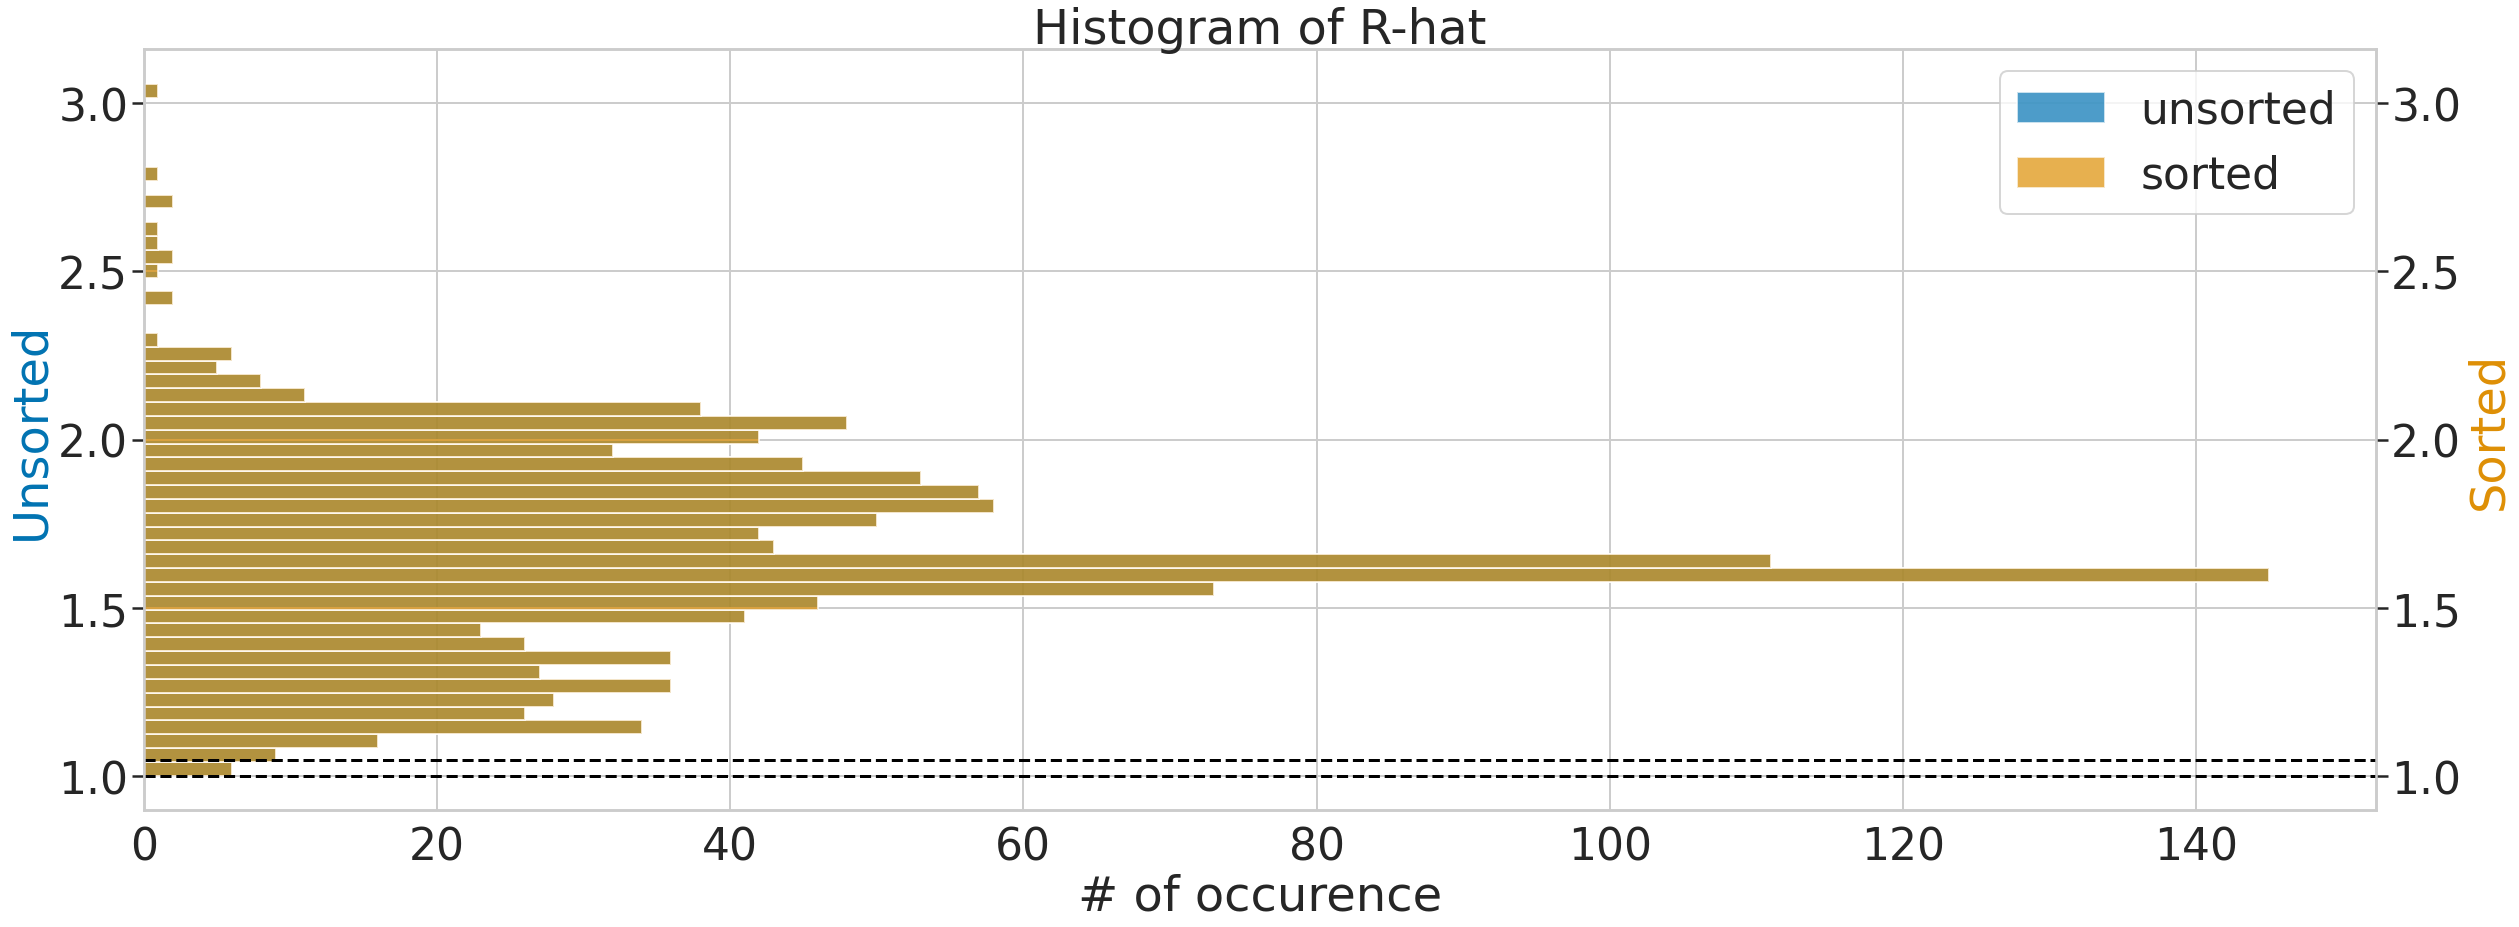

In [99]:
# create figure and axis objects with subplots()
fig,ax = plt.subplots()
# make a plot
ax.hist(rhat_ls_norm_init_manual.values(),bins = 50,color=palette[0],alpha=0.7,label="unsorted",orientation='horizontal')
# set x-axis label
ax.set_xlabel("# of occurence")
# set y-axis label
ax.set_ylabel("Unsorted",color=palette[0])
# twin object for two different y-axis on the sample plot
ax2=ax.twinx()
# make a plot with different y-axis using second axis object
ax2.hist(rhat_ls_norm_init_manual_sorted.values(),bins = 50,color=palette[1],alpha=0.7,label="sorted",orientation='horizontal')
ax2.set_ylabel("Sorted",color=palette[1])


lines, labels = ax.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax2.legend(lines + lines2, labels + labels2, loc=0)

plt.axhline(1.05,color="black",linestyle="--")
plt.axhline(1,color="black",linestyle="--")
# plt.legend()
plt.title("Histogram of R-hat")
plt.show()
